In [1]:
pip install xgboost


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install yellowbrick

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install scikit-plot


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
pip install imbalanced-learn


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Import

In [5]:
# Chuẩn bị các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
from sklearn.impute import KNNImputer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.base import clone
from sklearn.metrics import RocCurveDisplay
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_classif, chi2
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import learning_curve
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE
from sklearn.metrics import auc, roc_curve
from sklearn.preprocessing import label_binarize
from imblearn.over_sampling import SMOTENC

import warnings
warnings.filterwarnings('ignore')


# Prepare Dataset

In [6]:
df_cross = pd.read_csv('oasis_cross-sectional.csv')
df_long = pd.read_csv('oasis_longitudinal.csv')
df_long_copy = df_long.copy()
df_cross_copy = df_cross.copy()



# Explore Cross Dataset 

In [7]:
print("DATASET Cross SHAPE:")
print(f"Rows: {df_cross.shape[0]}, Columns: {df_cross.shape[1]}")
print("==="*30)
print("Tên cột:\n")
print(df_cross.columns)
print("==="*30)
print("Thông tin của df_cross\n")
print(df_cross.info())


DATASET Cross SHAPE:
Rows: 436, Columns: 12
Tên cột:

Index(['ID', 'M/F', 'Hand', 'Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV',
       'nWBV', 'ASF', 'Delay'],
      dtype='object')
Thông tin của df_cross

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 436 entries, 0 to 435
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ID      436 non-null    object 
 1   M/F     436 non-null    object 
 2   Hand    436 non-null    object 
 3   Age     436 non-null    int64  
 4   Educ    235 non-null    float64
 5   SES     216 non-null    float64
 6   MMSE    235 non-null    float64
 7   CDR     235 non-null    float64
 8   eTIV    436 non-null    int64  
 9   nWBV    436 non-null    float64
 10  ASF     436 non-null    float64
 11  Delay   20 non-null     float64
dtypes: float64(7), int64(2), object(3)
memory usage: 41.0+ KB
None


In [8]:
print(df_cross.head(10))

              ID M/F Hand  Age  Educ  SES  MMSE  CDR  eTIV   nWBV    ASF  \
0  OAS1_0001_MR1   F    R   74   2.0  3.0  29.0  0.0  1344  0.743  1.306   
1  OAS1_0002_MR1   F    R   55   4.0  1.0  29.0  0.0  1147  0.810  1.531   
2  OAS1_0003_MR1   F    R   73   4.0  3.0  27.0  0.5  1454  0.708  1.207   
3  OAS1_0004_MR1   M    R   28   NaN  NaN   NaN  NaN  1588  0.803  1.105   
4  OAS1_0005_MR1   M    R   18   NaN  NaN   NaN  NaN  1737  0.848  1.010   
5  OAS1_0006_MR1   F    R   24   NaN  NaN   NaN  NaN  1131  0.862  1.551   
6  OAS1_0007_MR1   M    R   21   NaN  NaN   NaN  NaN  1516  0.830  1.157   
7  OAS1_0009_MR1   F    R   20   NaN  NaN   NaN  NaN  1505  0.843  1.166   
8  OAS1_0010_MR1   M    R   74   5.0  2.0  30.0  0.0  1636  0.689  1.073   
9  OAS1_0011_MR1   F    R   52   3.0  2.0  30.0  0.0  1321  0.827  1.329   

   Delay  
0    NaN  
1    NaN  
2    NaN  
3    NaN  
4    NaN  
5    NaN  
6    NaN  
7    NaN  
8    NaN  
9    NaN  


In [9]:
# Summary statistics
cols_summary = ['Educ','SES','MMSE','CDR','eTIV','nWBV','ASF']
summary = df_cross[cols_summary].describe().T[['min','max','mean','50%']]
summary = summary.rename(columns={'50%':'median'})
print("Table of min, max, mean, median:")
display(summary)

Table of min, max, mean, median:


,min,max,mean,median
Educ,1.000,5.000,3.178723,3.000
SES,1.000,5.000,2.490741,2.000
MMSE,14.000,30.000,27.063830,29.000
CDR,0.000,2.000,0.285106,0.000
eTIV,1123.000,1992.000,1481.919725,1475.500
nWBV,0.644,0.893,0.791670,0.809
ASF,0.881,1.563,1.198894,1.190


In [10]:
print(df_cross['CDR'].value_counts(dropna=False))
print(df_cross['CDR'].unique())

CDR
NaN    201
0.0    135
0.5     70
1.0     28
2.0      2
Name: count, dtype: int64
[0.  0.5 nan 1.  2. ]


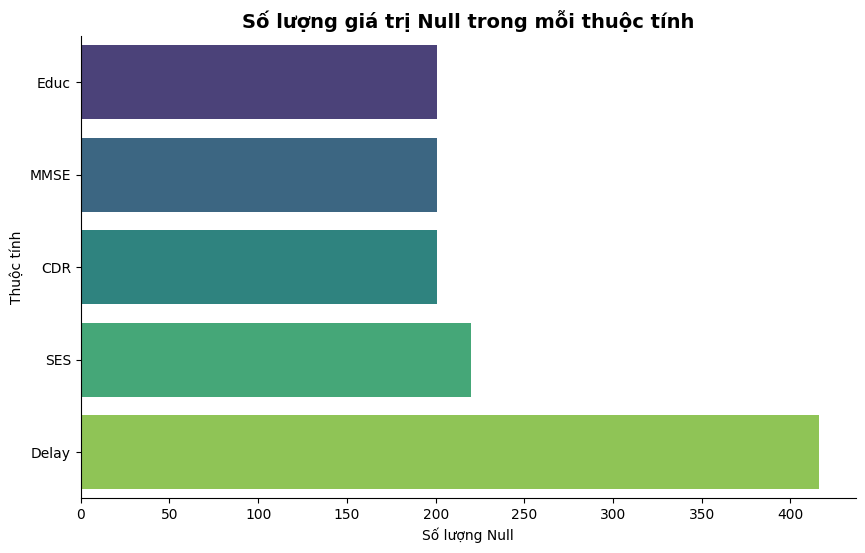

In [11]:
missing = df_cross.isnull().sum()
missing = missing[missing > 0]

missing_sorted = missing.sort_values(ascending=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=missing_sorted.values, 
    y=missing_sorted.index, 
    palette='viridis',
    hue=missing_sorted.index,
    legend=False
)

plt.title('Số lượng giá trị Null trong mỗi thuộc tính', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng Null')
plt.ylabel('Thuộc tính')
sns.despine() 
plt.show()

In [12]:
df_cross['Group_label'] = np.where(
    df_cross['CDR'] == 0,
    'Nondemented',
    np.where(
        df_cross['CDR'] == 0.5,
        'Very Mild Dementia',
        np.where(
            df_cross['CDR'] >= 1,
            'Demented',
            None
        )
    )
)

In [13]:
# Lọc bỏ None và trùng lặp
df_cross.drop_duplicates(inplace=True)
print(f"Shape :{df_cross.shape}")

Shape :(436, 13)


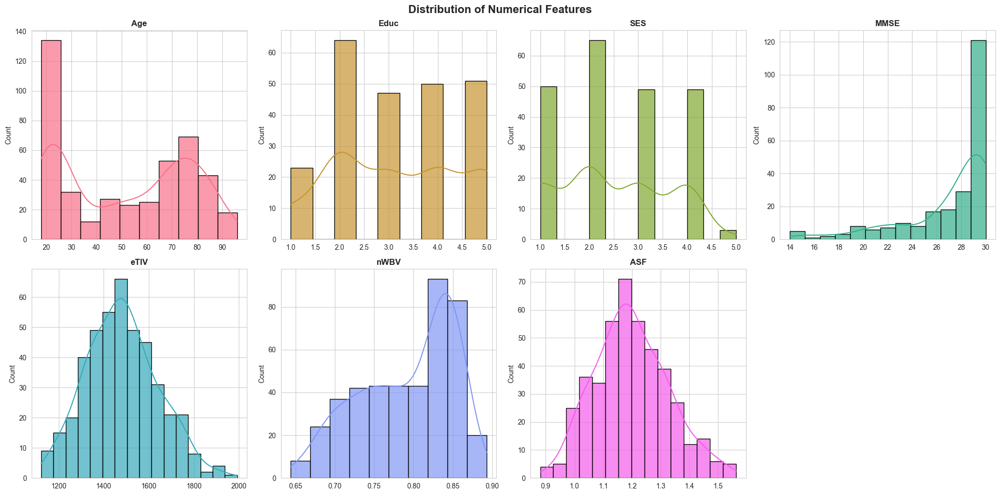

In [14]:

sns.set_style("whitegrid")

num_cols = (
    df_cross.select_dtypes(include='number')
    .drop(columns=['CDR', 'Group_label', 'Delay'], errors='ignore')
    .columns
)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

colors = sns.color_palette("husl", len(num_cols))

for ax, col, color in zip(axes, num_cols, colors):
    sns.histplot(
        df_cross[col],
        kde=True,
        ax=ax,
        color=color,
        edgecolor='black',
        alpha=0.7
    )

    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Count')

# Xóa ô thừa
for ax in axes[len(num_cols):]:
    fig.delaxes(ax)

plt.suptitle(
    'Distribution of Numerical Features',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

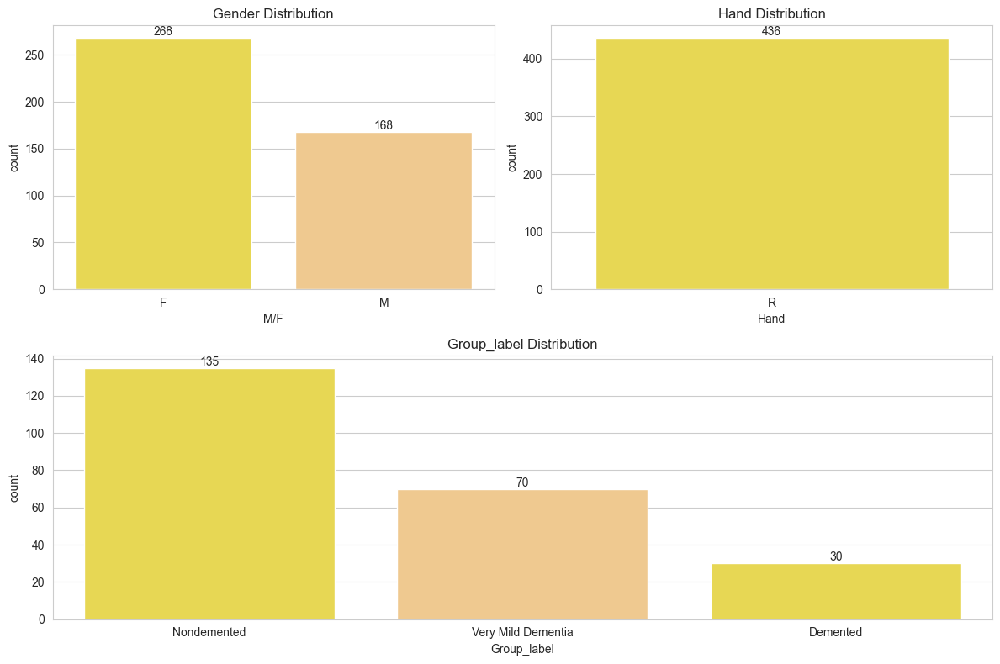

In [15]:

# Định nghĩa màu vàng nhạt và cam nhạt
summer_palette = ["#FFEB3B", "#FFCC80"] 

fig = plt.figure(figsize=(12, 8))
gs = GridSpec(2, 2, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

sns.countplot(data=df_cross, x='M/F', hue='M/F',
              palette=summer_palette, legend=False, ax=ax1, edgecolor=None)

sns.countplot(data=df_cross, x='Hand', hue='Hand',
              palette=summer_palette, legend=False, ax=ax2, edgecolor=None)

sns.countplot(data=df_cross, x='Group_label', hue='Group_label',
              palette=summer_palette, legend=False, ax=ax3, edgecolor=None)

ax1.set_title('Gender Distribution')
ax2.set_title('Hand Distribution')
ax3.set_title('Group_label Distribution')

for ax in [ax1, ax2, ax3]:
    for container in ax.containers:
        ax.bar_label(container, fmt='%d')

plt.tight_layout()
plt.show()

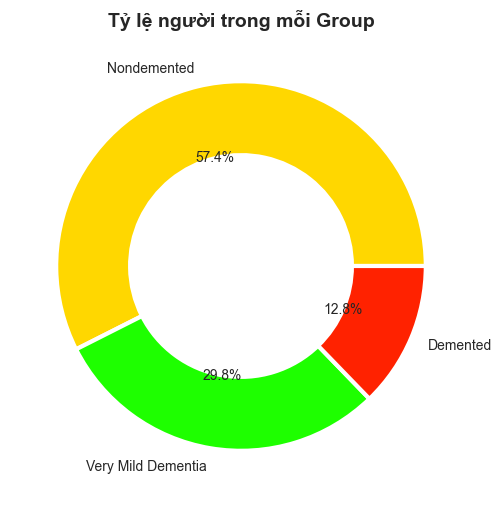

In [16]:

group_count = df_cross['Group_label'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(group_count.values, labels=group_count.index, autopct='%1.1f%%', 
        wedgeprops={'width': 0.4, 'edgecolor': 'white', 'linewidth': 3},
        colors=['#FFD700', "#1EFF00","#FF2200"])

plt.title('Tỷ lệ người trong mỗi Group', fontsize=14, fontweight='bold')
plt.show()

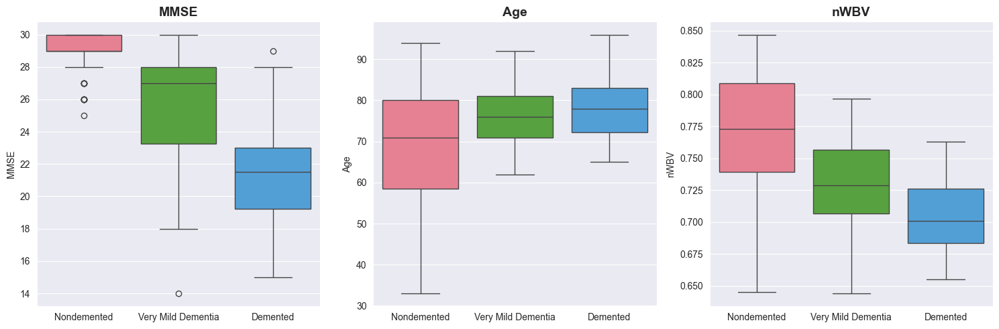

In [17]:
sns.set_style("darkgrid") 

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(data=df_cross, x='Group_label', y='MMSE', hue='Group_label',
            palette='husl', legend=False, ax=ax[0])
ax[0].set_title('MMSE', fontsize=14, fontweight='bold') 

sns.boxplot(data=df_cross, x='Group_label', y='Age', hue='Group_label',
            palette='husl', legend=False, ax=ax[1])
ax[1].set_title('Age', fontsize=14, fontweight='bold')

sns.boxplot(data=df_cross, x='Group_label', y='nWBV', hue='Group_label',
            palette='husl', legend=False, ax=ax[2])
ax[2].set_title('nWBV', fontsize=14, fontweight='bold')

for a in ax:
    a.set_xlabel('') 
    
plt.tight_layout()
plt.show()

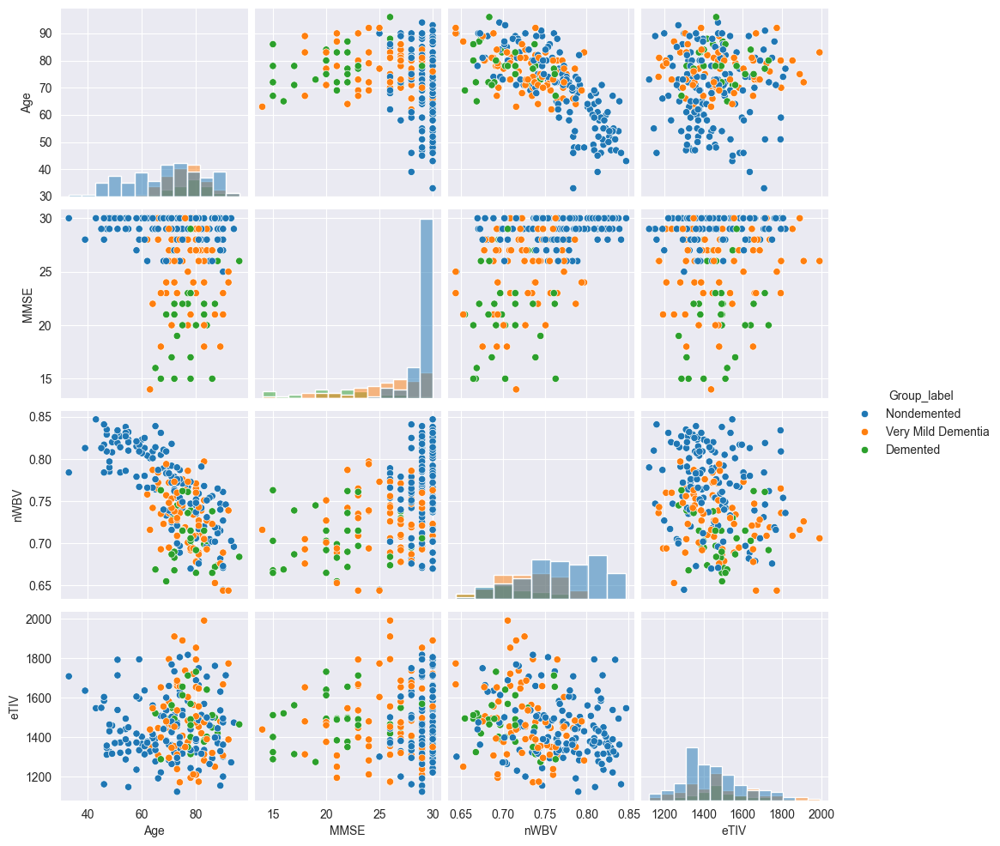

In [18]:
cols = ['Age', 'MMSE', 'nWBV', 'eTIV', 'Group_label']

sns.pairplot(
    df_cross[cols],
    hue='Group_label',
    diag_kind='hist'
)

plt.show()

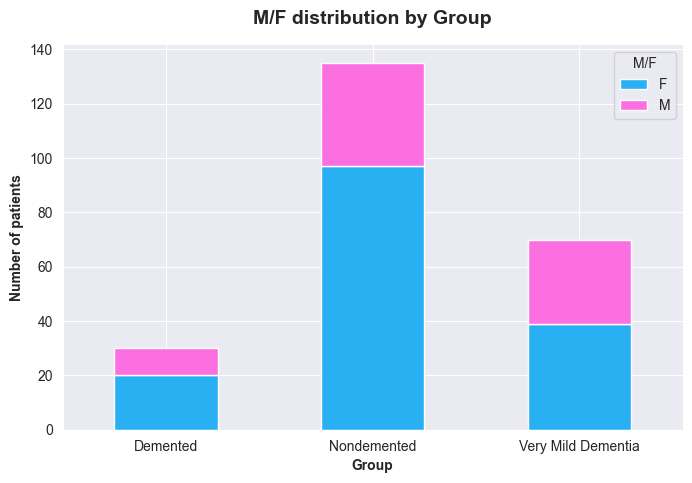

In [19]:
def bar_chart(feature):
    Demented = df_cross[df_cross['Group_label'] == 'Demented'][feature].value_counts()
    Nondemented = df_cross[df_cross['Group_label'] == 'Nondemented'][feature].value_counts()
    Very_Mild_Dementia = df_cross[df_cross['Group_label'] == 'Very Mild Dementia'][feature].value_counts()
    df_bar = pd.DataFrame([Demented, Nondemented,Very_Mild_Dementia])
    df_bar.index = ['Demented', 'Nondemented',"Very Mild Dementia"]

    df_bar.plot(
        kind='bar',
        stacked=True,
        figsize=(8, 5),
        color=["#29B0F3", "#FB6FE1"], 
        edgecolor=None              
    )

    plt.xlabel('Group', fontweight='bold')
    plt.ylabel('Number of patients', fontweight='bold')
    plt.title(f'{feature} distribution by Group', fontsize=14, fontweight='bold', pad=15)
    
    sns.despine()
    
    plt.xticks(rotation=0)
    
    plt.show()

bar_chart('M/F')

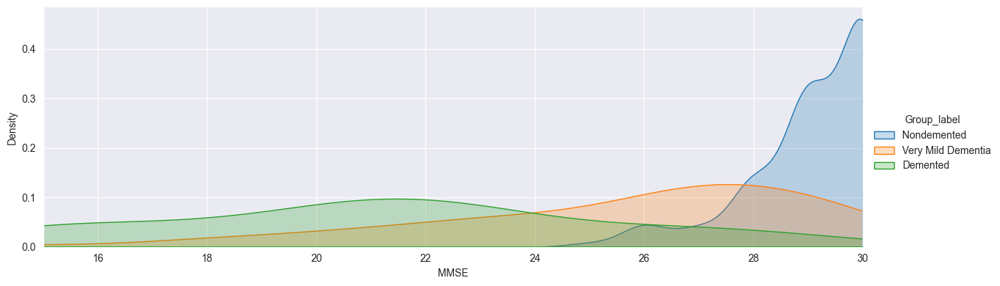

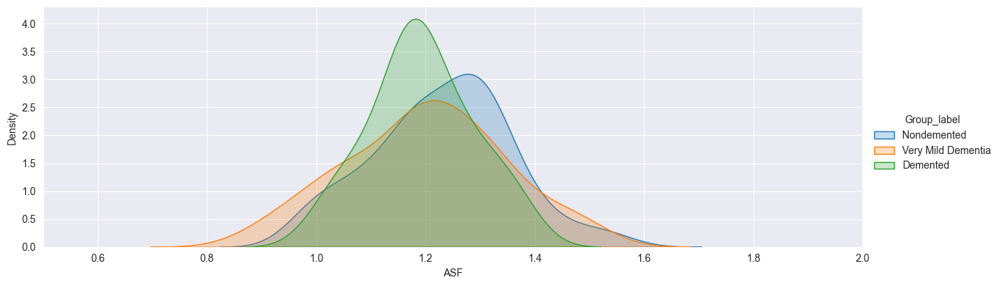

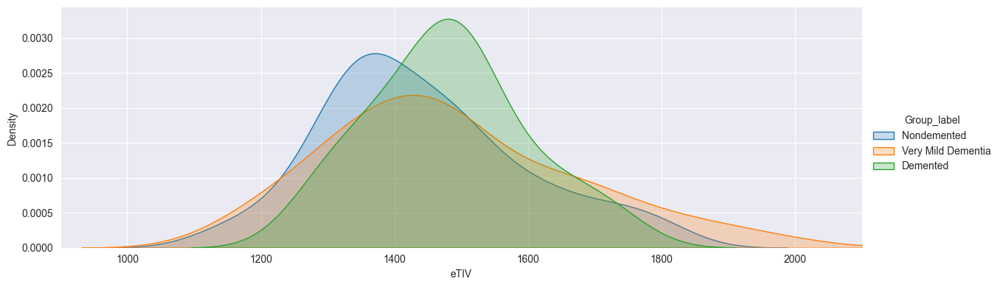

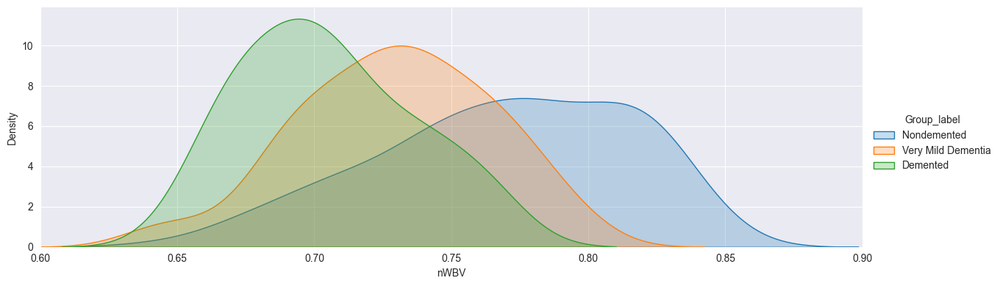

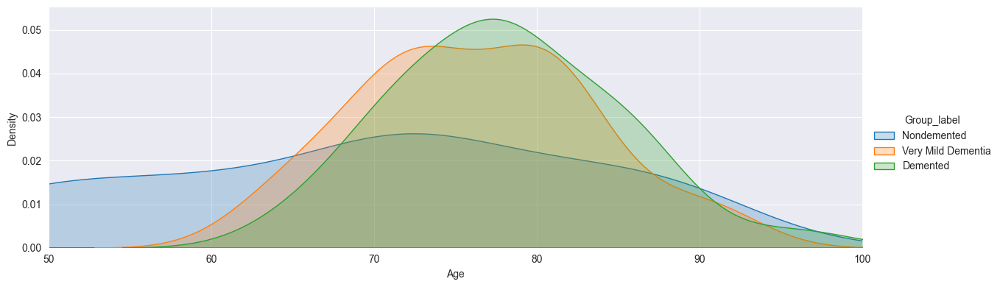

In [20]:
facet = sns.FacetGrid(df_cross, hue='Group_label', aspect=3, height=4)
facet.map(sns.kdeplot, 'MMSE', fill=True)
facet.set(xlim=(15, 30))
facet.add_legend()
plt.show()

facet = sns.FacetGrid(df_cross, hue='Group_label', aspect=3, height=4)
facet.map(sns.kdeplot, 'ASF', fill=True)
facet.set(xlim=(0.5, 2))
facet.add_legend()
plt.show()

facet = sns.FacetGrid(df_cross, hue='Group_label', aspect=3, height=4)
facet.map(sns.kdeplot, 'eTIV', fill=True)
facet.set(xlim=(900, 2100))
facet.add_legend()
plt.show()

facet = sns.FacetGrid(df_cross, hue='Group_label', aspect=3, height=4)
facet.map(sns.kdeplot, 'nWBV', fill=True)
facet.set(xlim=(0.6, 0.9))
facet.add_legend()
plt.show()

facet = sns.FacetGrid(df_cross, hue='Group_label', aspect=3, height=4)
facet.map(sns.kdeplot, 'Age', fill=True)
facet.set(xlim=(50, 100))
facet.add_legend()
plt.show()

facet.add_legend()
plt.show()

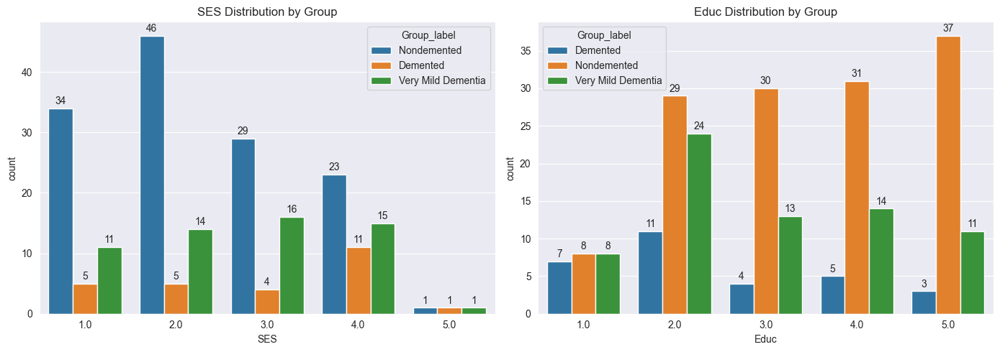

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# SES
sns.countplot(
    data=df_cross,
    x='SES',
    hue='Group_label',
    ax=axes[0]
)

axes[0].set_title('SES Distribution by Group')

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=2)


# EDUC
sns.countplot(
    data=df_cross,
    x='Educ',
    hue='Group_label',
    ax=axes[1]
)

axes[1].set_title('Educ Distribution by Group')

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%d', padding=2)

plt.tight_layout()
plt.show()

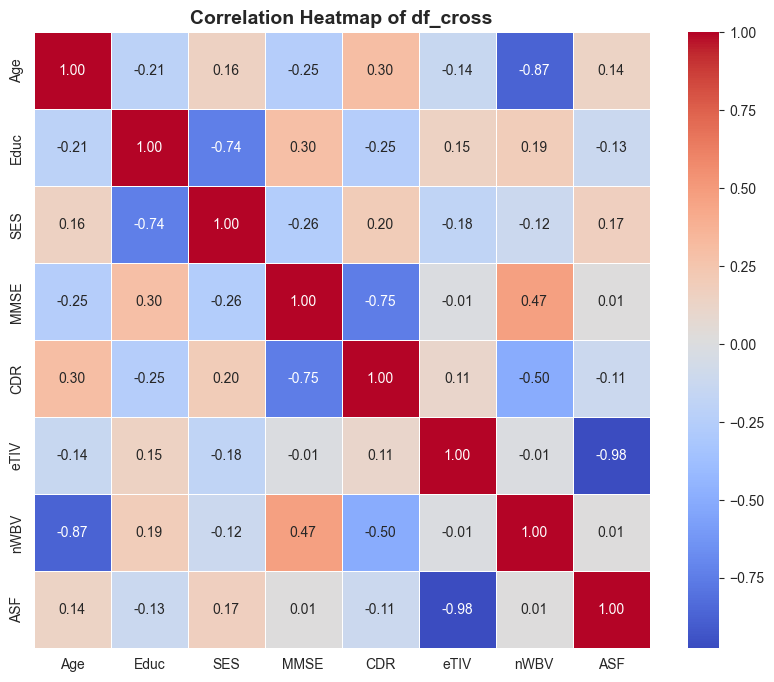

In [22]:

numeric_df = df_cross.select_dtypes(include=['number']).drop(columns=['Delay'])

corr_matrix = numeric_df.corr()

# Vẽ heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    square=True,
    linewidths=0.5
)

plt.title('Correlation Heatmap of df_cross', fontsize=14, fontweight='bold')
plt.show()

# Explore Long Dataset 

In [23]:
print("DATASET Long SHAPE:")
print(f"Rows: {df_long.shape[0]}, Columns: {df_long.shape[1]}")
print("==="*30)
print("Tên cột:\n")
print(df_long.columns)
print("==="*30)
print("Thông tin của df_long\n")
print(df_long.info())

DATASET Long SHAPE:
Rows: 373, Columns: 15
Tên cột:

Index(['Subject ID', 'MRI ID', 'Group', 'Visit', 'MR Delay', 'M/F', 'Hand',
       'Age', 'EDUC', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF'],
      dtype='object')
Thông tin của df_long

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 373 entries, 0 to 372
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Subject ID  373 non-null    object 
 1   MRI ID      373 non-null    object 
 2   Group       373 non-null    object 
 3   Visit       373 non-null    int64  
 4   MR Delay    373 non-null    int64  
 5   M/F         373 non-null    object 
 6   Hand        373 non-null    object 
 7   Age         373 non-null    int64  
 8   EDUC        373 non-null    int64  
 9   SES         354 non-null    float64
 10  MMSE        371 non-null    float64
 11  CDR         373 non-null    float64
 12  eTIV        373 non-null    int64  
 13  nWBV        373 non-null    float

In [24]:
# Summary statistics
cols_summary = ['EDUC','SES','MMSE','eTIV','nWBV','ASF']
summary = df_long[cols_summary].describe().T[['min','max','mean','50%']]
summary = summary.rename(columns={'50%':'median'})
print("Table of min, max, mean, median:")
display(summary)

Table of min, max, mean, median:


,min,max,mean,median
EDUC,6.000,23.000,14.597855,15.000
SES,1.000,5.000,2.460452,2.000
MMSE,4.000,30.000,27.342318,29.000
eTIV,1106.000,2004.000,1488.128686,1470.000
nWBV,0.644,0.837,0.729568,0.729
ASF,0.876,1.587,1.195461,1.194


In [25]:
print(df_long.head(10))

  Subject ID         MRI ID        Group  Visit  MR Delay M/F Hand  Age  EDUC  \
0  OAS2_0001  OAS2_0001_MR1  Nondemented      1         0   M    R   87    14   
1  OAS2_0001  OAS2_0001_MR2  Nondemented      2       457   M    R   88    14   
2  OAS2_0002  OAS2_0002_MR1     Demented      1         0   M    R   75    12   
3  OAS2_0002  OAS2_0002_MR2     Demented      2       560   M    R   76    12   
4  OAS2_0002  OAS2_0002_MR3     Demented      3      1895   M    R   80    12   
5  OAS2_0004  OAS2_0004_MR1  Nondemented      1         0   F    R   88    18   
6  OAS2_0004  OAS2_0004_MR2  Nondemented      2       538   F    R   90    18   
7  OAS2_0005  OAS2_0005_MR1  Nondemented      1         0   M    R   80    12   
8  OAS2_0005  OAS2_0005_MR2  Nondemented      2      1010   M    R   83    12   
9  OAS2_0005  OAS2_0005_MR3  Nondemented      3      1603   M    R   85    12   

   SES  MMSE  CDR  eTIV   nWBV    ASF  
0  2.0  27.0  0.0  1987  0.696  0.883  
1  2.0  30.0  0.0  2004  0.6

In [26]:
print(df_long['Group'].value_counts(dropna=False))
print(df_long['Group'].unique())

Group
Nondemented    190
Demented       146
Converted       37
Name: count, dtype: int64
['Nondemented' 'Demented' 'Converted']


In [27]:
# Lọc bỏ trùng lặp
df_long.drop_duplicates(inplace=True)
print(f"Shape :{df_long.shape}")

Shape :(373, 15)


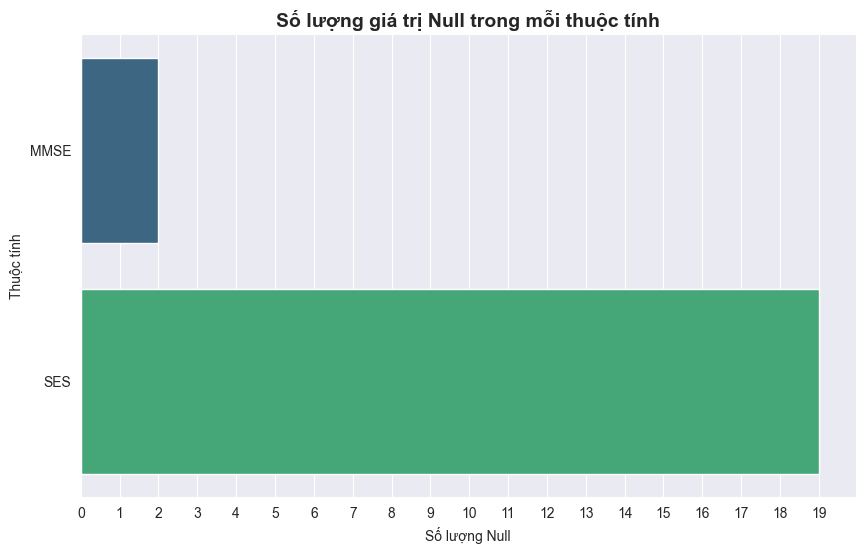

In [28]:
missing = df_long.isnull().sum()
missing = missing[missing > 0]

missing_sorted = missing.sort_values(ascending=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=missing_sorted.values, 
    y=missing_sorted.index, 
    palette='viridis',
    hue=missing_sorted.index,
    legend=False
)

plt.xticks(range(0,  missing_sorted.max() + 1))

plt.title('Số lượng giá trị Null trong mỗi thuộc tính', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng Null')
plt.ylabel('Thuộc tính')
sns.despine() 
plt.show()

In [29]:
df_long['Group_label'] = np.where(
    df_long['CDR'] == 0,
    'Nondemented',
    np.where(
        df_long['CDR'] == 0.5,
        'Very Mild Dementia',
        np.where(
            df_long['CDR'] >= 1,
            'Demented',
            None
        )
    )
)

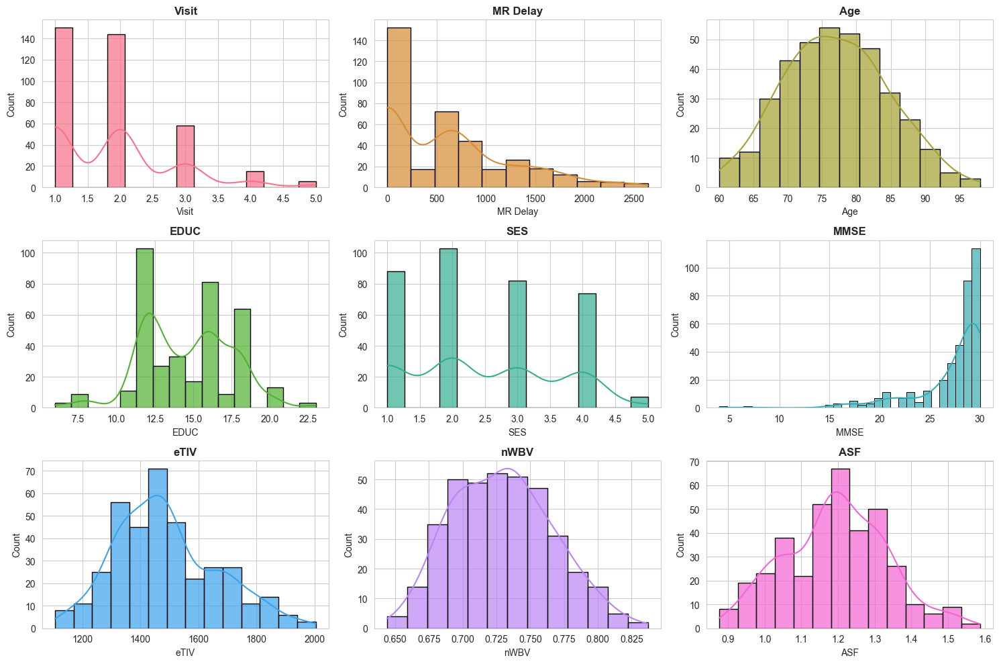

In [30]:
sns.set_style("whitegrid")

num_cols = df_long.select_dtypes(include='number').drop(columns='CDR', errors='ignore').columns
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

colors = sns.color_palette("husl", len(num_cols))

for ax, col, color in zip(axes.flatten(), num_cols, colors):
    sns.histplot(df_long[col], kde=True, ax=ax, color=color, edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

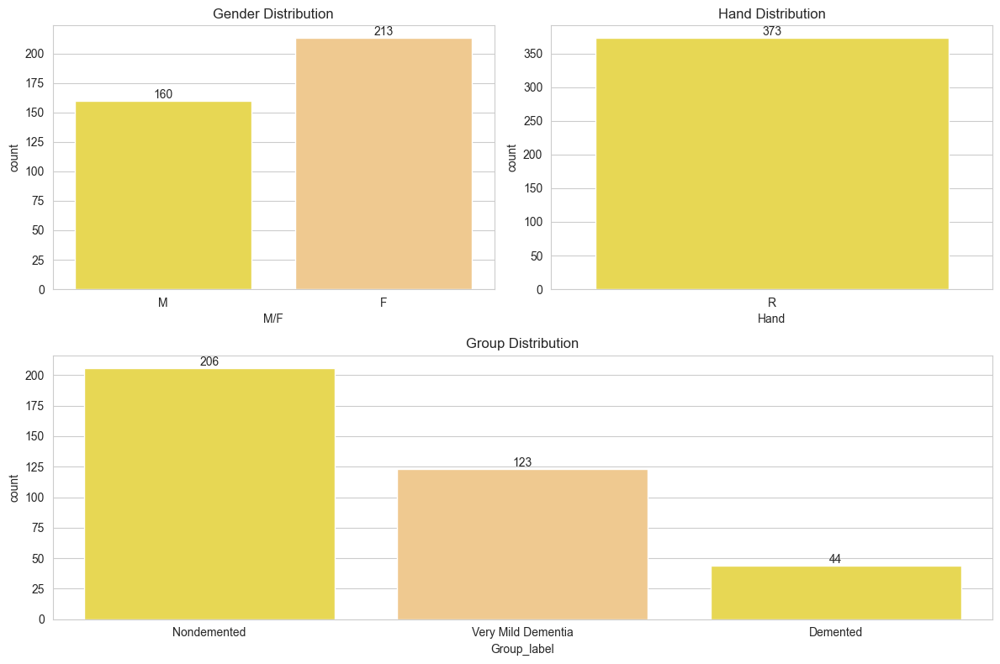

In [31]:
summer_palette = ["#FFEB3B", "#FFCC80"] 

fig = plt.figure(figsize=(12, 8))
gs = GridSpec(2, 2, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

sns.countplot(data=df_long, x='M/F', hue='M/F',
              palette=summer_palette, legend=False, ax=ax1, edgecolor=None)

sns.countplot(data=df_long, x='Hand', hue='Hand',
              palette=summer_palette, legend=False, ax=ax2, edgecolor=None)

sns.countplot(data=df_long, x='Group_label', hue='Group_label',
              palette=summer_palette, legend=False, ax=ax3, edgecolor=None)

ax1.set_title('Gender Distribution')
ax2.set_title('Hand Distribution')
ax3.set_title('Group Distribution')

for ax in [ax1, ax2, ax3]:
    for container in ax.containers:
        ax.bar_label(container, fmt='%d')

plt.tight_layout()
plt.show()

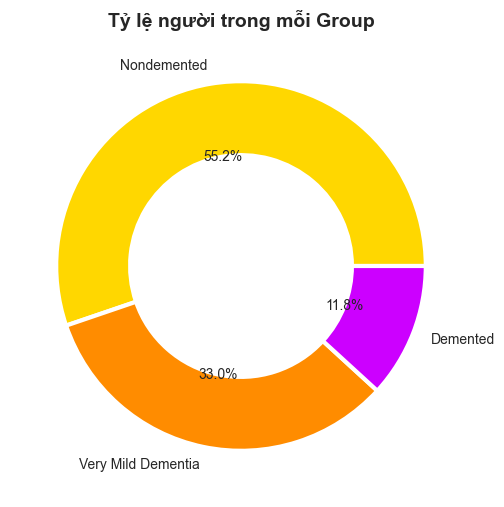

In [32]:
group_count = df_long['Group_label'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(group_count.values, labels=group_count.index, autopct='%1.1f%%', 
        wedgeprops={'width': 0.4, 'edgecolor': 'white', 'linewidth': 3},
        colors=['#FFD700', '#FF8C00',"#CC00FF"])

plt.title('Tỷ lệ người trong mỗi Group', fontsize=14, fontweight='bold')
plt.show()

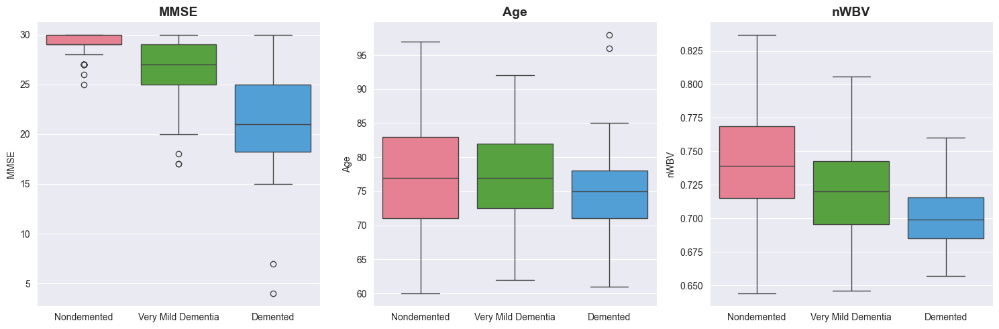

In [33]:
sns.set_style("darkgrid") 

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(data=df_long, x='Group_label', y='MMSE', hue='Group_label',
            palette='husl', legend=False, ax=ax[0])
ax[0].set_title('MMSE', fontsize=14, fontweight='bold') 

sns.boxplot(data=df_long, x='Group_label', y='Age', hue='Group_label',
            palette='husl', legend=False, ax=ax[1])
ax[1].set_title('Age', fontsize=14, fontweight='bold')

sns.boxplot(data=df_long, x='Group_label', y='nWBV', hue='Group_label',
            palette='husl', legend=False, ax=ax[2])
ax[2].set_title('nWBV', fontsize=14, fontweight='bold')

for a in ax:
    a.set_xlabel('') 
    
plt.tight_layout()
plt.show()

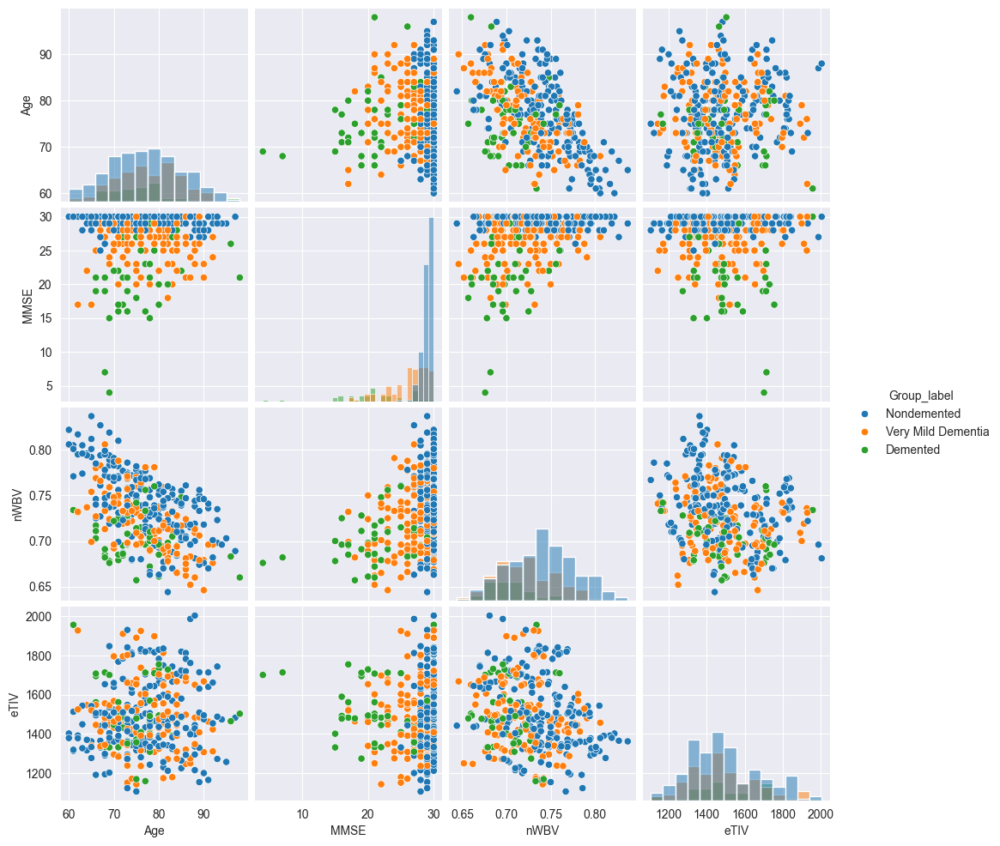

In [34]:
cols = ['Age', 'MMSE', 'nWBV', 'eTIV', 'Group_label']

sns.pairplot(
    df_long[cols],
    hue='Group_label',
    diag_kind='hist'
)

plt.show()

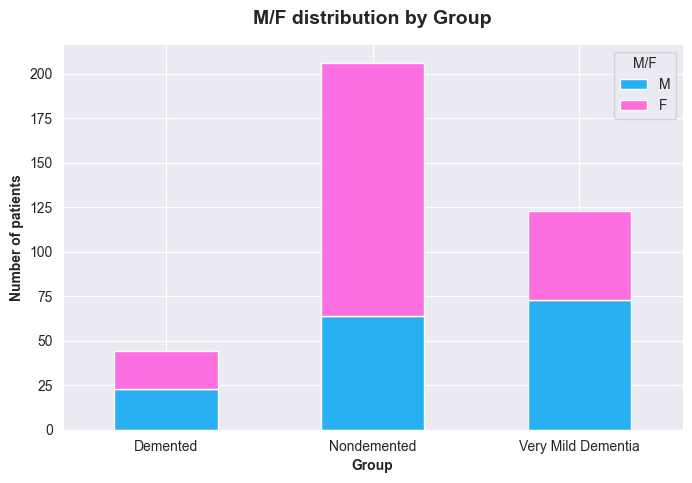

In [35]:
def bar_chart(feature):
    Demented = df_long[df_long['Group_label'] == 'Demented'][feature].value_counts()
    Nondemented = df_long[df_long['Group_label'] == 'Nondemented'][feature].value_counts()
    Very_Mild_Dementia = df_long[df_long['Group_label'] == 'Very Mild Dementia'][feature].value_counts()

    df_bar = pd.DataFrame([Demented, Nondemented,Very_Mild_Dementia])
    df_bar.index = ['Demented', 'Nondemented', "Very Mild Dementia"]

    df_bar.plot(
        kind='bar',
        stacked=True,
        figsize=(8, 5),
        color=["#29B0F3", "#FB6FE1"], 
        edgecolor=None              
    )

    plt.xlabel('Group', fontweight='bold')
    plt.ylabel('Number of patients', fontweight='bold')
    plt.title(f'{feature} distribution by Group', fontsize=14, fontweight='bold', pad=15)
    
    sns.despine()
    
    plt.xticks(rotation=0)
    
    plt.show()

bar_chart('M/F')

(0.0, 0.2)

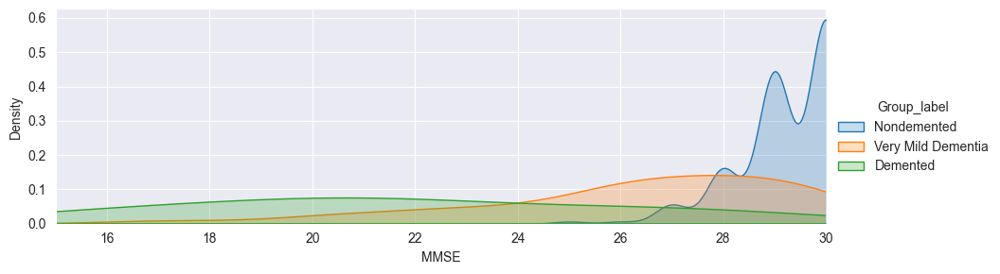

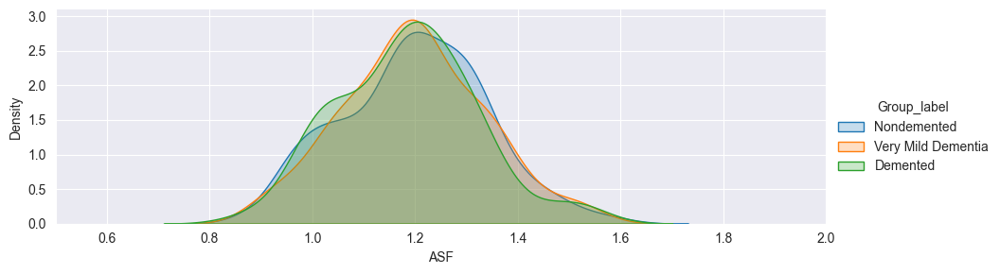

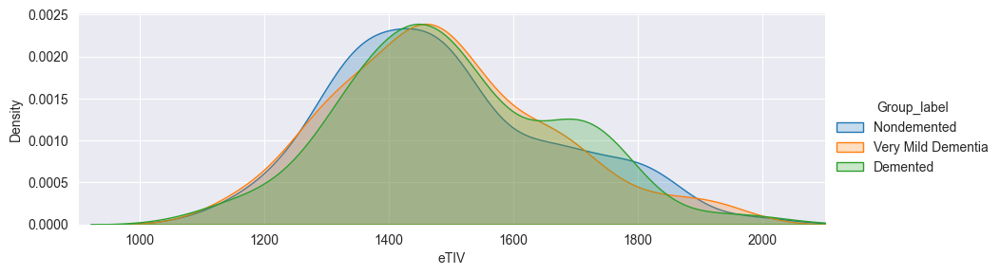

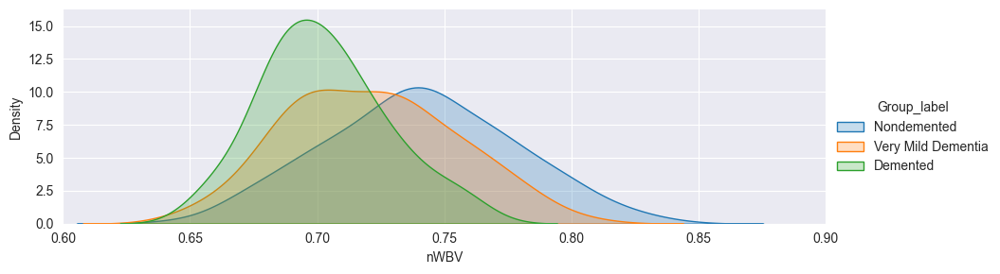

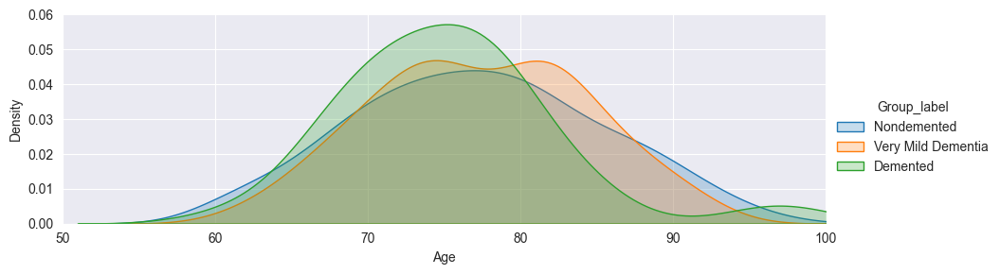

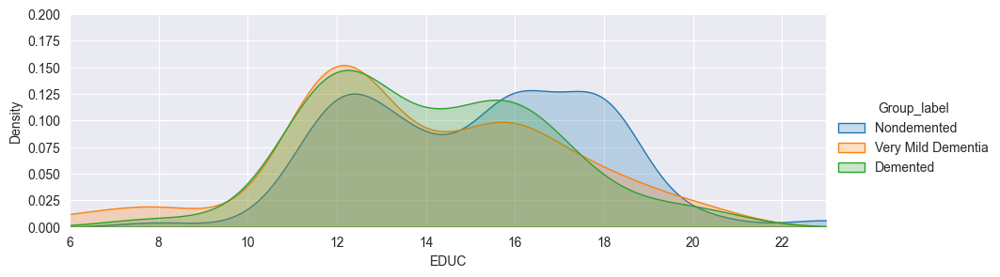

In [36]:

# KDE plots for selected features
facet = sns.FacetGrid(df_long, hue='Group_label', aspect=3)
facet.map(sns.kdeplot, 'MMSE', fill=True)
facet.set(xlim=(0, df_long['MMSE'].max()))
facet.add_legend()
plt.xlim(15, 30)
 
facet = sns.FacetGrid(df_long, hue='Group_label', aspect=3)
facet.map(sns.kdeplot, 'ASF', fill=True)
facet.set(xlim=(0, df_long['ASF'].max()))
facet.add_legend()
plt.xlim(0.5, 2)

facet = sns.FacetGrid(df_long, hue='Group_label', aspect=3)
facet.map(sns.kdeplot, 'eTIV', fill=True)
facet.set(xlim=(0, df_long['eTIV'].max()))
facet.add_legend()
plt.xlim(900, 2100)

facet = sns.FacetGrid(df_long, hue='Group_label', aspect=3)
facet.map(sns.kdeplot, 'nWBV', fill=True)
facet.set(xlim=(0, df_long['nWBV'].max()))
facet.add_legend()
plt.xlim(0.6, 0.9)

facet = sns.FacetGrid(df_long, hue='Group_label', aspect=3)
facet.map(sns.kdeplot, 'Age', fill=True)
facet.set(xlim=(0, df_long['Age'].max()))
facet.add_legend()
plt.xlim(50, 100)

facet = sns.FacetGrid(df_long, hue='Group_label', aspect=3)
facet.map(sns.kdeplot, 'EDUC', fill=True)
facet.set(xlim=(df_long['EDUC'].min(), df_long['EDUC'].max()))
facet.add_legend()
plt.ylim(0, 0.2)

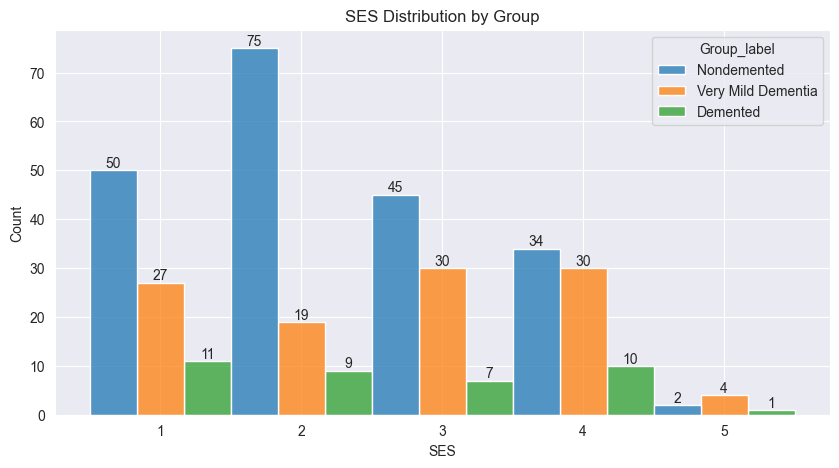

In [37]:
plt.figure(figsize=(10,5))

ax = sns.histplot(
    data=df_long,
    x='SES',
    hue='Group_label',
    multiple='dodge',
    discrete=True
)

for patch in ax.patches:
    height = patch.get_height()
    if height > 0:
        ax.text(
            patch.get_x() + patch.get_width()/2,
            height,
            int(height),
            ha='center',
            va='bottom'
        )

plt.title('SES Distribution by Group')
plt.show()

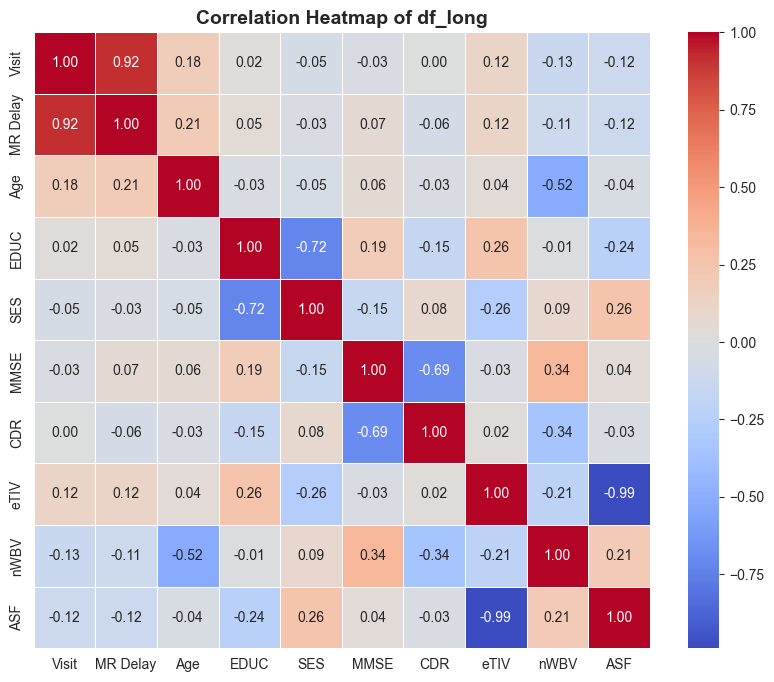

In [38]:

numeric_df = df_long.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()

# Vẽ heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    square=True,
    linewidths=0.5
)

plt.title('Correlation Heatmap of df_long', fontsize=14, fontweight='bold')
plt.show()

# Explore Dataset Combine with 2 label

In [39]:
# Xử lý đồng bộ cột học vấn cho df_cross (Quy đổi cấp học thành số năm)
mapping_educ = {1: 5, 2: 9, 3: 12, 4: 16, 5: 18}
df_cross_copy['EDUC'] = df_cross_copy['Educ'].map(mapping_educ)

# Đồng bộ các cột khác và tự tạo Group cho df_cross như các bước trước
df_cross_copy = df_cross_copy.rename(columns={'ID': 'Subject ID', 'Delay': 'MR Delay'})
df_cross_copy['Visit'] = 1
df_cross_copy['MRI ID'] = df_cross_copy['Subject ID']

In [40]:
df_cross_copy['Group'] = np.where(
    df_cross_copy['CDR'] == 0,
    'Nondemented',
    np.where(
        df_cross_copy['CDR'] >= 0.5,
        'Demented',
        None
    )
)

In [41]:
# Gộp 2 file lại với nhau
columns_to_keep = ['Subject ID', 'MRI ID', 'Group', 'Visit', 'MR Delay', 'M/F', 'Hand', 'Age', 'EDUC', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF']
df_combined = pd.concat([df_long_copy[columns_to_keep], df_cross_copy[columns_to_keep]], axis=0, ignore_index=True)

In [42]:
df_combined['Group'] = df_combined['Group'].replace(['Converted'], 'Demented')

In [43]:
print(f"Shape của dataset sau khi gộp 2 file.csv là: {df_combined.shape}")
print(f"Các chỉ số của dataset:\n")
print(df_combined.info())
print("==="*30)
df_combined.isnull().sum()

Shape của dataset sau khi gộp 2 file.csv là: (809, 15)
Các chỉ số của dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 809 entries, 0 to 808
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Subject ID  809 non-null    object 
 1   MRI ID      809 non-null    object 
 2   Group       608 non-null    object 
 3   Visit       809 non-null    int64  
 4   MR Delay    393 non-null    float64
 5   M/F         809 non-null    object 
 6   Hand        809 non-null    object 
 7   Age         809 non-null    int64  
 8   EDUC        608 non-null    float64
 9   SES         570 non-null    float64
 10  MMSE        606 non-null    float64
 11  CDR         608 non-null    float64
 12  eTIV        809 non-null    int64  
 13  nWBV        809 non-null    float64
 14  ASF         809 non-null    float64
dtypes: float64(7), int64(3), object(5)
memory usage: 94.9+ KB
None


Subject ID      0
MRI ID          0
Group         201
Visit           0
MR Delay      416
M/F             0
Hand            0
Age             0
EDUC          201
SES           239
MMSE          203
CDR           201
eTIV            0
nWBV            0
ASF             0
dtype: int64

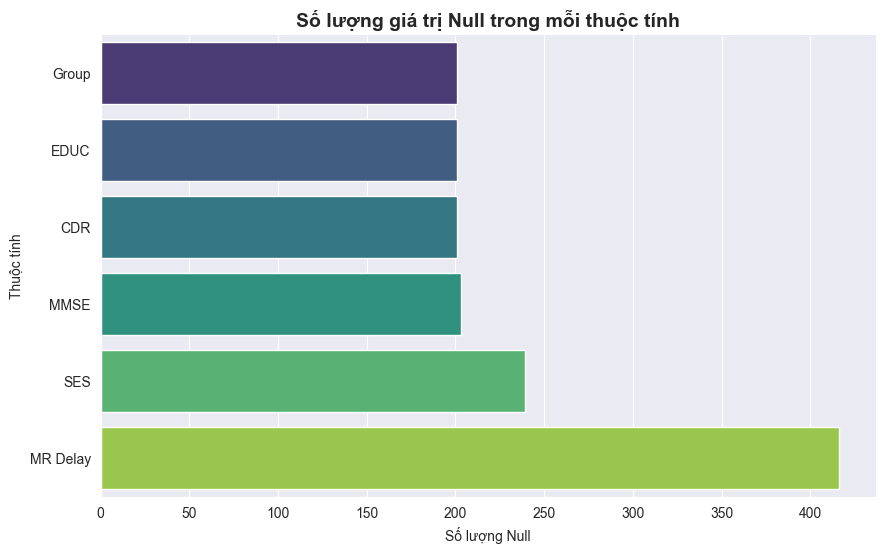

In [44]:
missing = df_combined.isnull().sum()
missing = missing[missing > 0]

missing_sorted = missing.sort_values(ascending=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=missing_sorted.values, 
    y=missing_sorted.index, 
    palette='viridis',
    hue=missing_sorted.index,
    legend=False
)

plt.title('Số lượng giá trị Null trong mỗi thuộc tính', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng Null')
plt.ylabel('Thuộc tính')
sns.despine() 
plt.show()

In [45]:
# trùng lặp
df_combined.dropna(subset=['Group'], inplace=True)
df_combined.drop_duplicates(inplace=True)
print(f"Shape :{df_combined.shape}")

Shape :(608, 15)


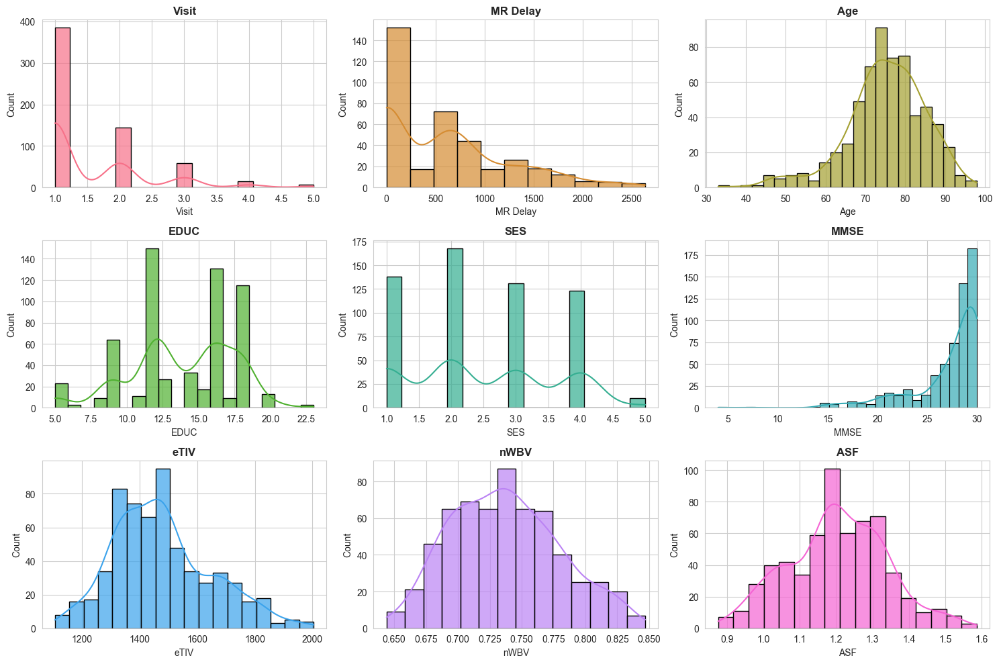

In [46]:
sns.set_style("whitegrid")

num_cols = df_combined.select_dtypes(include='number').drop(columns='CDR', errors='ignore').columns
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

colors = sns.color_palette("husl", len(num_cols))

for ax, col, color in zip(axes.flatten(), num_cols, colors):
    sns.histplot(df_combined[col], kde=True, ax=ax, color=color, edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

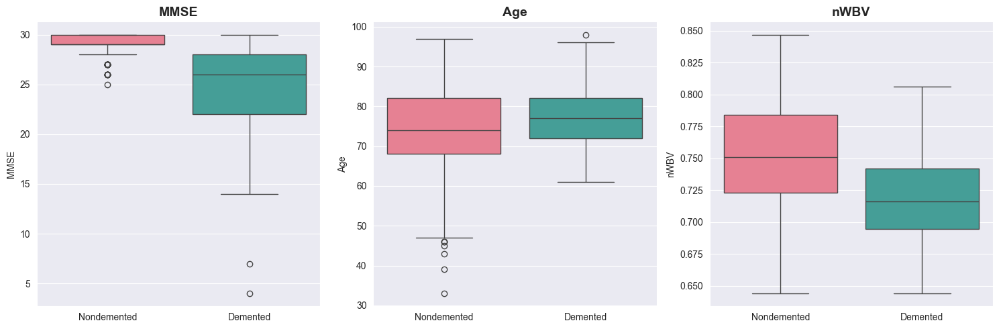

In [47]:
sns.set_style("darkgrid") 

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(data=df_combined, x='Group', y='MMSE', hue='Group',
            palette='husl', legend=False, ax=ax[0])
ax[0].set_title('MMSE', fontsize=14, fontweight='bold') 

sns.boxplot(data=df_combined, x='Group', y='Age', hue='Group',
            palette='husl', legend=False, ax=ax[1])
ax[1].set_title('Age', fontsize=14, fontweight='bold')

sns.boxplot(data=df_combined, x='Group', y='nWBV', hue='Group',
            palette='husl', legend=False, ax=ax[2])
ax[2].set_title('nWBV', fontsize=14, fontweight='bold')

for a in ax:
    a.set_xlabel('') 
    
plt.tight_layout()
plt.show()

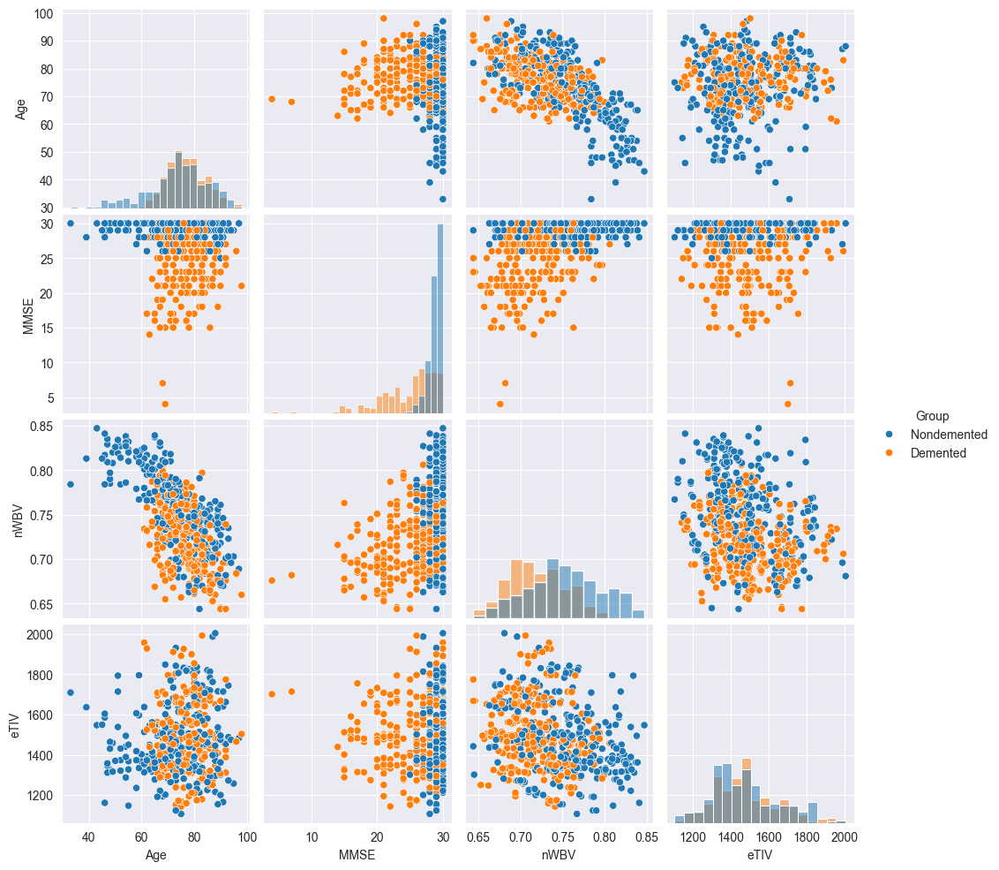

In [48]:
cols = ['Age', 'MMSE', 'nWBV', 'eTIV', 'Group']

sns.pairplot(
    df_combined[cols],
    hue='Group',
    diag_kind='hist'
)

plt.show()

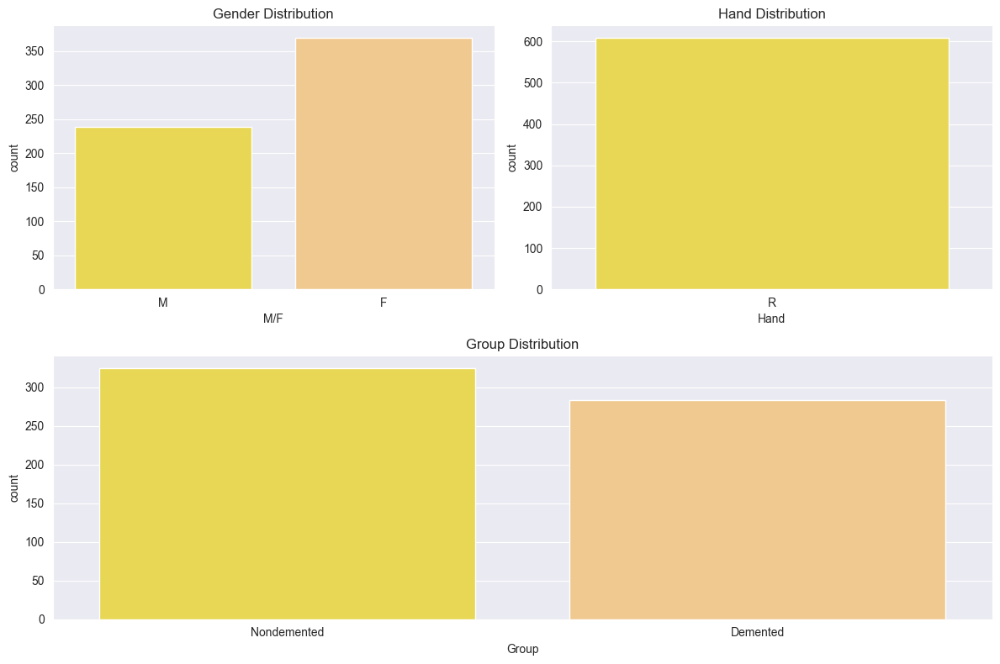

In [49]:

summer_palette = ["#FFEB3B", "#FFCC80"] 

fig = plt.figure(figsize=(12, 8))
gs = GridSpec(2, 2, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

sns.countplot(data=df_combined, x='M/F', hue='M/F',
              palette=summer_palette, legend=False, ax=ax1, edgecolor=None)

sns.countplot(data=df_combined, x='Hand', hue='Hand',
              palette=summer_palette, legend=False, ax=ax2, edgecolor=None)

sns.countplot(data=df_combined, x='Group', hue='Group',
              palette=summer_palette, legend=False, ax=ax3, edgecolor=None)

ax1.set_title('Gender Distribution')
ax2.set_title('Hand Distribution')
ax3.set_title('Group Distribution')

plt.tight_layout()
plt.show()

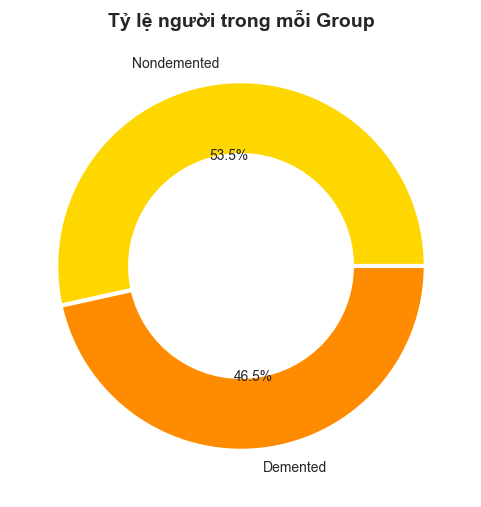

In [50]:
group_count = df_combined['Group'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(group_count.values, labels=group_count.index, autopct='%1.1f%%', 
        wedgeprops={'width': 0.4, 'edgecolor': 'white', 'linewidth': 3},
        colors=['#FFD700', '#FF8C00'])

plt.title('Tỷ lệ người trong mỗi Group', fontsize=14, fontweight='bold')
plt.show()

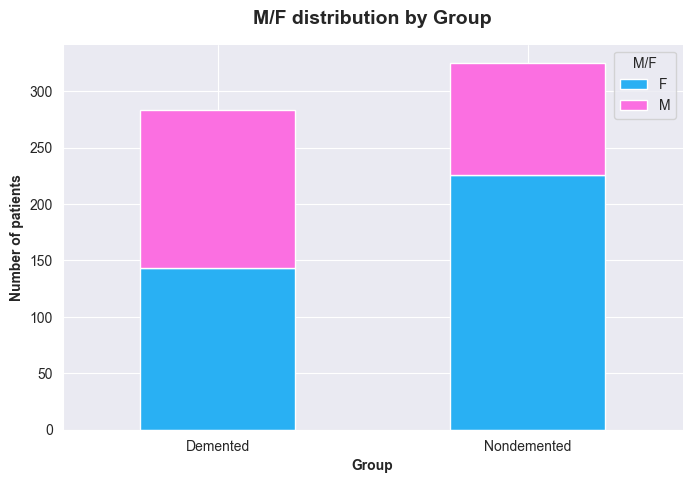

In [51]:
def bar_chart(feature):
    Demented = df_combined[df_combined['Group'] == 'Demented'][feature].value_counts()
    Nondemented = df_combined[df_combined['Group'] == 'Nondemented'][feature].value_counts()

    df_bar = pd.DataFrame([Demented, Nondemented])
    df_bar.index = ['Demented', 'Nondemented']

    df_bar.plot(
        kind='bar',
        stacked=True,
        figsize=(8, 5),
        color=["#29B0F3", "#FB6FE1"], 
        edgecolor=None              
    )

    plt.xlabel('Group', fontweight='bold')
    plt.ylabel('Number of patients', fontweight='bold')
    plt.title(f'{feature} distribution by Group', fontsize=14, fontweight='bold', pad=15)
    
    sns.despine()
    
    plt.xticks(rotation=0)
    
    plt.show()

bar_chart('M/F')

(0.0, 0.16)

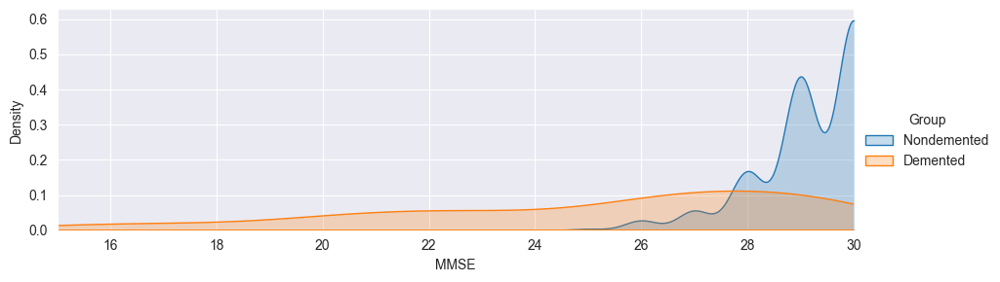

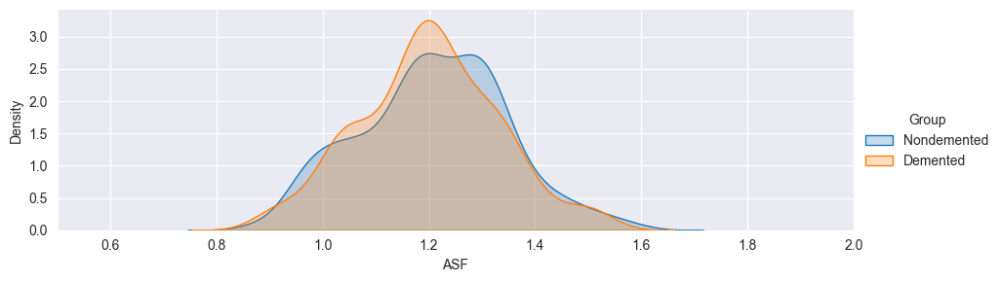

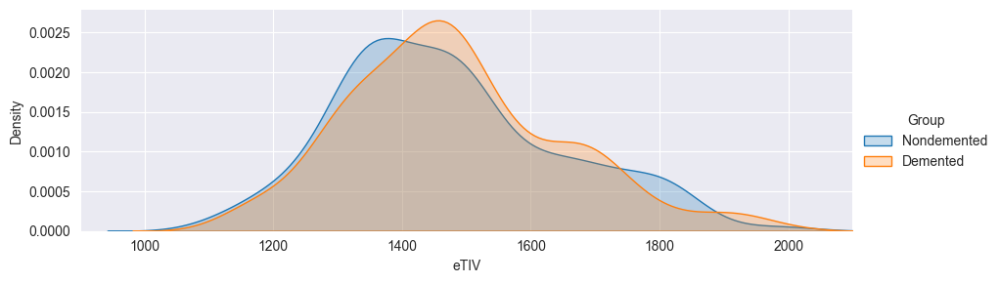

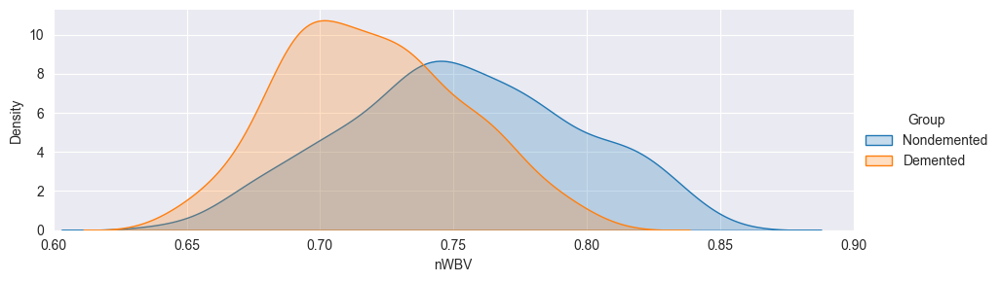

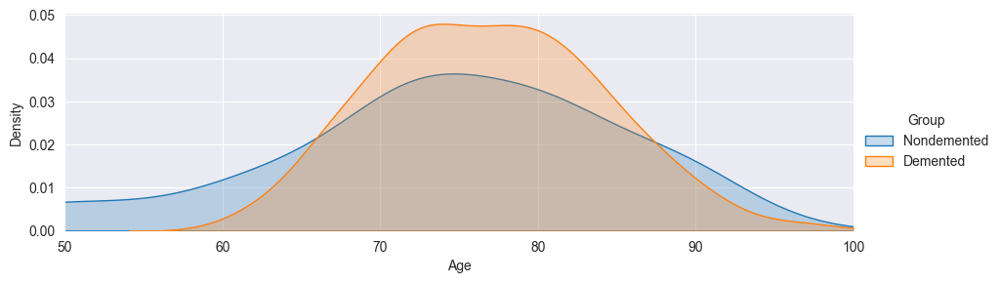

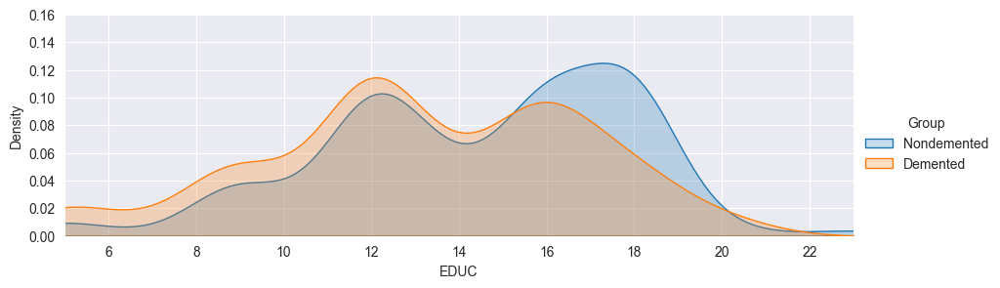

In [52]:
# KDE plots for selected features
facet = sns.FacetGrid(df_combined, hue='Group', aspect=3)
facet.map(sns.kdeplot, 'MMSE', fill=True)
facet.set(xlim=(0, df_combined['MMSE'].max()))
facet.add_legend()
plt.xlim(15, 30)
 
facet = sns.FacetGrid(df_combined, hue='Group', aspect=3)
facet.map(sns.kdeplot, 'ASF', fill=True)
facet.set(xlim=(0, df_combined['ASF'].max()))
facet.add_legend()
plt.xlim(0.5, 2)

facet = sns.FacetGrid(df_combined, hue='Group', aspect=3)
facet.map(sns.kdeplot, 'eTIV', fill=True)
facet.set(xlim=(0, df_combined['eTIV'].max()))
facet.add_legend()
plt.xlim(900, 2100)

facet = sns.FacetGrid(df_combined, hue='Group', aspect=3)
facet.map(sns.kdeplot, 'nWBV', fill=True)
facet.set(xlim=(0, df_combined['nWBV'].max()))
facet.add_legend()
plt.xlim(0.6, 0.9)

facet = sns.FacetGrid(df_combined, hue='Group', aspect=3)
facet.map(sns.kdeplot, 'Age', fill=True)
facet.set(xlim=(0, df_combined['Age'].max()))
facet.add_legend()
plt.xlim(50, 100)

facet = sns.FacetGrid(df_combined, hue='Group', aspect=3)
facet.map(sns.kdeplot, 'EDUC', fill=True)
facet.set(xlim=(df_combined['EDUC'].min(), df_combined['EDUC'].max()))
facet.add_legend()
plt.ylim(0, 0.16)

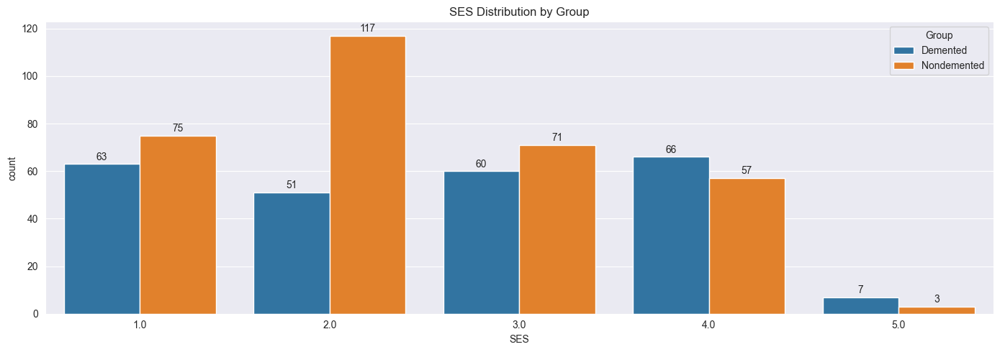

In [53]:
fig, ax = plt.subplots(figsize=(14,5))

# SES
sns.countplot(
    data=df_combined,
    x='SES',
    hue='Group',
    ax = ax
)

ax.set_title('SES Distribution by Group')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=2)


plt.tight_layout()
plt.show()

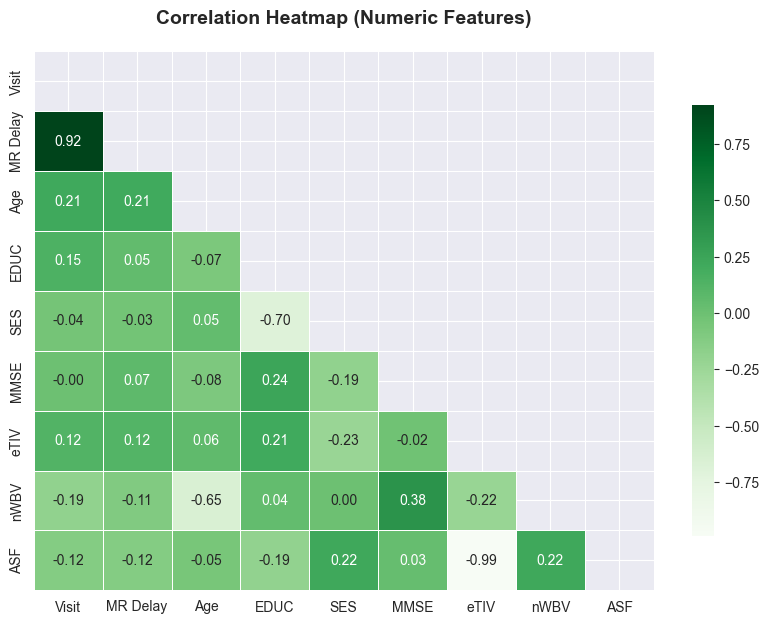

In [54]:

df_heatmap = df_combined.drop(columns=['CDR'], errors='ignore').select_dtypes(include='number')
corr = df_heatmap.corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    cmap='Greens',       
    fmt='.2f',
    mask=mask,           
    linewidths=0.5,      
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Heatmap (Numeric Features)", fontsize=14, fontweight='bold', pad=20)
plt.show()

# Explore Dataset Combine with 3 label

In [55]:
# Xử lý đồng bộ cột học vấn cho df_cross (Quy đổi cấp học thành số năm)
mapping_educ = {1: 5, 2: 9, 3: 12, 4: 16, 5: 18}
df_cross['EDUC'] = df_cross['Educ'].map(mapping_educ)

# Đồng bộ các cột khác và tự tạo Group cho df_cross như các bước trước
df_cross = df_cross.rename(columns={'ID': 'Subject ID', 'Delay': 'MR Delay'})
df_cross['Visit'] = 1
df_cross['MRI ID'] = df_cross['Subject ID']

In [56]:
# Gộp 2 file lại với nhau
columns_to_keep = ['Subject ID', 'MRI ID', 'Group_label', 'Visit', 'MR Delay', 'M/F', 'Hand', 'Age', 'EDUC', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF']
df_combined_3label = pd.concat([df_long[columns_to_keep], df_cross[columns_to_keep]], axis=0, ignore_index=True)

In [57]:
print(f"Shape của dataset sau khi gộp 2 file.csv là: {df_combined_3label.shape}")
print(f"Các chỉ số của dataset:\n")
print(df_combined_3label.info())
print("==="*30)
df_combined_3label.isnull().sum()

Shape của dataset sau khi gộp 2 file.csv là: (809, 15)
Các chỉ số của dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 809 entries, 0 to 808
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Subject ID   809 non-null    object 
 1   MRI ID       809 non-null    object 
 2   Group_label  608 non-null    object 
 3   Visit        809 non-null    int64  
 4   MR Delay     393 non-null    float64
 5   M/F          809 non-null    object 
 6   Hand         809 non-null    object 
 7   Age          809 non-null    int64  
 8   EDUC         608 non-null    float64
 9   SES          570 non-null    float64
 10  MMSE         606 non-null    float64
 11  CDR          608 non-null    float64
 12  eTIV         809 non-null    int64  
 13  nWBV         809 non-null    float64
 14  ASF          809 non-null    float64
dtypes: float64(7), int64(3), object(5)
memory usage: 94.9+ KB
None


Subject ID       0
MRI ID           0
Group_label    201
Visit            0
MR Delay       416
M/F              0
Hand             0
Age              0
EDUC           201
SES            239
MMSE           203
CDR            201
eTIV             0
nWBV             0
ASF              0
dtype: int64

In [58]:
df_combined_3label.head(10)

,Subject ID,MRI ID,Group_label,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001,OAS2_0001_MR1,Nondemented,1,0.0,M,R,87,14.0,2.0,27.0,0.0,1987,0.696,0.883
1,OAS2_0001,OAS2_0001_MR2,Nondemented,2,457.0,M,R,88,14.0,2.0,30.0,0.0,2004,0.681,0.876
2,OAS2_0002,OAS2_0002_MR1,Very Mild Dementia,1,0.0,M,R,75,12.0,NaN,23.0,0.5,1678,0.736,1.046
3,OAS2_0002,OAS2_0002_MR2,Very Mild Dementia,2,560.0,M,R,76,12.0,NaN,28.0,0.5,1738,0.713,1.010
4,OAS2_0002,OAS2_0002_MR3,Very Mild Dementia,3,1895.0,M,R,80,12.0,NaN,22.0,0.5,1698,0.701,1.034
5,OAS2_0004,OAS2_0004_MR1,Nondemented,1,0.0,F,R,88,18.0,3.0,28.0,0.0,1215,0.710,1.444
6,OAS2_0004,OAS2_0004_MR2,Nondemented,2,538.0,F,R,90,18.0,3.0,27.0,0.0,1200,0.718,1.462
7,OAS2_0005,OAS2_0005_MR1,Nondemented,1,0.0,M,R,80,12.0,4.0,28.0,0.0,1689,0.712,1.039
8,OAS2_0005,OAS2_0005_MR2,Very Mild Dementia,2,1010.0,M,R,83,12.0,4.0,29.0,0.5,1701,0.711,1.032
9,OAS2_0005,OAS2_0005_MR3,Nondemented,3,1603.0,M,R,85,12.0,4.0,30.0,0.0,1699,0.705,1.033


In [59]:
# Summary statistics
cols_summary = ['EDUC','SES','MMSE','CDR','eTIV','nWBV','ASF']
summary = df_combined_3label[cols_summary].describe().T[['min','max','mean','50%']]
summary = summary.rename(columns={'50%':'median'})
print("Table of min, max, mean, median:")
display(summary)

Table of min, max, mean, median:


,min,max,mean,median
EDUC,5.000,23.000,13.845395,14.000
SES,1.000,5.000,2.471930,2.000
MMSE,4.000,30.000,27.234323,29.000
CDR,0.000,2.000,0.288651,0.000
eTIV,1106.000,2004.000,1484.782447,1475.000
nWBV,0.644,0.893,0.763037,0.754
ASF,0.876,1.587,1.197311,1.190


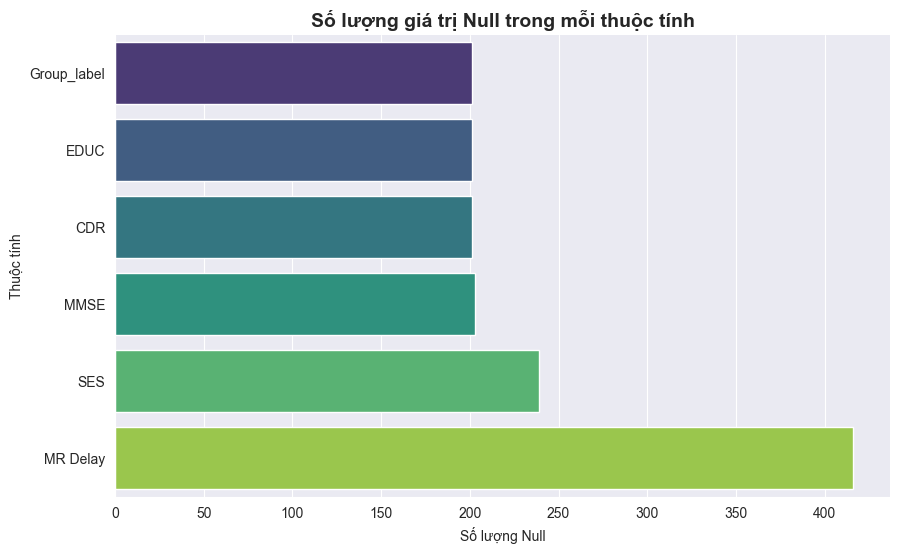

In [60]:
missing = df_combined_3label.isnull().sum()
missing = missing[missing > 0]

missing_sorted = missing.sort_values(ascending=True)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=missing_sorted.values, 
    y=missing_sorted.index, 
    palette='viridis',
    hue=missing_sorted.index,
    legend=False
)

plt.title('Số lượng giá trị Null trong mỗi thuộc tính', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng Null')
plt.ylabel('Thuộc tính')
sns.despine() 
plt.show()

In [61]:
# Lọc bỏ None và trùng lặp
df_combined_3label.dropna(subset=['Group_label'], inplace=True)
df_combined_3label.drop_duplicates(inplace=True)
print(f"Shape :{df_combined_3label.shape}")

Shape :(608, 15)


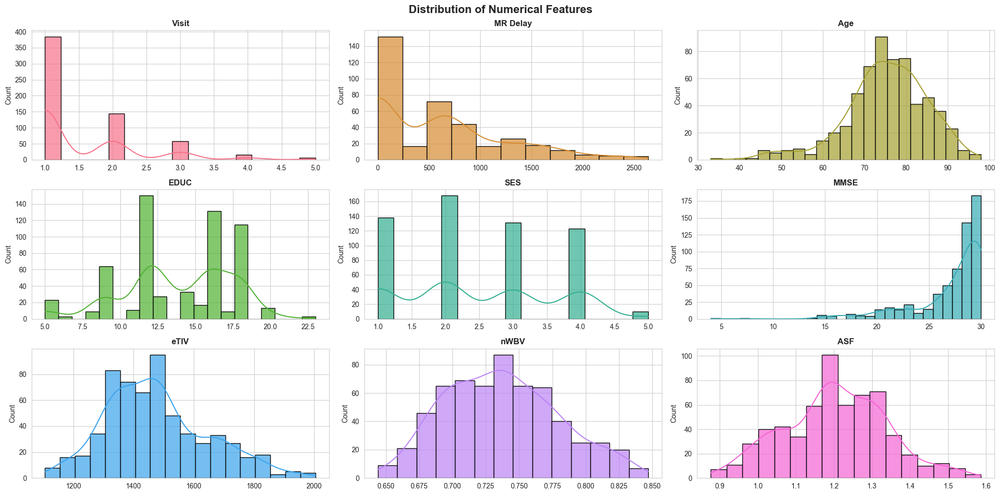

In [62]:

sns.set_style("whitegrid")

num_cols = (
    df_combined_3label.select_dtypes(include='number')
    .drop(columns=['CDR', 'Group_label', 'Delay'], errors='ignore')
    .columns
)

fig, axes = plt.subplots(3, 3, figsize=(20, 10))
axes = axes.flatten()

colors = sns.color_palette("husl", len(num_cols))

for ax, col, color in zip(axes, num_cols, colors):
    sns.histplot(
        df_combined_3label[col],
        kde=True,
        ax=ax,
        color=color,
        edgecolor='black',
        alpha=0.7
    )

    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Count')

# Xóa ô thừa
for ax in axes[len(num_cols):]:
    fig.delaxes(ax)

plt.suptitle(
    'Distribution of Numerical Features',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

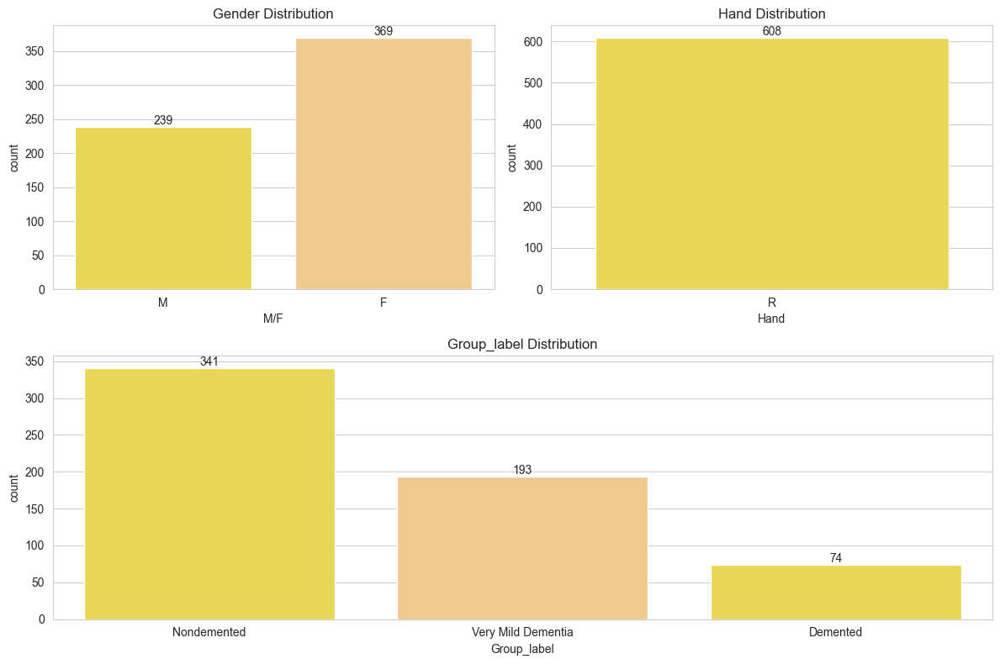

In [63]:

# Định nghĩa màu vàng nhạt và cam nhạt
summer_palette = ["#FFEB3B", "#FFCC80"] 

fig = plt.figure(figsize=(12, 8))
gs = GridSpec(2, 2, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

sns.countplot(data=df_combined_3label, x='M/F', hue='M/F',
              palette=summer_palette, legend=False, ax=ax1, edgecolor=None)

sns.countplot(data=df_combined_3label, x='Hand', hue='Hand',
              palette=summer_palette, legend=False, ax=ax2, edgecolor=None)

sns.countplot(data=df_combined_3label, x='Group_label', hue='Group_label',
              palette=summer_palette, legend=False, ax=ax3, edgecolor=None)

ax1.set_title('Gender Distribution')
ax2.set_title('Hand Distribution')
ax3.set_title('Group_label Distribution')

for ax in [ax1, ax2, ax3]:
    for container in ax.containers:
        ax.bar_label(container, fmt='%d')

plt.tight_layout()
plt.show()

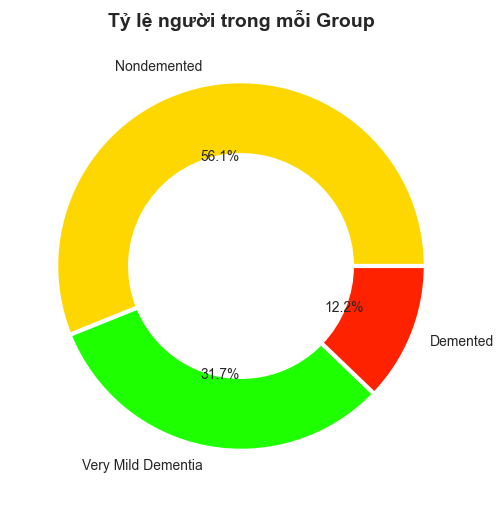

In [64]:

group_count = df_combined_3label['Group_label'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(group_count.values, labels=group_count.index, autopct='%1.1f%%', 
        wedgeprops={'width': 0.4, 'edgecolor': 'white', 'linewidth': 3},
        colors=['#FFD700', "#1EFF00","#FF2200"])

plt.title('Tỷ lệ người trong mỗi Group', fontsize=14, fontweight='bold')
plt.show()

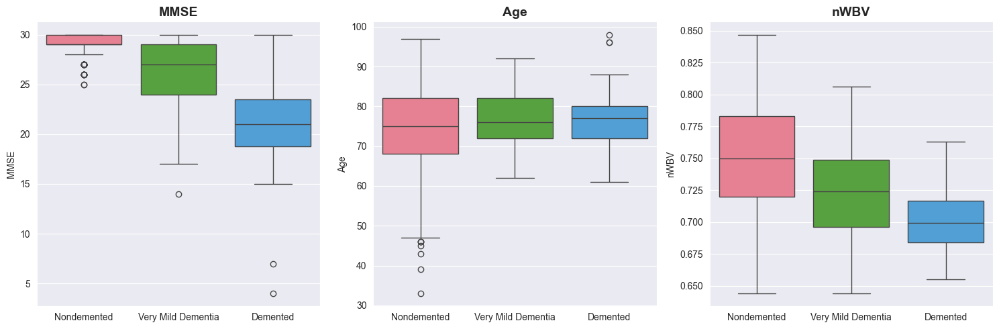

In [65]:
sns.set_style("darkgrid") 

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(data=df_combined_3label, x='Group_label', y='MMSE', hue='Group_label',
            palette='husl', legend=False, ax=ax[0])
ax[0].set_title('MMSE', fontsize=14, fontweight='bold') 

sns.boxplot(data=df_combined_3label, x='Group_label', y='Age', hue='Group_label',
            palette='husl', legend=False, ax=ax[1])
ax[1].set_title('Age', fontsize=14, fontweight='bold')

sns.boxplot(data=df_combined_3label, x='Group_label', y='nWBV', hue='Group_label',
            palette='husl', legend=False, ax=ax[2])
ax[2].set_title('nWBV', fontsize=14, fontweight='bold')

for a in ax:
    a.set_xlabel('') 
    
plt.tight_layout()
plt.show()

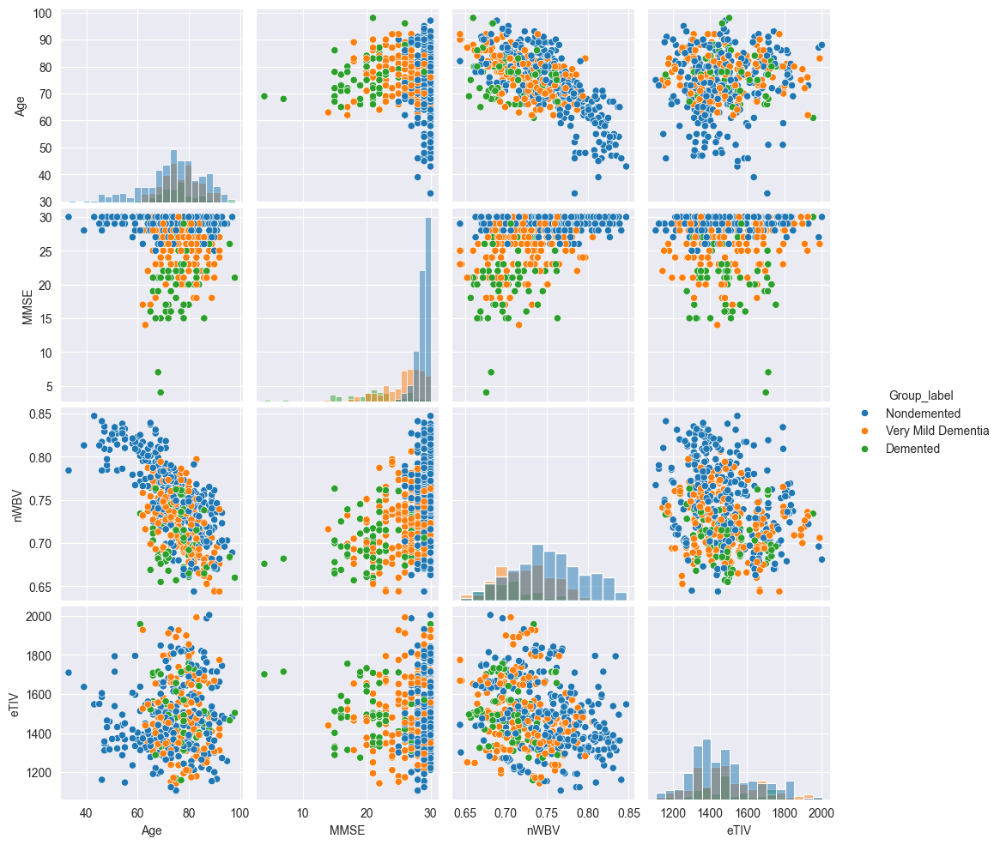

In [66]:
cols = ['Age', 'MMSE', 'nWBV', 'eTIV', 'Group_label']

sns.pairplot(
    df_combined_3label[cols],
    hue='Group_label',
    diag_kind='hist'
)

plt.show()

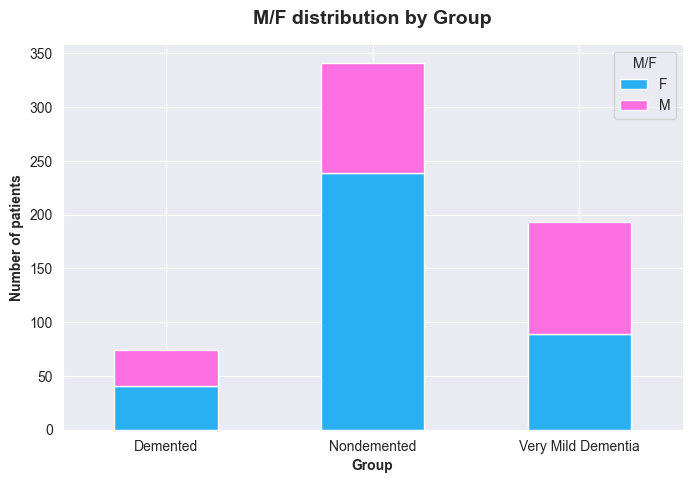

In [67]:
def bar_chart(feature):
    Demented = df_combined_3label[df_combined_3label['Group_label'] == 'Demented'][feature].value_counts()
    Nondemented = df_combined_3label[df_combined_3label['Group_label'] == 'Nondemented'][feature].value_counts()
    Very_Mild_Dementia = df_combined_3label[df_combined_3label['Group_label'] == 'Very Mild Dementia'][feature].value_counts()
    df_bar = pd.DataFrame([Demented, Nondemented,Very_Mild_Dementia])
    df_bar.index = ['Demented', 'Nondemented',"Very Mild Dementia"]

    df_bar.plot(
        kind='bar',
        stacked=True,
        figsize=(8, 5),
        color=["#29B0F3", "#FB6FE1"], 
        edgecolor=None              
    )

    plt.xlabel('Group', fontweight='bold')
    plt.ylabel('Number of patients', fontweight='bold')
    plt.title(f'{feature} distribution by Group', fontsize=14, fontweight='bold', pad=15)
    
    sns.despine()
    
    plt.xticks(rotation=0)
    
    plt.show()

bar_chart('M/F')

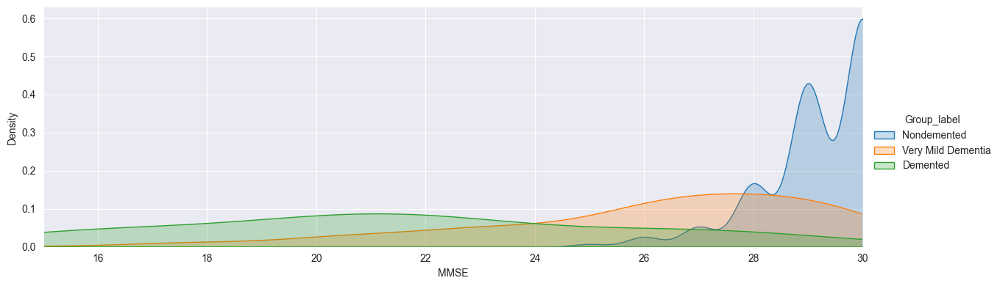

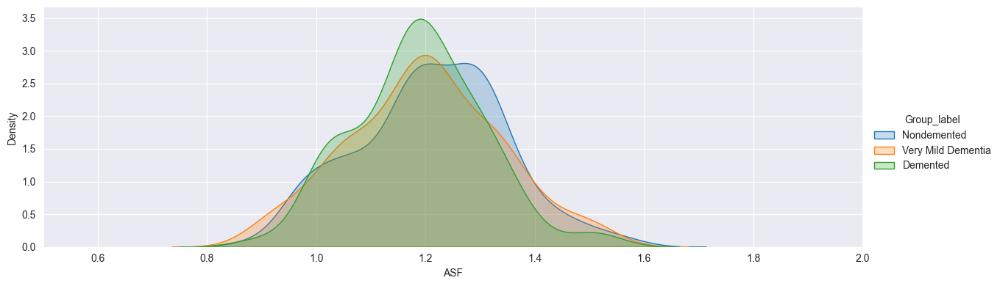

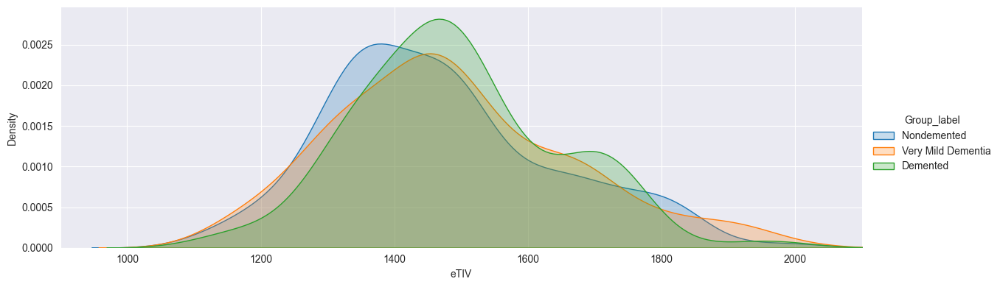

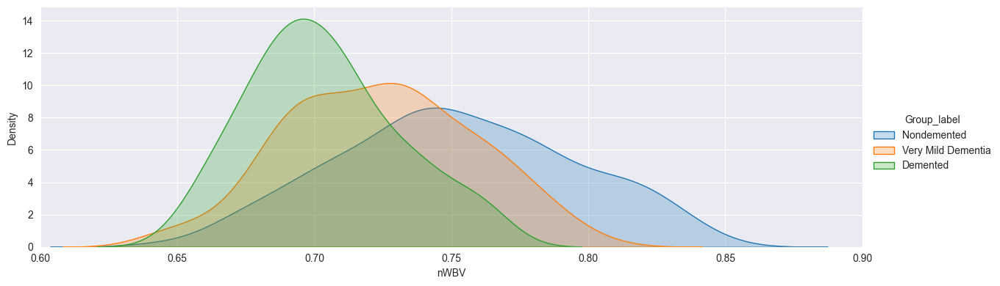

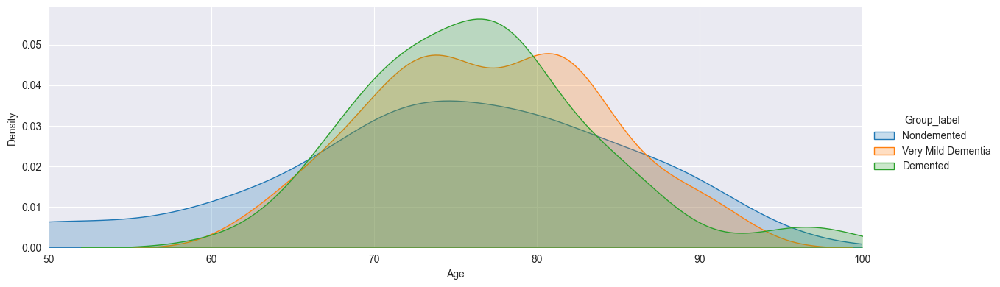

In [68]:
facet = sns.FacetGrid(df_combined_3label, hue='Group_label', aspect=3, height=4)
facet.map(sns.kdeplot, 'MMSE', fill=True)
facet.set(xlim=(15, 30))
facet.add_legend()
plt.show()

facet = sns.FacetGrid(df_combined_3label, hue='Group_label', aspect=3, height=4)
facet.map(sns.kdeplot, 'ASF', fill=True)
facet.set(xlim=(0.5, 2))
facet.add_legend()
plt.show()

facet = sns.FacetGrid(df_combined_3label, hue='Group_label', aspect=3, height=4)
facet.map(sns.kdeplot, 'eTIV', fill=True)
facet.set(xlim=(900, 2100))
facet.add_legend()
plt.show()

facet = sns.FacetGrid(df_combined_3label, hue='Group_label', aspect=3, height=4)
facet.map(sns.kdeplot, 'nWBV', fill=True)
facet.set(xlim=(0.6, 0.9))
facet.add_legend()
plt.show()

facet = sns.FacetGrid(df_combined_3label, hue='Group_label', aspect=3, height=4)
facet.map(sns.kdeplot, 'Age', fill=True)
facet.set(xlim=(50, 100))
facet.add_legend()
plt.show()

facet.add_legend()
plt.show()

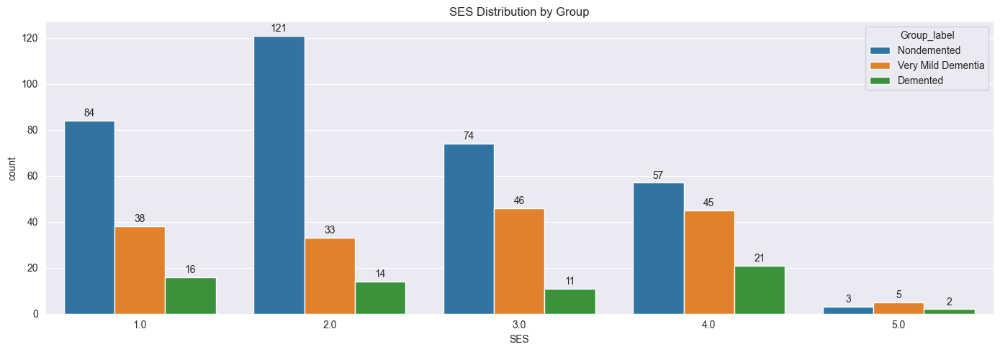

In [69]:
fig, ax = plt.subplots(figsize=(14,5))

# SES
sns.countplot(
    data=df_combined_3label,
    x='SES',
    hue='Group_label',
    ax = ax
)

ax.set_title('SES Distribution by Group')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=2)


plt.tight_layout()
plt.show()

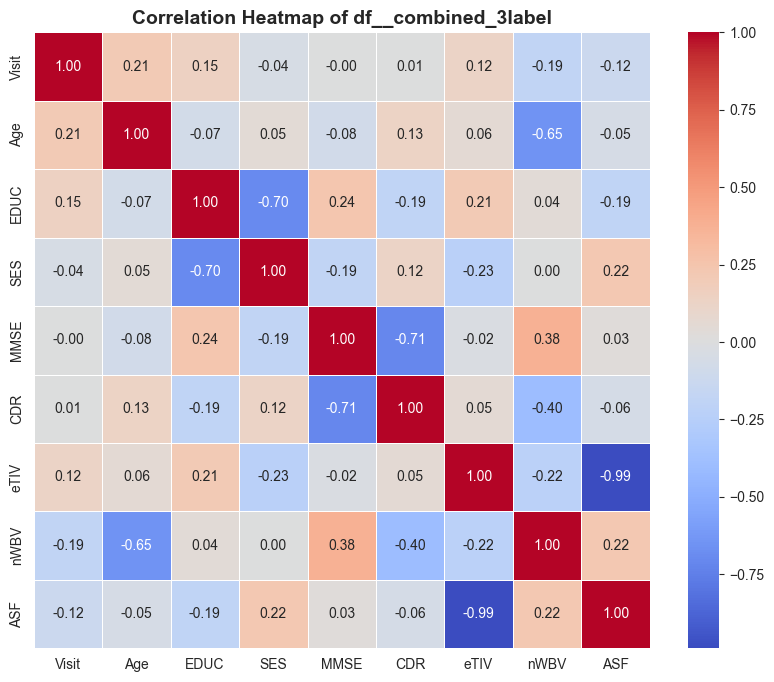

In [70]:

numeric_df = df_combined_3label.select_dtypes(include=['number']).drop(columns=['MR Delay'])

corr_matrix = numeric_df.corr()

# Vẽ heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    square=True,
    linewidths=0.5
)

plt.title('Correlation Heatmap of df__combined_3label', fontsize=14, fontweight='bold')
plt.show()

# Preprocessing

In [71]:
def preprocess_data(df, target_col='Group', drop_cols=None, cat_features=None, special_num_features=None, test_size=0.2, use_smote=False,
                    random_state=42 ):

    if drop_cols is None:
        drop_cols = []

    if cat_features is None:
        cat_features = []

    if special_num_features is None:
        special_num_features = []

    # X, y
    X = df.drop(columns=drop_cols + [target_col])
    y = LabelEncoder().fit_transform(df[target_col])

    # Train test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=y)

    # Numeric columns
    num_features = [
        col for col in X.columns
        if col not in cat_features + special_num_features
    ]

    # Transformers
    cat_transformer = Pipeline([
        ('encoder', OrdinalEncoder())
    ])

    special_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    num_transformer = Pipeline([
        ('imputer', KNNImputer(n_neighbors=5)),
        ('scaler', StandardScaler())
    ])

    transformers = []

    if cat_features:
        transformers.append(
            ('cat', cat_transformer, cat_features)
        )

    if special_num_features:
        transformers.append(
            ('special', special_transformer, special_num_features)
        )

    if num_features:
        transformers.append(
            ('num', num_transformer, num_features)
        )

    preprocessor = ColumnTransformer(transformers)

    X_nd_combined = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)
    
    #SMOTENC
    if use_smote:
        categorical_indices = list(range(len(cat_features)))

        smote = SMOTENC(
            categorical_features=categorical_indices,
            random_state=random_state
        )

        X_nd_combined, y_train = smote.fit_resample(
            X_nd_combined,
            y_train
        )

    feature_names = (cat_features + special_num_features + num_features )

    return (
        X_nd_combined,
        X_test_processed,
        y_train,
        y_test,
        preprocessor,
        feature_names
    )

In [72]:
def plot_processed_heatmap(X_processed, feature_names):
    X_df = pd.DataFrame(X_processed, columns=feature_names)

    corr_matrix = X_df.corr()

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        fmt=".2f",
        linewidths=0.5,
        vmin=-1,
        vmax=1
    )

    plt.title(
        'Correlation Matrix After Preprocessing',
        fontsize=14,
        pad=15
    )

    plt.tight_layout()
    plt.show()

    return X_df

# Combined Preprocessing 

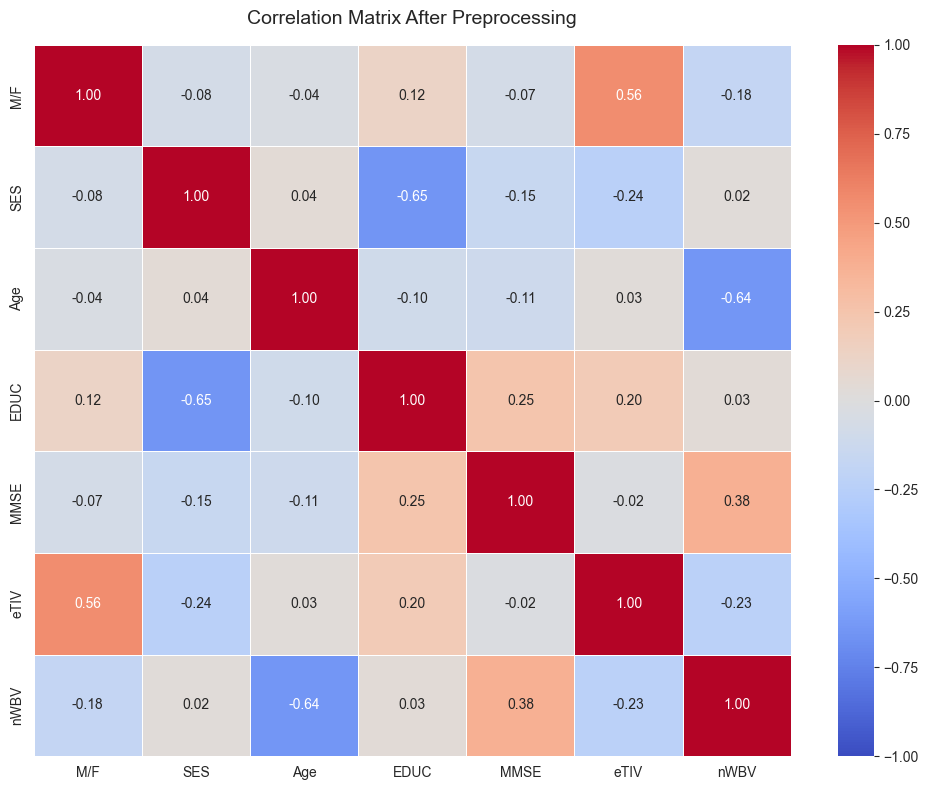

In [73]:
X_nd_combined, X_test_processed_cb, y_train_cb, y_test_cb, preprocessor_cb, feature_names_cb = preprocess_data(
    df=df_combined,
    target_col='Group',
    drop_cols=[
        'MR Delay',
        'CDR',
        'ASF',
        "Group",
        "Hand",
        'Subject ID',
        'MRI ID',
        "Visit"
    ],
    cat_features=['M/F'],
    special_num_features=['SES']
)

X_df_cb = plot_processed_heatmap(X_nd_combined,feature_names_cb )

In [74]:
X_df_cb.info()
X_df_cb.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 486 entries, 0 to 485
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   M/F     486 non-null    float64
 1   SES     486 non-null    float64
 2   Age     486 non-null    float64
 3   EDUC    486 non-null    float64
 4   MMSE    486 non-null    float64
 5   eTIV    486 non-null    float64
 6   nWBV    486 non-null    float64
dtypes: float64(7)
memory usage: 26.7 KB


M/F     0
SES     0
Age     0
EDUC    0
MMSE    0
eTIV    0
nWBV    0
dtype: int64

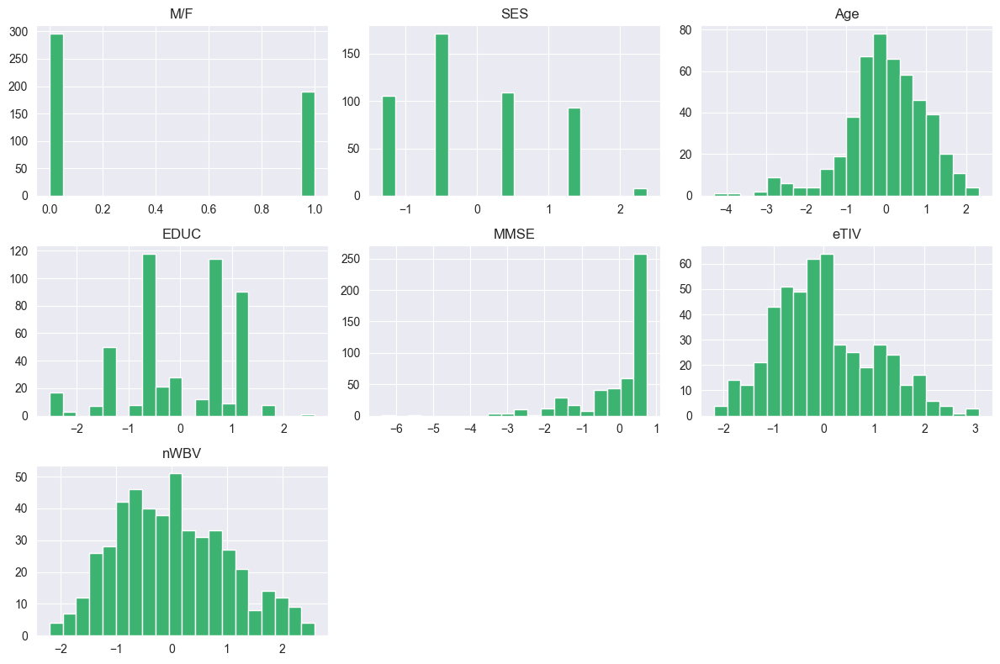

In [75]:
X_df_cb.hist(
    figsize=(12, 8),
    bins=20,
    color='mediumseagreen'  
)

plt.tight_layout()
plt.show()

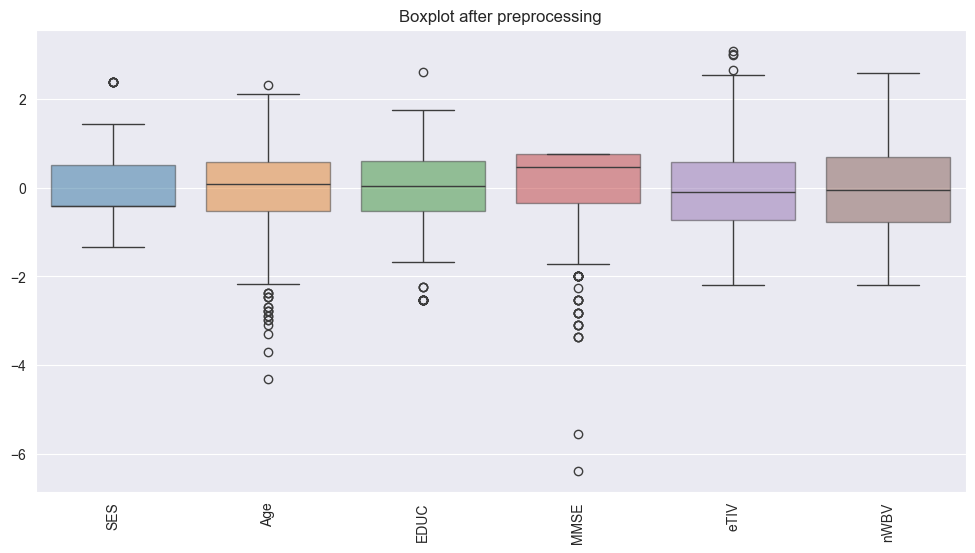

In [76]:
# Bỏ cột M/F
df_boxplot = X_df_cb.drop(columns=['M/F'])

plt.figure(figsize=(12,6))

sns.boxplot(
    data=df_boxplot,
    boxprops=dict(alpha=0.5)
)

plt.xticks(rotation=90)
plt.title("Boxplot after preprocessing")
plt.show()

# combined 3L Preprocessing 

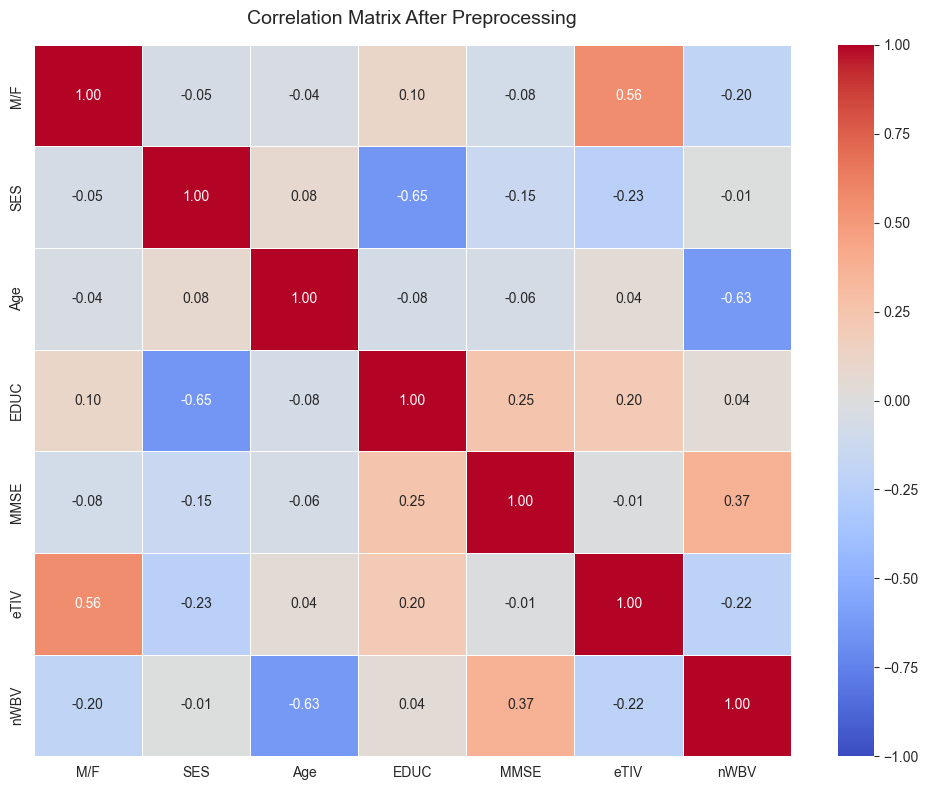

In [77]:
X_nd_combined_3l, X_test_processed_3l, y_train_3l, y_test_3l, preprocessor_3l, feature_names_3l = preprocess_data(
    df=df_combined_3label,
    target_col='Group_label',
    drop_cols=[
        'Subject ID',
        'MRI ID',
        'Group_label',
        'Hand',
        'CDR',
        'MR Delay',
        'Visit',
        'ASF'
    ],
    cat_features=['M/F'],
    special_num_features=['SES']
)

X_df_cb3 = plot_processed_heatmap(X_nd_combined_3l, feature_names_3l)

In [78]:
X_df_cb3.info()
X_df_cb3.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 486 entries, 0 to 485
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   M/F     486 non-null    float64
 1   SES     486 non-null    float64
 2   Age     486 non-null    float64
 3   EDUC    486 non-null    float64
 4   MMSE    486 non-null    float64
 5   eTIV    486 non-null    float64
 6   nWBV    486 non-null    float64
dtypes: float64(7)
memory usage: 26.7 KB


M/F     0
SES     0
Age     0
EDUC    0
MMSE    0
eTIV    0
nWBV    0
dtype: int64

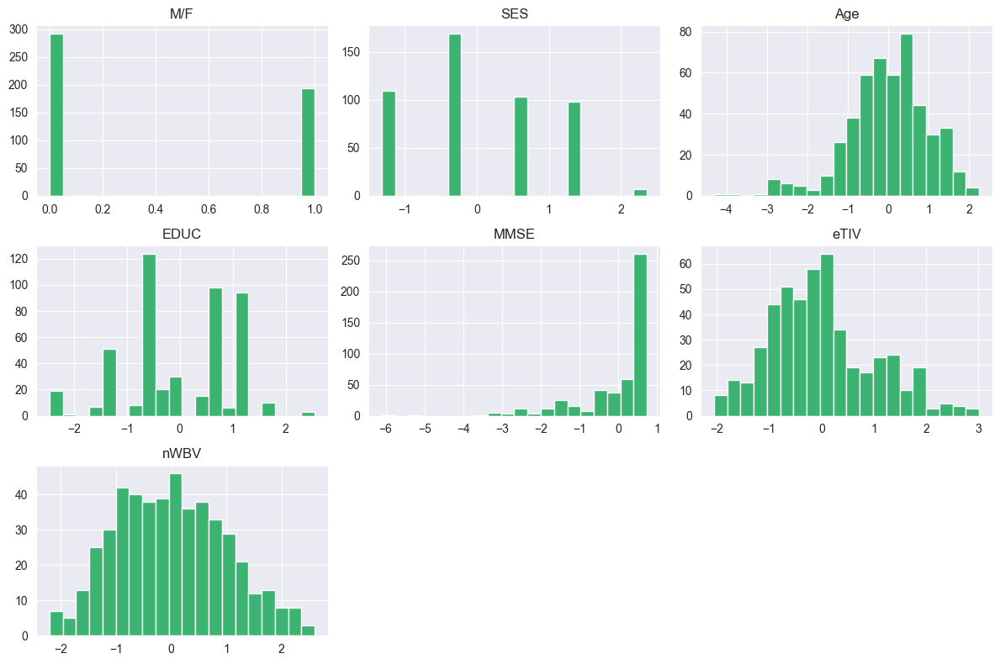

In [79]:
X_df_cb3.hist(
    figsize=(12, 8),
    bins=20,
    color='mediumseagreen'  
)

plt.tight_layout()
plt.show()

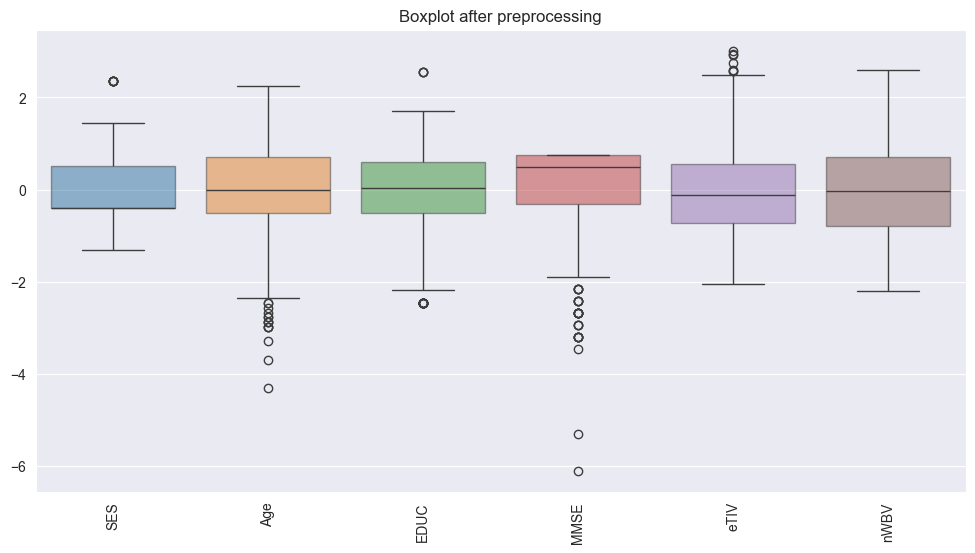

In [80]:

df_boxplot = X_df_cb3.drop(columns=['M/F'])

plt.figure(figsize=(12,6))

sns.boxplot(
    data=df_boxplot,
    boxprops=dict(alpha=0.5)
)

plt.xticks(rotation=90)
plt.title("Boxplot after preprocessing")
plt.show()

# combined 3L with SMOTENC Preprocessing 

In [81]:
X_nd_combined_3l_smotenc, X_test_processed_3l_smotenc,y_train_3l_smotenc, y_test_3l_smotenc, preprocessor_3l_smote, feature_names_3l_smote = preprocess_data(
    df=df_combined_3label,
    target_col='Group_label',
    drop_cols=[
        'Subject ID',
        'MRI ID',
        'Group_label',
        'Hand',
        'CDR',
        'MR Delay',
        'Visit',
        'ASF'
    ],
    cat_features=['M/F'],
    special_num_features=['SES'],
    use_smote=True
)

In [82]:
from collections import Counter

print("Trước SMOTE:")
print(Counter(y_train_3l))

print("\nSau SMOTE:")
print(Counter(y_train_3l_smotenc))

Trước SMOTE:
Counter({np.int64(1): 273, np.int64(2): 154, np.int64(0): 59})

Sau SMOTE:
Counter({np.int64(1): 273, np.int64(2): 273, np.int64(0): 273})


In [83]:
print(np.unique(X_nd_combined_3l[:, 0]))

[0. 1.]


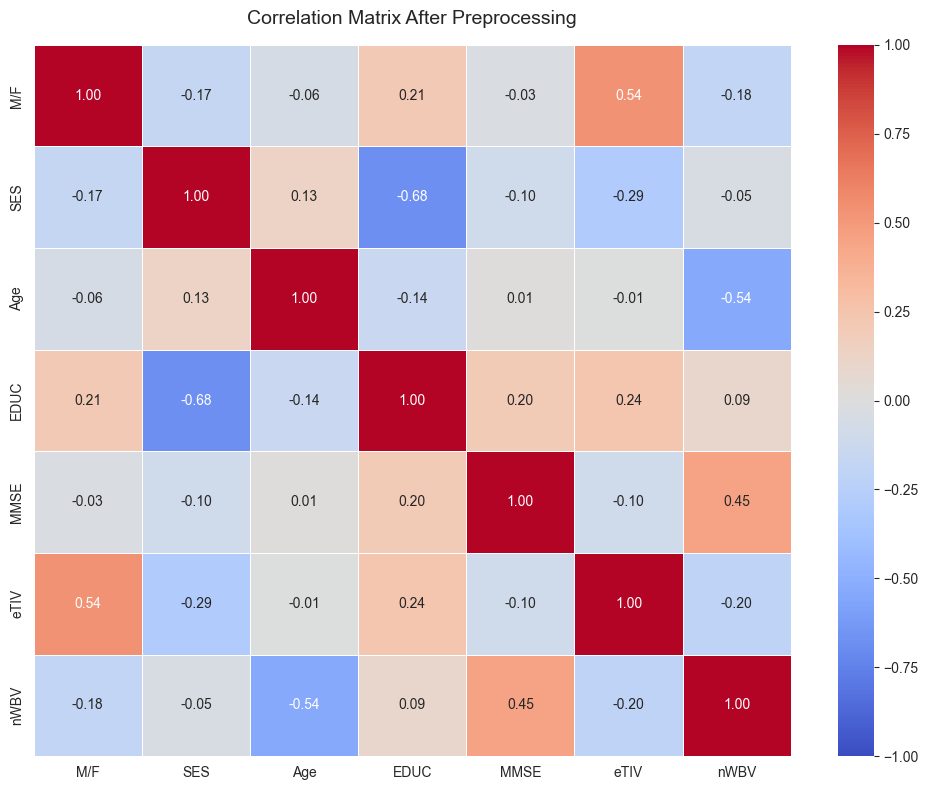

In [84]:
X_df_cb3_smote = plot_processed_heatmap(
    X_nd_combined_3l_smotenc,
    feature_names_3l_smote
)

In [85]:
print(X_df_cb3_smote.shape)
print(len(y_train_3l_smotenc))

print(X_nd_combined_3l_smotenc.shape)
print(len(y_train_3l_smotenc))

(819, 7)
819
(819, 7)
819


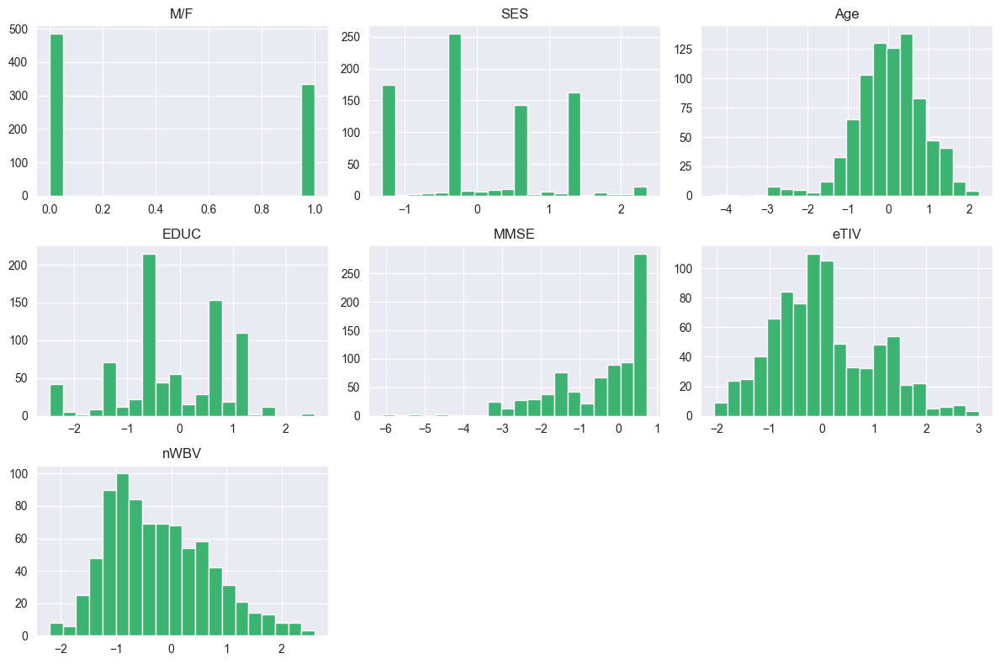

In [86]:
X_df_cb3_smote.hist(
    figsize=(12, 8),
    bins=20,
    color='mediumseagreen'  
)

plt.tight_layout()
plt.show()

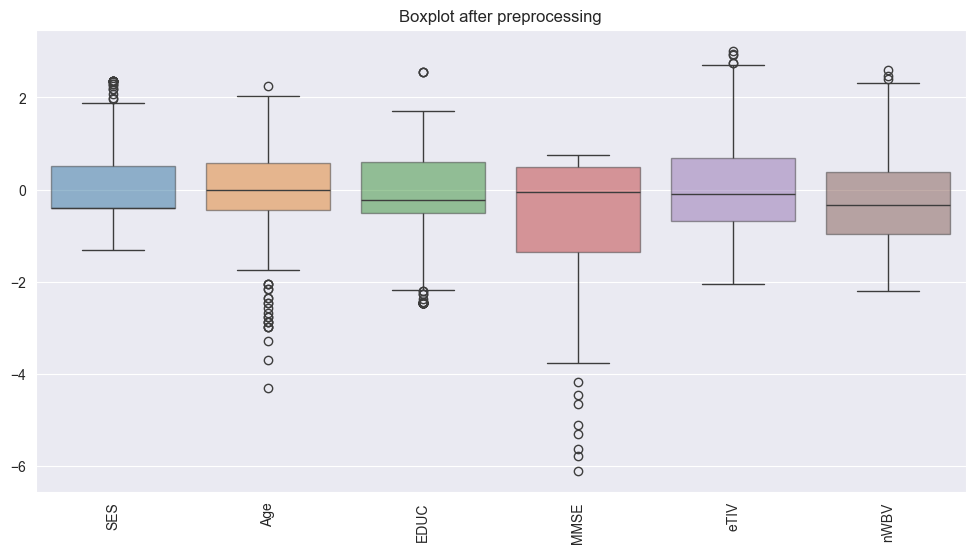

In [87]:

df_boxplot = X_df_cb3_smote.drop(columns=['M/F'])

plt.figure(figsize=(12,6))

sns.boxplot(
    data=df_boxplot,
    boxprops=dict(alpha=0.5)
)

plt.xticks(rotation=90)
plt.title("Boxplot after preprocessing")
plt.show()

# Feature Selection

## ANOVA

In [88]:
def calculate_anova(X, y, plot=False, title='ANOVA F-test Scores'):
    selector = SelectKBest(
        score_func=f_classif,
        k=5
    )

    selector.fit(X, y)

    anova_results = pd.DataFrame({
        'Feature': X.columns,
        'F-Score': selector.scores_,
        'p-Value': selector.pvalues_
    })

    anova_results = anova_results.sort_values(
        by='F-Score',
        ascending=False
    ).reset_index(drop=True)

    if plot:
        plt.figure(figsize=(8, 5))
        sns.barplot(
            data=anova_results,
            x='F-Score',
            y='Feature',
            hue='Feature',
            palette='magma',
            legend=False
        )
        plt.title(title)
        plt.tight_layout()
        plt.show()

    return selector, anova_results

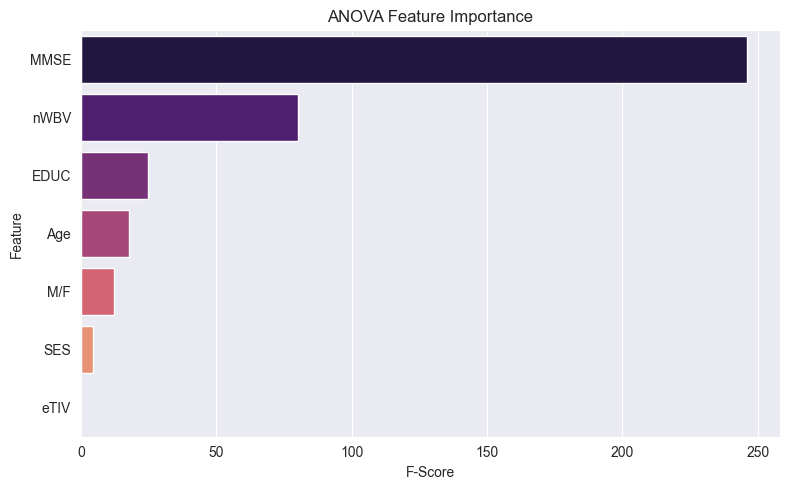

  Feature     F-Score       p-Value
0    MMSE  245.903221  4.132205e-45
1    nWBV   80.119374  7.562421e-18
2    EDUC   24.662255  9.485873e-07
3     Age   17.811934  2.912638e-05
4     M/F   12.333741  4.865130e-04
5     SES    4.656354  3.143006e-02
6    eTIV    0.000319  9.857685e-01


In [89]:
selector_anova_cb, anova_results = calculate_anova(
    X_df_cb,
    y_train_cb,
    plot=True,
    title='ANOVA Feature Importance'
)
print(anova_results)

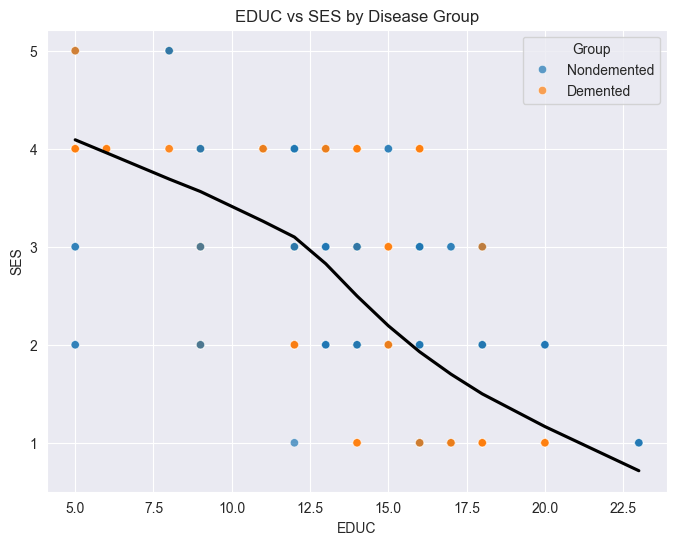

In [90]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_combined,
    x='EDUC',
    y='SES',
    hue='Group',
    alpha=0.7
)

sns.regplot(
    data=df_combined,
    x='EDUC',
    y='SES',
    scatter=False,
    lowess=True,
    color='black'
)

plt.title('EDUC vs SES by Disease Group')
plt.show()

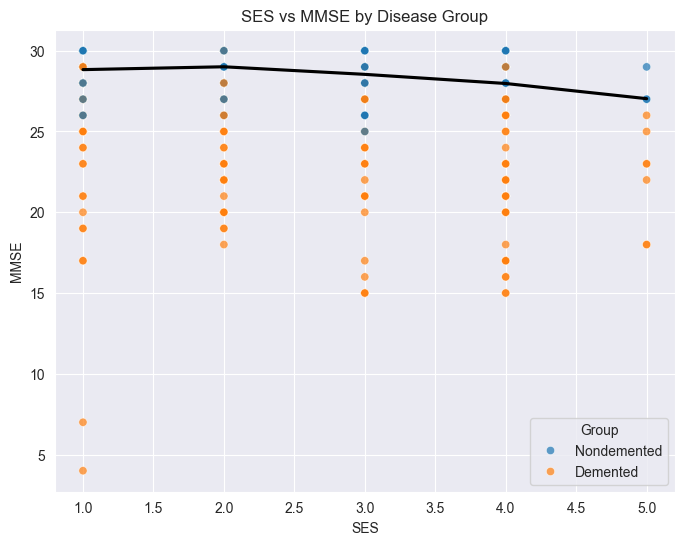

In [91]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_combined,
    x='SES',
    y='MMSE',
    hue='Group',
    alpha=0.7
)

sns.regplot(
    data=df_combined,
    x='SES',
    y='MMSE',
    scatter=False,
    lowess=True,
    color='black'
)

plt.title('SES vs MMSE by Disease Group')
plt.show()

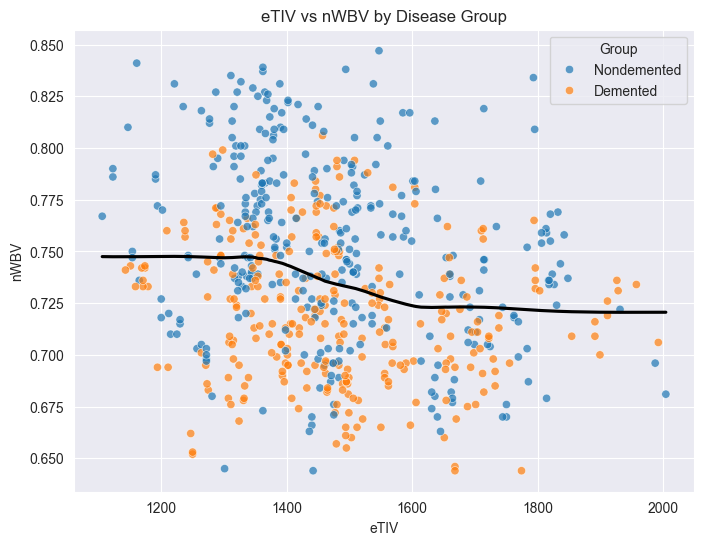

In [92]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_combined,
    x='eTIV',
    y='nWBV',
    hue='Group',
    alpha=0.7
)

sns.regplot(
    data=df_combined,
    x='eTIV',
    y='nWBV',
    scatter=False,
    lowess=True,
    color='black'
)

plt.title('eTIV vs nWBV by Disease Group')
plt.show()

## RandomForest

In [93]:

def calculate_rf_importance(X, y, n_estimators=100, random_state=42, plot=False, title='Random Forest Feature Importance'):
    # Huấn luyện Random Forest
    rf = RandomForestClassifier( n_estimators=n_estimators, random_state=random_state)

    rf.fit(X, y)

    # Lấy độ quan trọng của đặc trưng
    rf_results = pd.DataFrame({
        'Feature': X.columns,
        'Importance': rf.feature_importances_
    })

    # Sắp xếp giảm dần
    rf_results = rf_results.sort_values(
        by='Importance',
        ascending=False
    ).reset_index(drop=True)

    # Vẽ biểu đồ nếu cần
    if plot:
        plt.figure(figsize=(8, 5))

        sns.barplot(
            data=rf_results,
            x='Importance',
            y='Feature',
            hue='Feature',
            palette='viridis',
            legend=False
        )

        plt.title(title)
        plt.tight_layout()
        plt.show()

    return rf_results

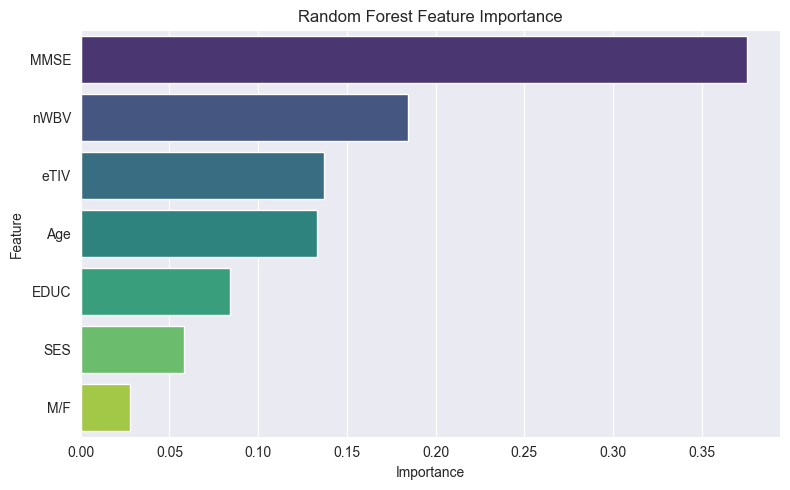

  Feature  Importance
0    MMSE    0.375444
1    nWBV    0.184684
2    eTIV    0.137171
3     Age    0.133207
4    EDUC    0.083909
5     SES    0.058001
6     M/F    0.027583


In [94]:
rf_results = calculate_rf_importance(
    X_df_cb,
    y_train_cb,
    plot=True,
    title='Random Forest Feature Importance'
)
print(rf_results)

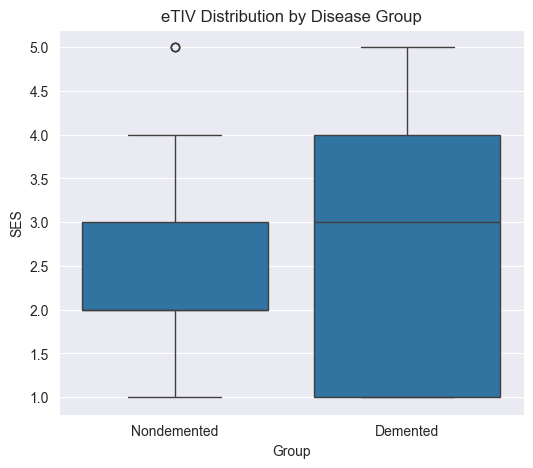

In [95]:
plt.figure(figsize=(6,5))

sns.boxplot(
    data=df_combined,
    x='Group',
    y='SES'
)

plt.title('eTIV Distribution by Disease Group')
plt.show()

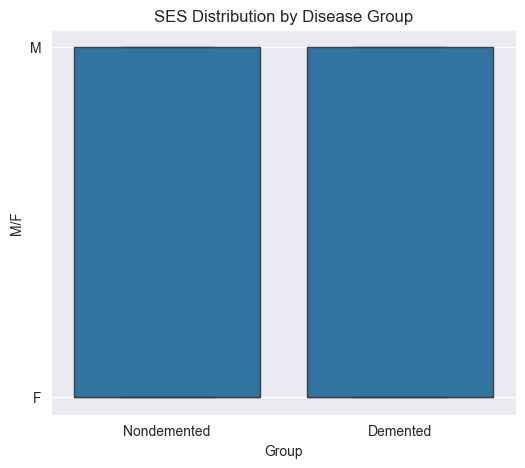

In [96]:
plt.figure(figsize=(6,5))

sns.boxplot(
    data=df_combined,
    x='Group',
    y='M/F'
)

plt.title('SES Distribution by Disease Group')
plt.show()

## selector_anova_3l and rf

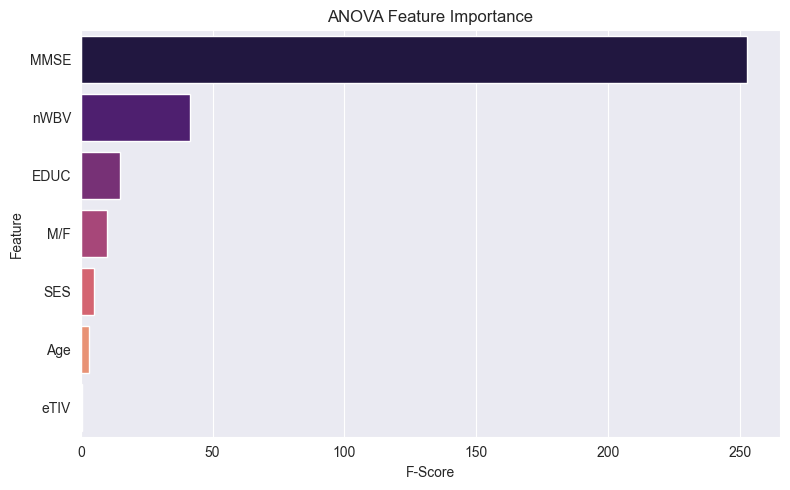

  Feature     F-Score       p-Value
0    MMSE  252.672923  7.993238e-76
1    nWBV   41.269113  2.842283e-17
2    EDUC   14.815866  5.691243e-07
3     M/F    9.947194  5.842349e-05
4     SES    4.848607  8.225008e-03
5     Age    3.258570  3.929012e-02
6    eTIV    0.437199  6.460985e-01


In [97]:
selector_anova_3l, anova_results = calculate_anova(
    X_df_cb3,
    y_train_3l,
    plot=True,
    title='ANOVA Feature Importance'
)
print(anova_results)

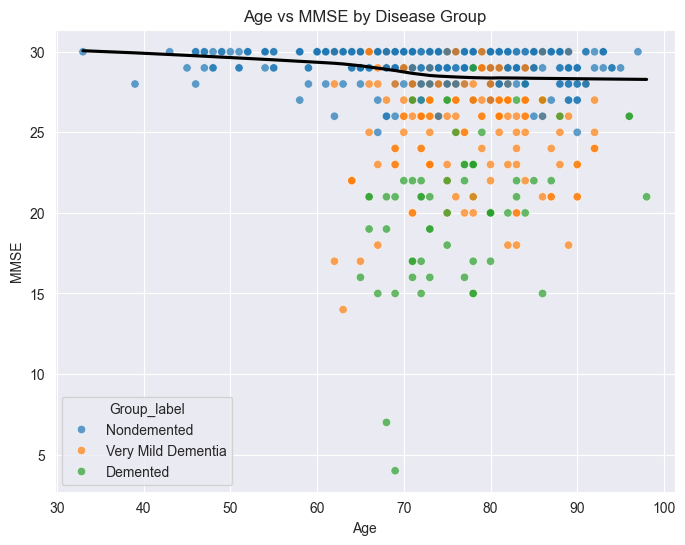

In [98]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_combined_3label,
    x='Age',
    y='MMSE',
    hue='Group_label',
    alpha=0.7
)

sns.regplot(
    data=df_combined_3label,
    x='Age',
    y='MMSE',
    scatter=False,
    lowess=True,
    color='black'
)

plt.title('Age vs MMSE by Disease Group')
plt.show()

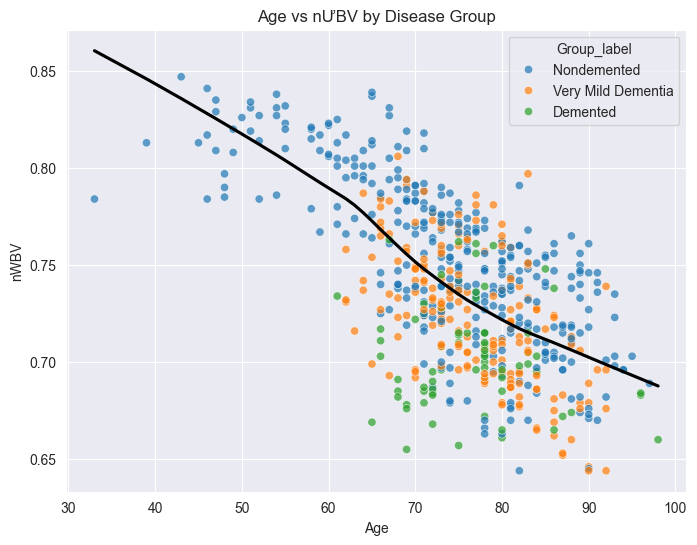

In [99]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_combined_3label,
    x='Age',
    y='nWBV',
    hue='Group_label',
    alpha=0.7
)

sns.regplot(
    data=df_combined_3label,
    x='Age',
    y='nWBV',
    scatter=False,
    lowess=True,
    color='black'
)

plt.title('Age vs nƯBV by Disease Group')
plt.show()

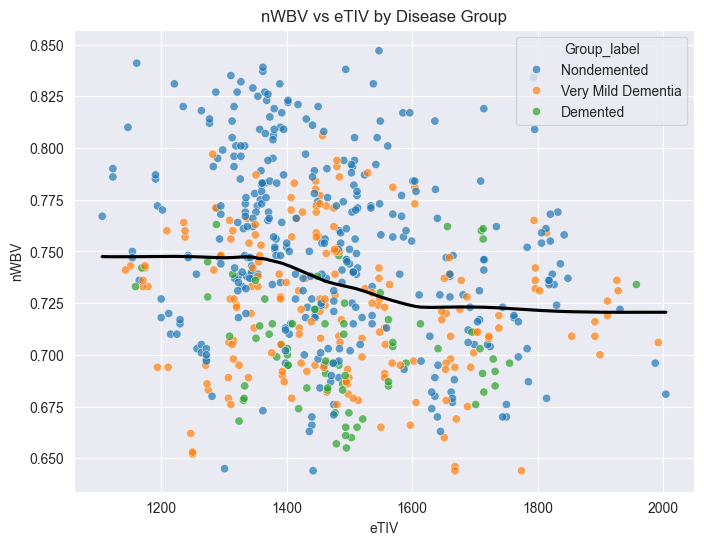

In [100]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_combined_3label,
    x='eTIV',
    y='nWBV',
    hue='Group_label',
    alpha=0.7
)

sns.regplot(
    data=df_combined_3label,
    x='eTIV',
    y='nWBV',
    scatter=False,
    lowess=True,
    color='black'
)

plt.title('nWBV vs eTIV by Disease Group')
plt.show()

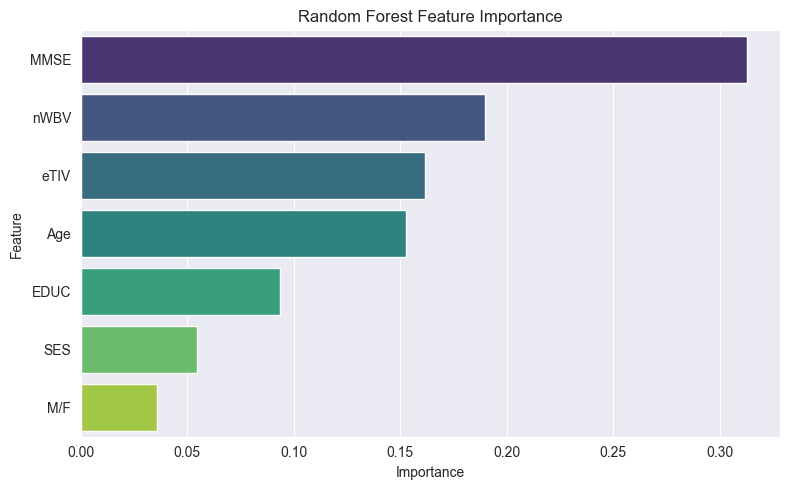

  Feature  Importance
0    MMSE    0.312588
1    nWBV    0.189600
2    eTIV    0.161526
3     Age    0.152826
4    EDUC    0.093416
5     SES    0.054499
6     M/F    0.035545


In [101]:
rf_results = calculate_rf_importance(
    X_df_cb3,
    y_train_3l,
    plot=True,
    title='Random Forest Feature Importance'
)
print(rf_results )

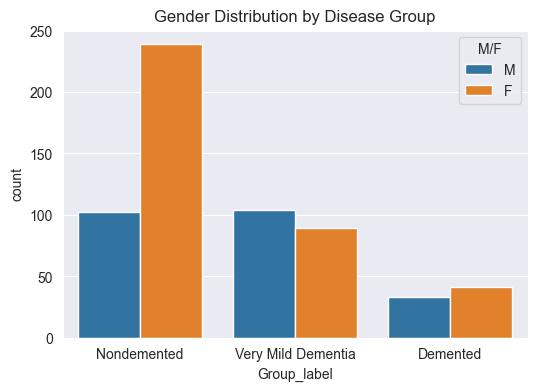

In [102]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df_combined_3label,
    x='Group_label',
    hue='M/F'
)

plt.title("Gender Distribution by Disease Group")
plt.show()

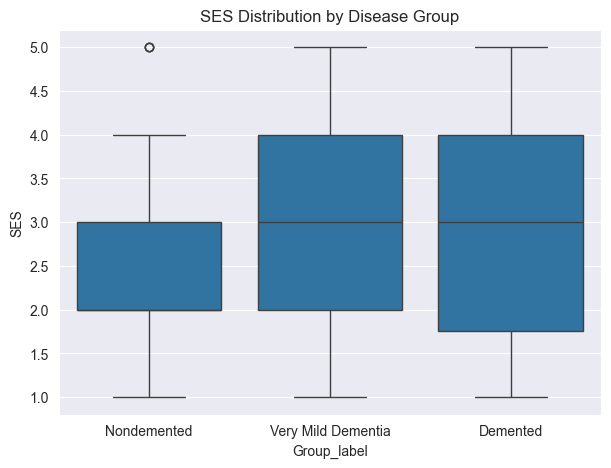

In [103]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df_combined_3label,
    x='Group_label',
    y='SES'
)

plt.title("SES Distribution by Disease Group")
plt.show()

# Helper Functions

In [104]:
# Helper Functions
def plot_confusion(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix – {model_name}")
    plt.show()

def compute_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred)*100,
        "Precision": precision_score(y_true, y_pred, average="macro")*100,
        "Recall": recall_score(y_true, y_pred, average="macro")*100,
        "F1-score": f1_score(y_true, y_pred, average="macro")*100,
    }

def plot_metrics_comparison(results_df, title='Model Performance Comparison'):

    metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']

    x = np.arange(len(results_df.index))
    width = 0.2

    plt.figure(figsize=(12, 6))

    for i, metric in enumerate(metrics):

        bars = plt.bar(
            x + (i - 1.5) * width,
            results_df[metric],
            width,
            label=metric
        )

        plt.bar_label(
            bars,
            fmt='%.3f',
            padding=2,
            fontsize=8
        )

    plt.xticks(
        x,
        results_df.index,
        rotation=30
    )

    plt.ylabel('Score')
    plt.ylim(0, 100)

    plt.title(title)

    plt.legend()

    plt.grid(
        axis='y',
        alpha=0.3
    )

    plt.tight_layout()
    plt.show()

# Model

In [105]:
def evaluate_all_models(X_train, y_train, X_test, y_test, selector=None):
    results = []

    base_models = {
        "Decision Tree": DecisionTreeClassifier(random_state=42),

        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            min_samples_split=5,
            random_state=42
        ),

        "SVM": SVC(
            kernel='rbf',
            C=5,
            gamma='scale',
            probability=True,
            random_state=42
        ),

        "XGBoost": XGBClassifier(
            n_estimators=150,
            max_depth=5,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=1.0,
            eval_metric='logloss',
            random_state=42
        )
    }

    trained_estimators = []

    # ==============================
    # Base Models
    # ==============================
    for name, model in base_models.items():

        if selector is not None:
            current_model = Pipeline([
                ('selector', clone(selector)),
                ('model', model)
            ])
        else:
            current_model = model

        current_model.fit(X_train, y_train)

        y_pred = current_model.predict(X_test)

        results.append({
            "Model": name,
            **compute_metrics(y_test, y_pred)
        })

        plot_confusion(y_test, y_pred, name)

        trained_estimators.append(
            (name.lower().replace(" ", "_"), current_model)
        )

    # ==============================
    # Voting
    # ==============================
    voting = VotingClassifier(
        estimators=trained_estimators,
        voting='soft'
    )

    voting.fit(X_train, y_train)

    y_pred_vote = voting.predict(X_test)

    results.append({
        "Model": "Voting (Soft)",
        **compute_metrics(y_test, y_pred_vote)
    })

    plot_confusion(
        y_test,
        y_pred_vote,
        "Voting (Soft)"
    )

    # ==============================
    # Stacking
    # ==============================
    meta = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    stacking = StackingClassifier(
        estimators=trained_estimators,
        final_estimator=meta,
        stack_method='predict_proba',
        cv=5,
        n_jobs=-1
    )

    stacking.fit(X_train, y_train)

    y_pred_stack = stacking.predict(X_test)
    y_score_stack = stacking.predict_proba(X_test)

    results.append({
        "Model": "Stacking",
        **compute_metrics(y_test, y_pred_stack)
    })

    plot_confusion(
        y_test,
        y_pred_stack,
        "Stacking"
    )
    n_classes = len(np.unique(y_train))

    if n_classes == 2:
        auc = roc_auc_score(
            y_test,
            y_score_stack[:, 1]
        )
    else:
        auc = roc_auc_score(
            y_test,
            y_score_stack,
            multi_class='ovr',
            average='macro'
        )


    results_df = pd.DataFrame(results).set_index("Model").round(4)

    print(results_df)
    plot_metrics_comparison(results_df)

    print(f"ROC-AUC: {auc:.4f}")

    print(
        f"Train Accuracy: "
        f"{accuracy_score(y_train, stacking.predict(X_train)):.4f}"
    )

    print(
        f"Test Accuracy: "
        f"{accuracy_score(y_test, y_pred_stack):.4f}"
    )
    
    return {
    "Decision Tree": trained_estimators[0][1],
    "Random Forest": trained_estimators[1][1],
    "SVM": trained_estimators[2][1],
    "XGBoost": trained_estimators[3][1],
    "Voting": voting,
    "Stacking": stacking
    }


# model_with_anova_selector

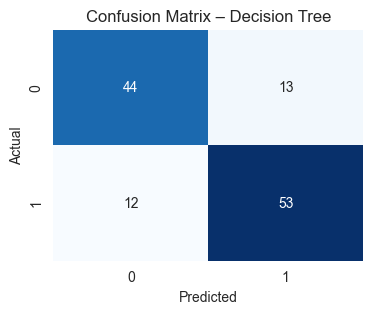

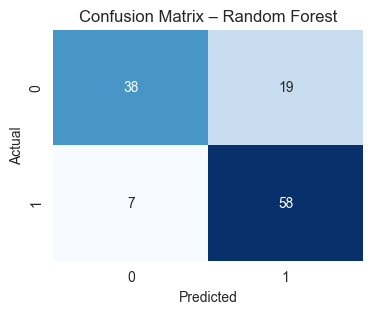

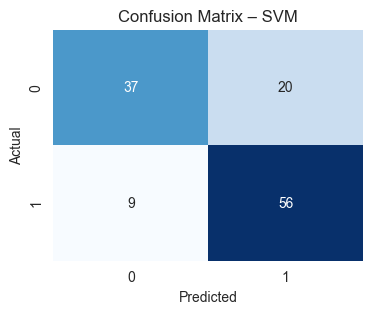

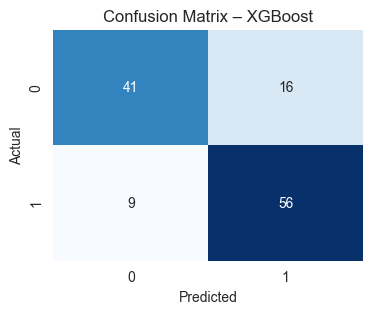

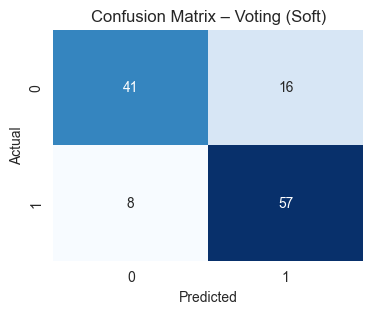

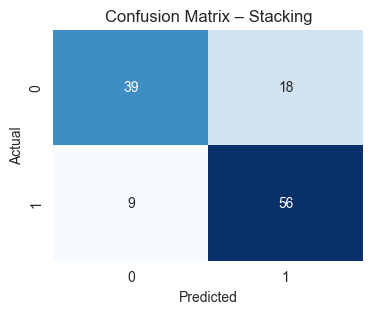

               Accuracy  Precision   Recall  F1-score
Model                                                
Decision Tree   79.5082    79.4372  79.3657   79.3961
Random Forest   78.6885    79.8846  77.9487   78.1000
SVM             76.2295    77.0595  75.5331   75.6386
XGBoost         79.5082    79.8889  79.0418   79.1937
Voting (Soft)   80.3279    80.8778  79.8111   79.9836
Stacking        77.8689    78.4628  77.2874   77.4306


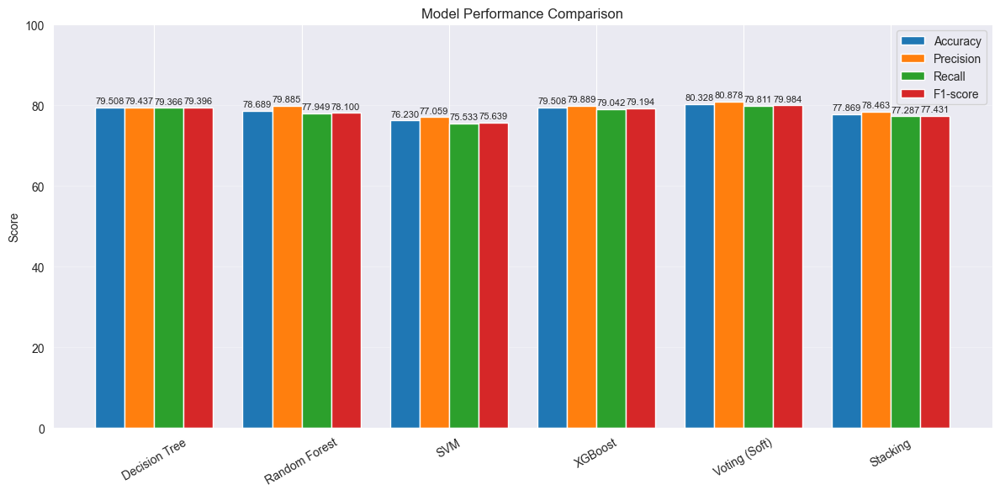

ROC-AUC: 0.8602
Train Accuracy: 0.9280
Test Accuracy: 0.7787


In [106]:
model_with_anova_selector = evaluate_all_models(X_df_cb,y_train_cb, X_test_processed_cb, y_test_cb, selector_anova_cb)

# model_without_selector

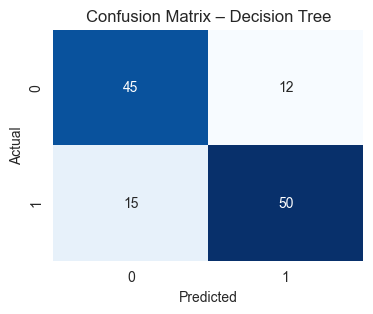

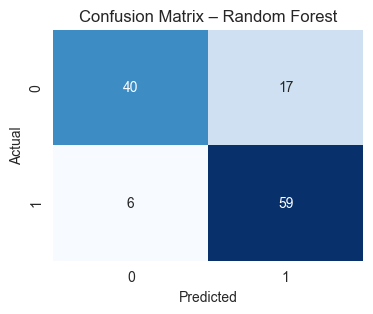

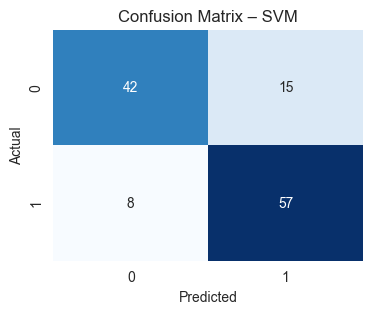

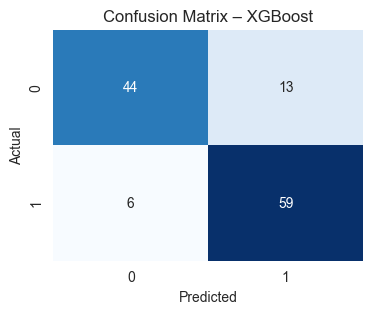

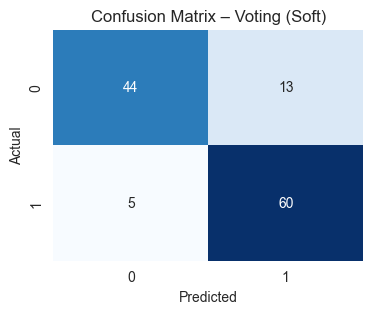

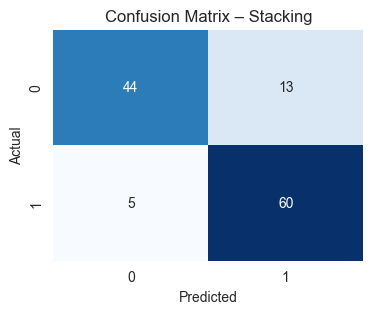

               Accuracy  Precision   Recall  F1-score
Model                                                
Decision Tree   77.8689    77.8226  77.9352   77.8316
Random Forest   81.1475    82.2941  80.4723   80.6789
SVM             81.1475    81.5833  80.6883   80.8582
XGBoost         84.4262    84.9722  83.9811   84.1872
Voting (Soft)   85.2459    85.9938  84.7503   84.9877
Stacking        85.2459    85.9938  84.7503   84.9877


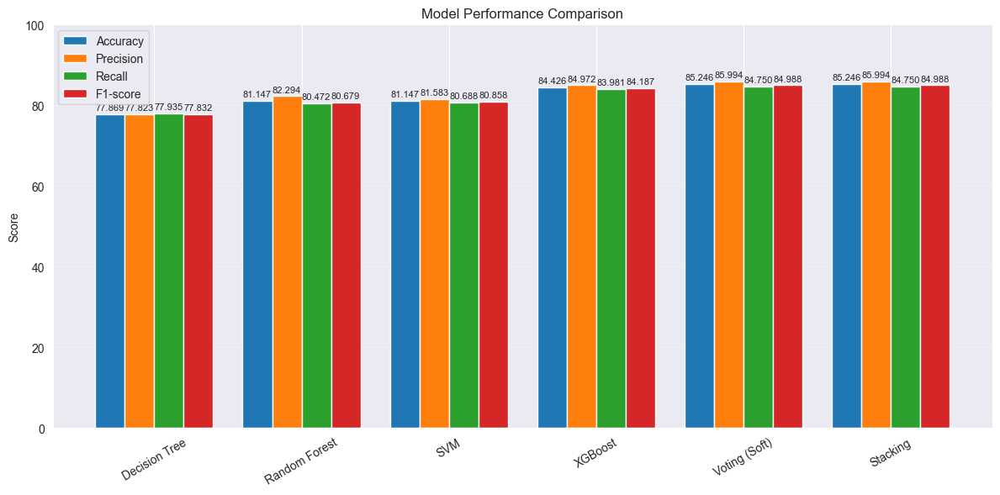

ROC-AUC: 0.9055
Train Accuracy: 0.9918
Test Accuracy: 0.8525


In [107]:
model_without_selector = evaluate_all_models(X_df_cb,y_train_cb, X_test_processed_cb, y_test_cb)

# model_with_rf_selector

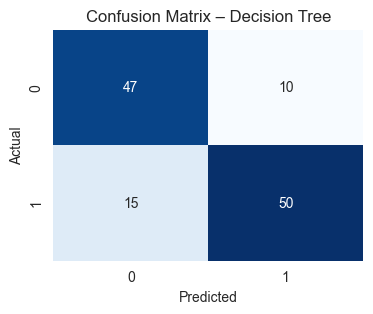

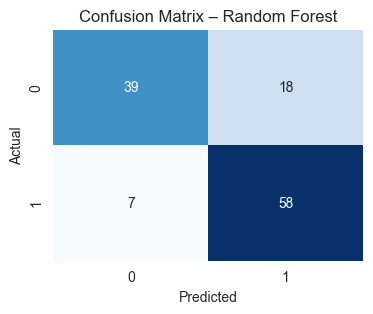

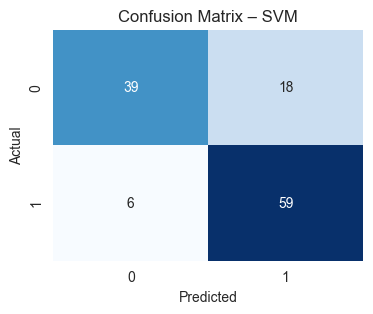

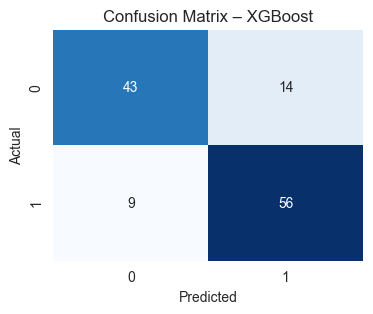

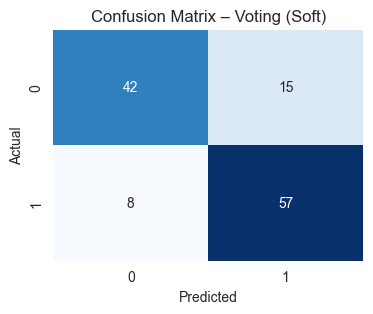

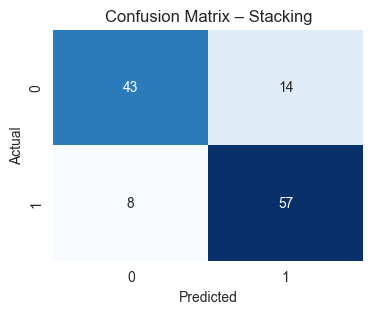

               Accuracy  Precision   Recall  F1-score
Model                                                
Decision Tree   79.5082    79.5699  79.6896   79.4958
Random Forest   79.5082    80.5492  78.8259   78.9988
SVM             80.3279    81.6450  79.5951   79.7846
XGBoost         81.1475    81.3462  80.7962   80.9310
Voting (Soft)   81.1475    81.5833  80.6883   80.8582
Stacking        81.9672    82.2977  81.5655   81.7266


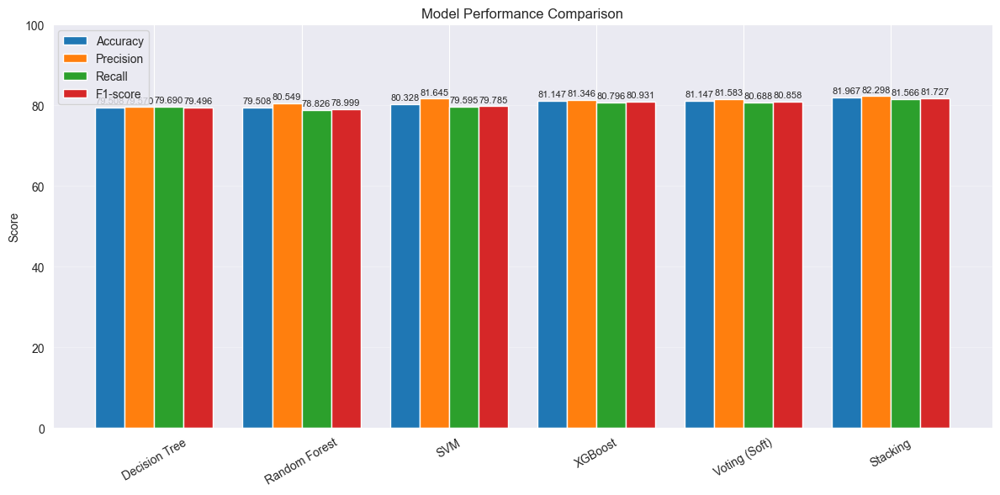

ROC-AUC: 0.8672
Train Accuracy: 0.9815
Test Accuracy: 0.8197


In [108]:
model_with_rf_selector = evaluate_all_models( X_df_cb,y_train_cb, X_test_processed_cb, y_test_cb,
                    selector=SelectFromModel(
                        RandomForestClassifier(
                        n_estimators=100,
                        random_state=42
                        ),
                        threshold='median'
                     )
)

# model3l_with_anova_selector

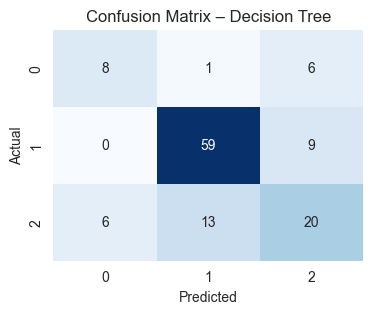

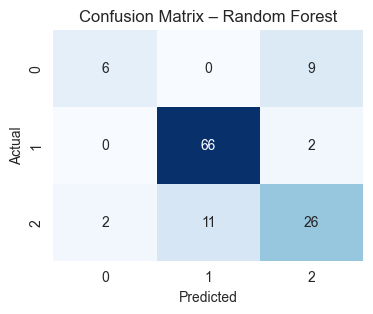

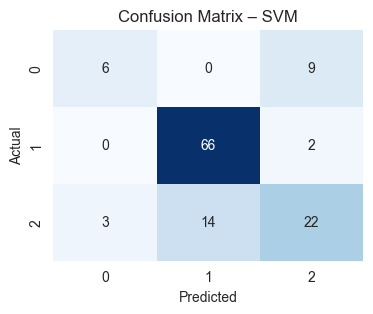

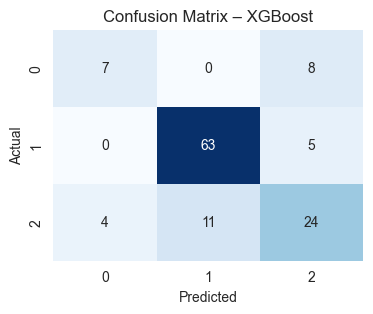

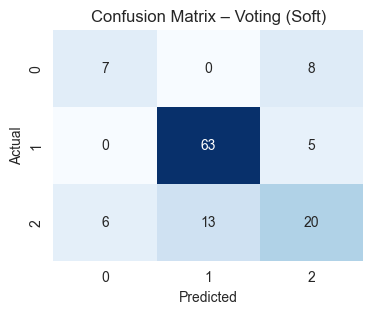

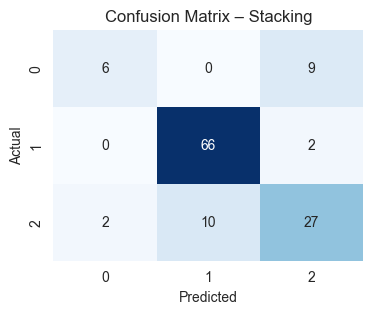

               Accuracy  Precision   Recall  F1-score
Model                                                
Decision Tree   71.3115    65.0359  63.7934   64.3048
Random Forest   80.3279    76.9949  67.9085   70.5431
SVM             77.0492    71.9444  64.4897   66.7668
XGBoost         77.0492    71.2121  66.9507   68.5788
Voting (Soft)   73.7705    65.7823  63.5319   64.3519
Stacking        81.1475    77.6316  68.7632   71.3235


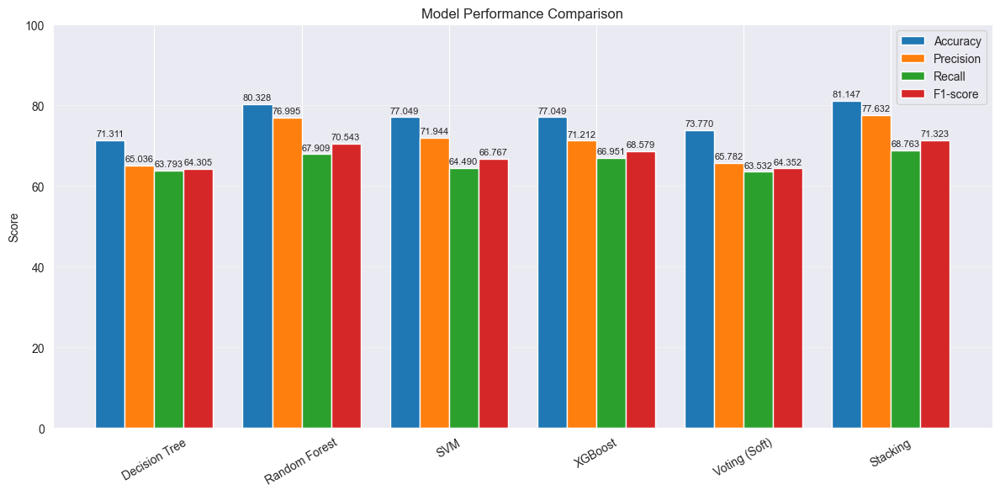

ROC-AUC: 0.9060
Train Accuracy: 0.9095
Test Accuracy: 0.8115


In [109]:
model3l_with_anova_selector = evaluate_all_models(X_df_cb3,y_train_3l, X_test_processed_3l, y_test_3l, selector_anova_3l)

# model3l_without_selector

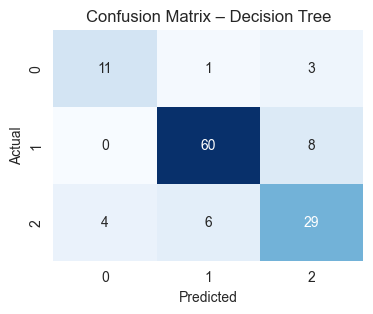

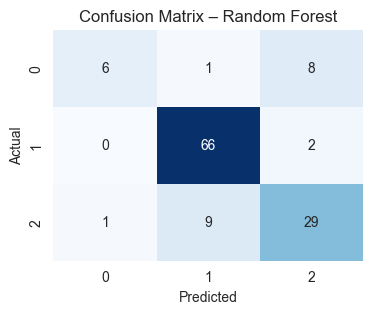

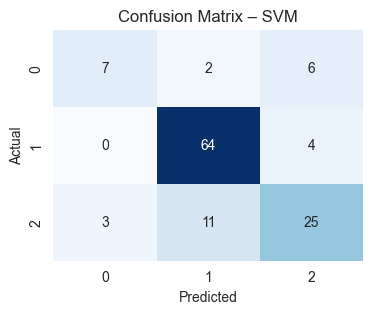

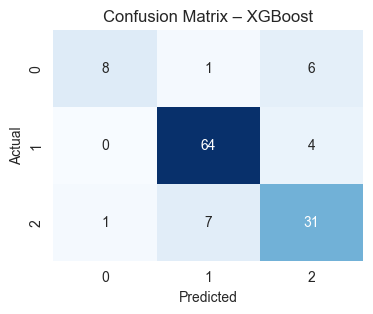

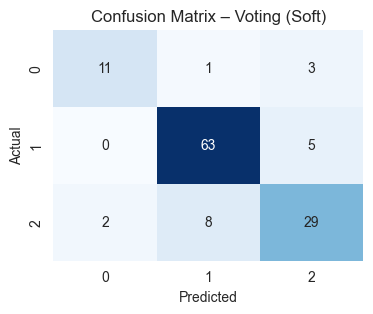

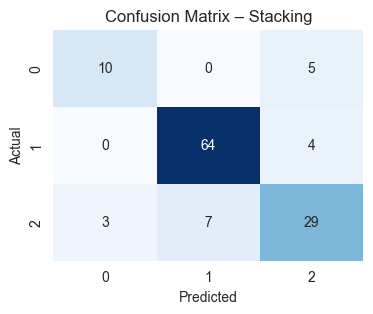

               Accuracy  Precision   Recall  F1-score
Model                                                
Decision Tree   81.9672    78.4619  78.6425   78.5466
Random Forest   82.7869    82.3051  70.4726   73.5237
SVM             78.6885    74.8485  68.2956   70.6145
XGBoost         84.4262    84.4625  75.6461   78.5317
Voting (Soft)   84.4262    83.4979  80.1131   81.6291
Stacking        84.4262    81.1266  78.3811   79.6132


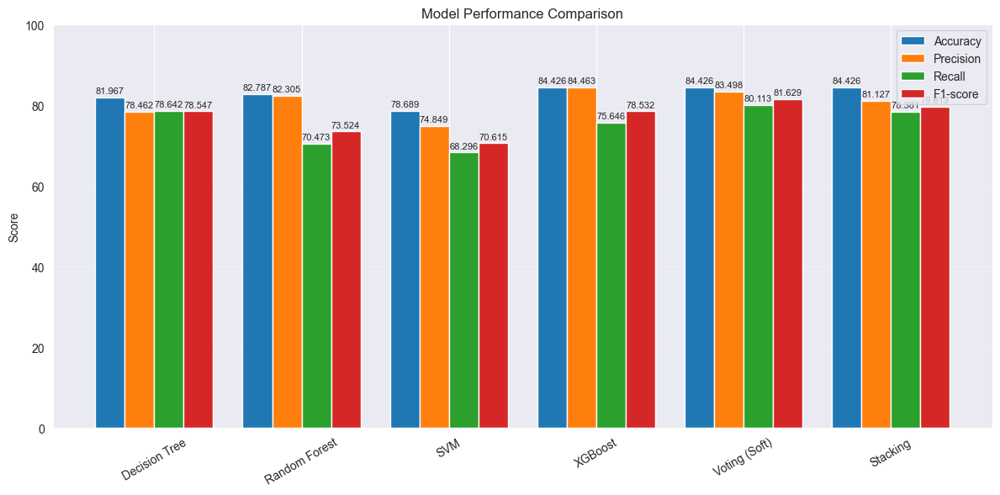

ROC-AUC: 0.9436
Train Accuracy: 0.9959
Test Accuracy: 0.8443


In [110]:
model3l_without_selector = evaluate_all_models(X_df_cb3,y_train_3l, X_test_processed_3l, y_test_3l)

# model3l_with_rf_selector

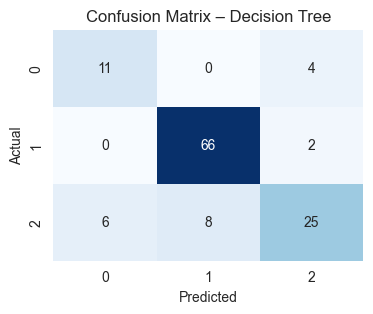

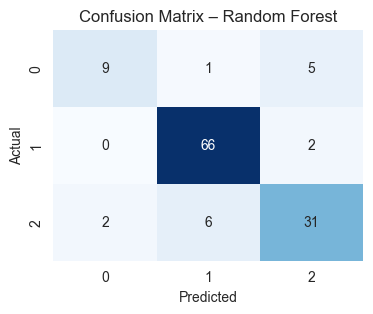

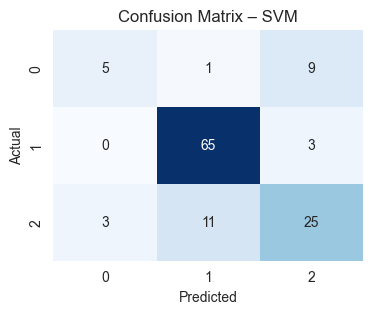

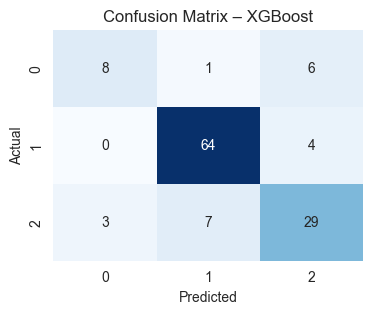

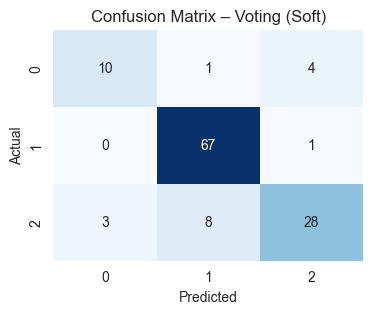

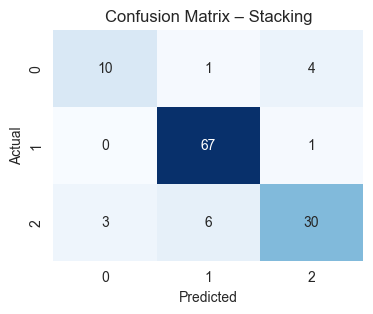

               Accuracy  Precision   Recall  F1-score
Model                                                
Decision Tree   83.6066    78.1801  78.1649   77.7121
Random Forest   86.8852    84.6027  78.8487   81.1224
SVM             77.8689    71.4944  64.3414   66.3076
XGBoost         82.7869    78.6584  73.9367   75.7753
Voting (Soft)   86.0656    83.3098  78.9970   80.7540
Stacking        87.7049    84.3926  80.7064   82.2919


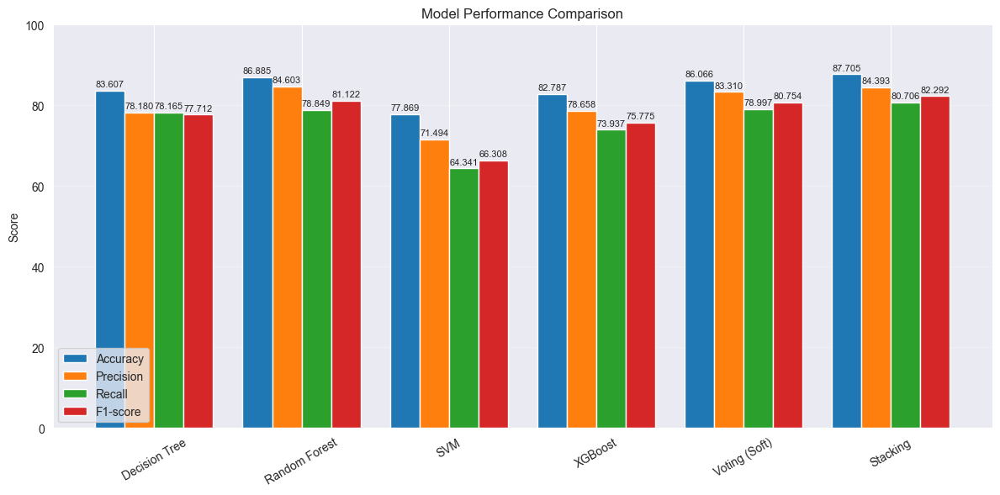

ROC-AUC: 0.9313
Train Accuracy: 0.9856
Test Accuracy: 0.8770


In [111]:
model3l_with_rf_selector = evaluate_all_models(X_df_cb3,y_train_3l, X_test_processed_3l, y_test_3l,
                                            selector=SelectFromModel(
                                                RandomForestClassifier(
                                                n_estimators=100,
                                                random_state=42
                                                ),
                                                threshold='median'
                                            )
)

# model3l_smotenc_rf_selector

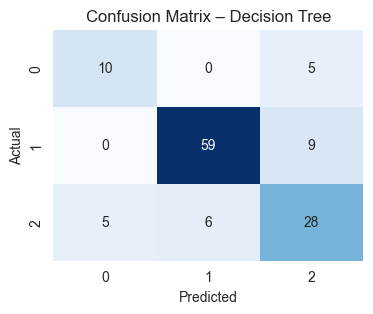

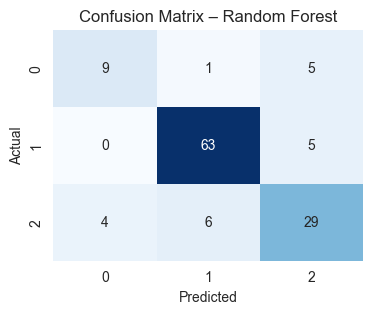

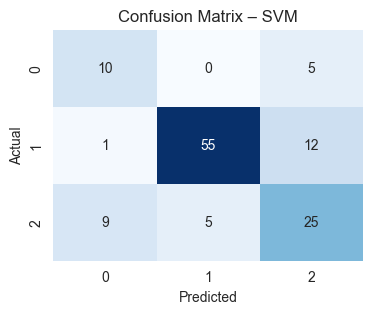

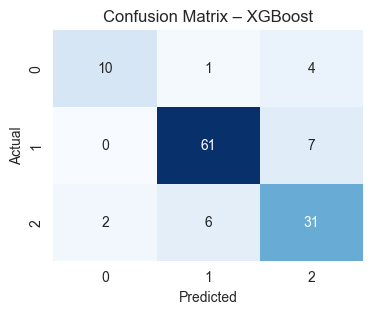

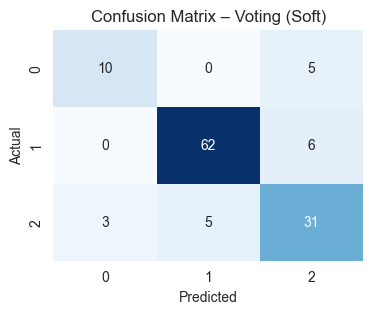

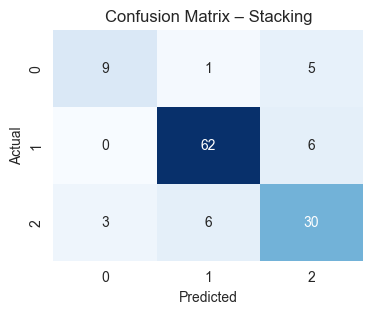

               Accuracy  Precision   Recall  F1-score
Model                                                
Decision Tree   79.5082    74.7009  75.0754   74.8414
Random Forest   82.7869    77.8632  75.6687   76.6497
SVM             73.7705    67.0635  70.5505   68.2696
XGBoost         83.6066    82.2829  78.6199   80.1077
Voting (Soft)   84.4262    81.0900  79.1101   79.9412
Stacking        82.7869    79.3419  76.0332   77.3925


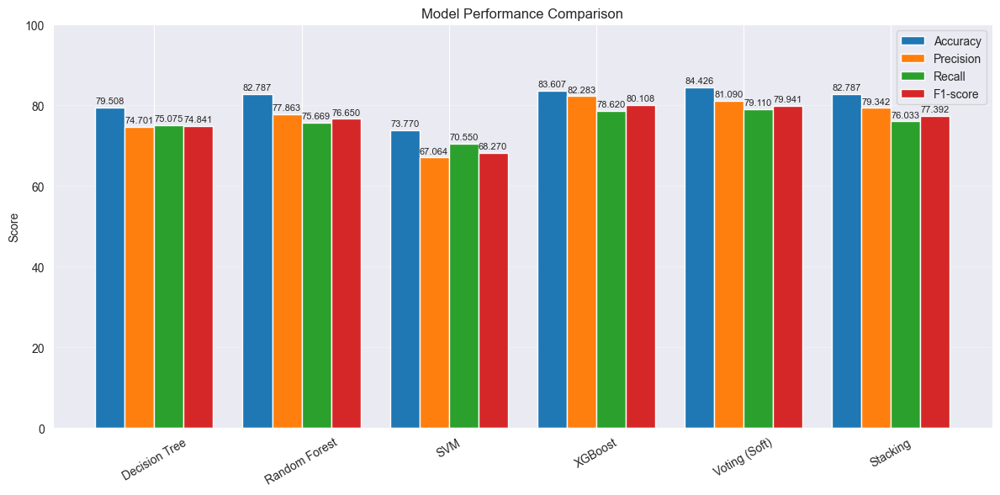

ROC-AUC: 0.9226
Train Accuracy: 0.9890
Test Accuracy: 0.8279


In [112]:
model3l_smotenc_rf_selector = evaluate_all_models(
    X_nd_combined_3l_smotenc,
    y_train_3l_smotenc,
    X_test_processed_3l_smotenc,
    y_test_3l_smotenc,
    selector=SelectFromModel(
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),
        threshold='median'
    )
)

# EVALUATION

## ROC-AUC

In [113]:
def plot_binary_roc(models, X_test, y_test):

    fig, ax = plt.subplots(figsize=(10, 10))

    for name, model in models.items():

        RocCurveDisplay.from_estimator(
            estimator=model,
            X=X_test,
            y=y_test,
            name=name,
            ax=ax
        )

    ax.set_title("ROC Curve Comparison")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

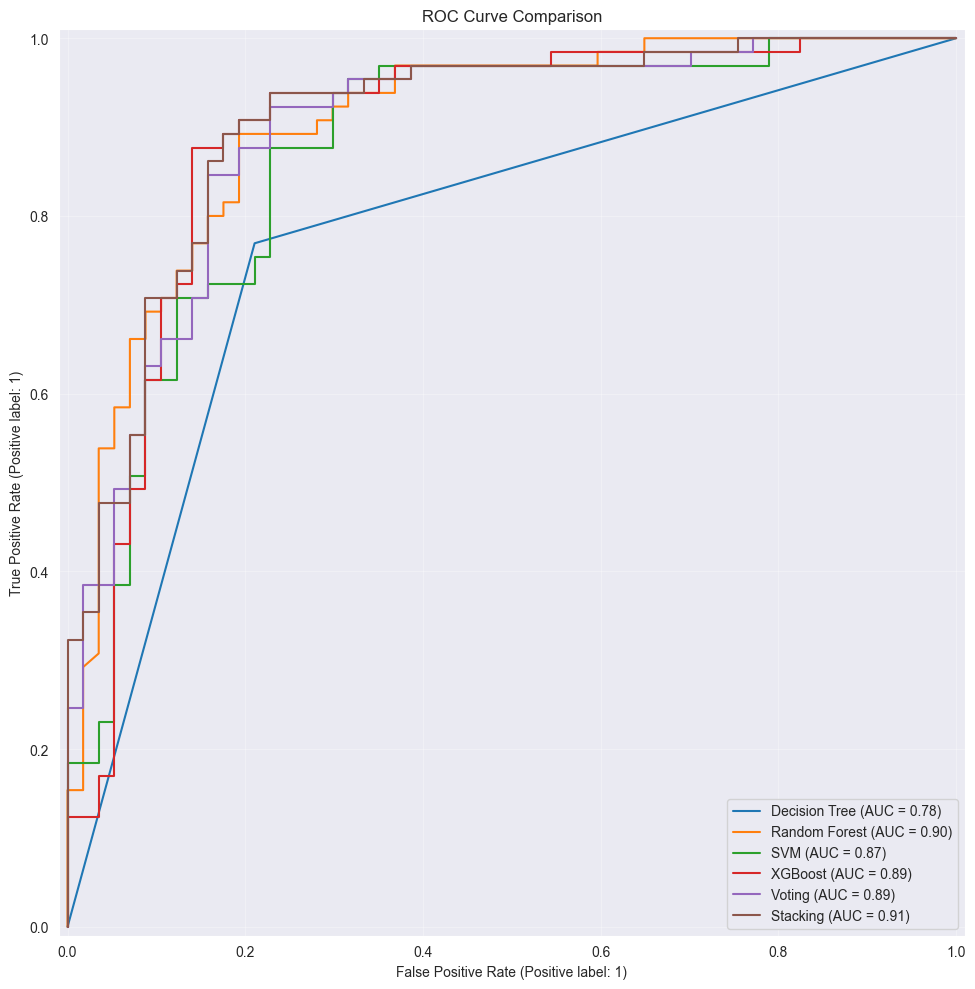

In [114]:
plot_binary_roc(
    models=model_without_selector,
    X_test=X_test_processed_cb,
    y_test=y_test_cb
)

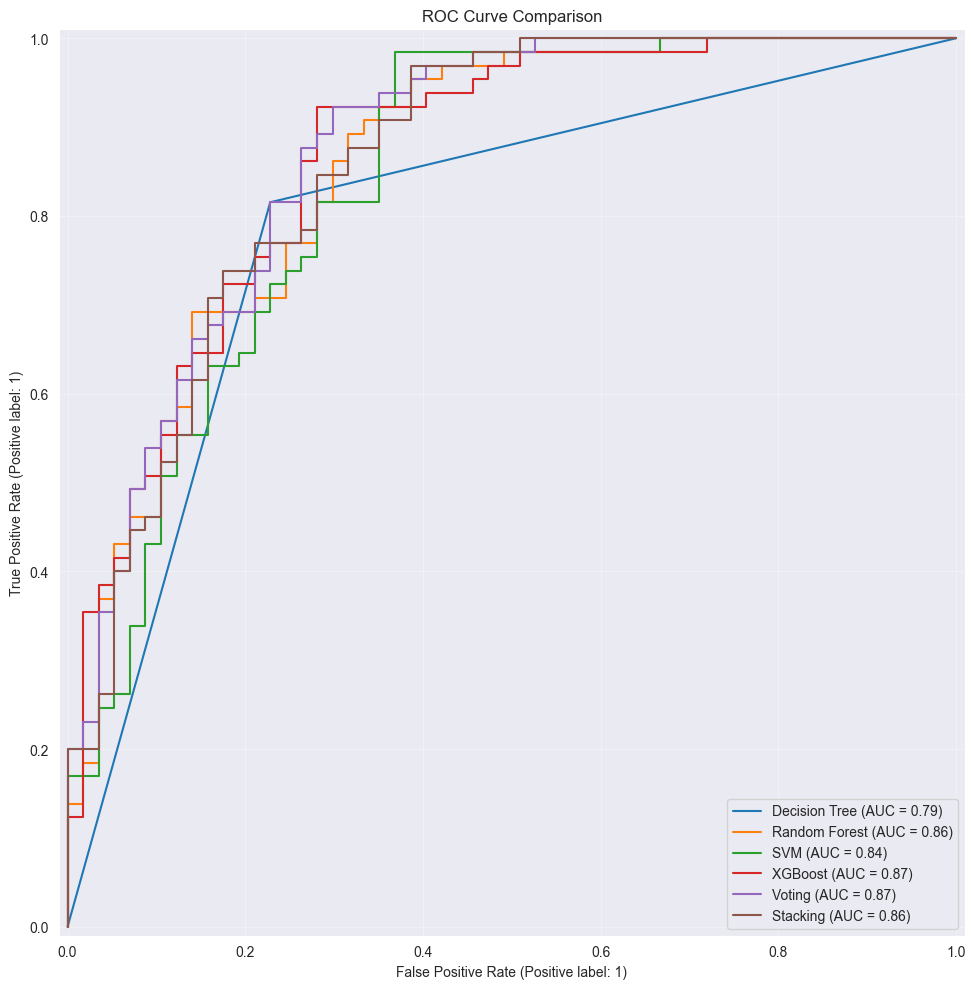

In [115]:
plot_binary_roc(
    models=model_with_anova_selector,
    X_test=X_test_processed_cb,
    y_test=y_test_cb
)

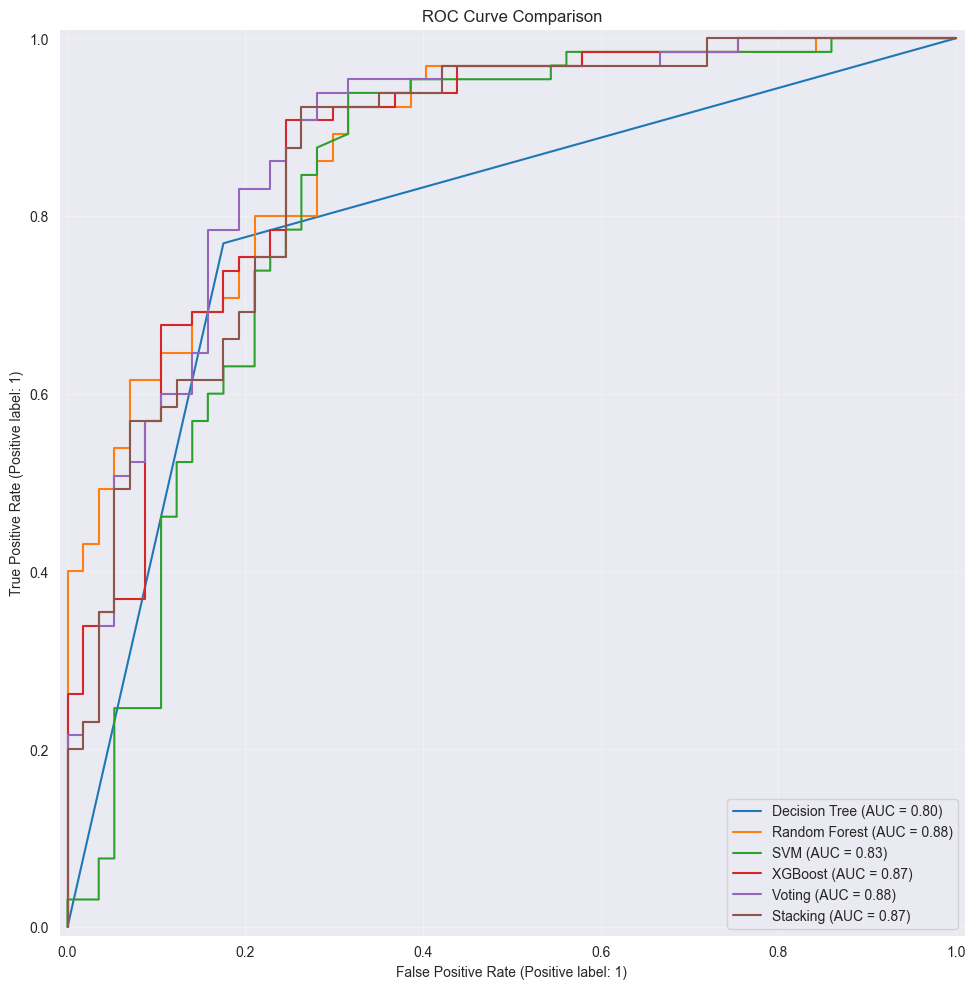

In [116]:
plot_binary_roc(
    models=model_with_rf_selector,
    X_test=X_test_processed_cb,
    y_test=y_test_cb
)

## ROC-AUC-3L

In [117]:
def plot_multiclass_roc(models, X_test, y_test):

    classes = np.unique(y_test)
    y_test_bin = label_binarize(y_test, classes=classes)

    fig, ax = plt.subplots(figsize=(10, 8))

    for name, model in models.items():

        y_score = model.predict_proba(X_test)

        fpr, tpr, _ = roc_curve(
            y_test_bin.ravel(),
            y_score.ravel()
        )

        roc_auc = auc(fpr, tpr)

        ax.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{name} (AUC = {roc_auc:.3f})"
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="black"
    )

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("ROC Curve Comparison (Multiclass)")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

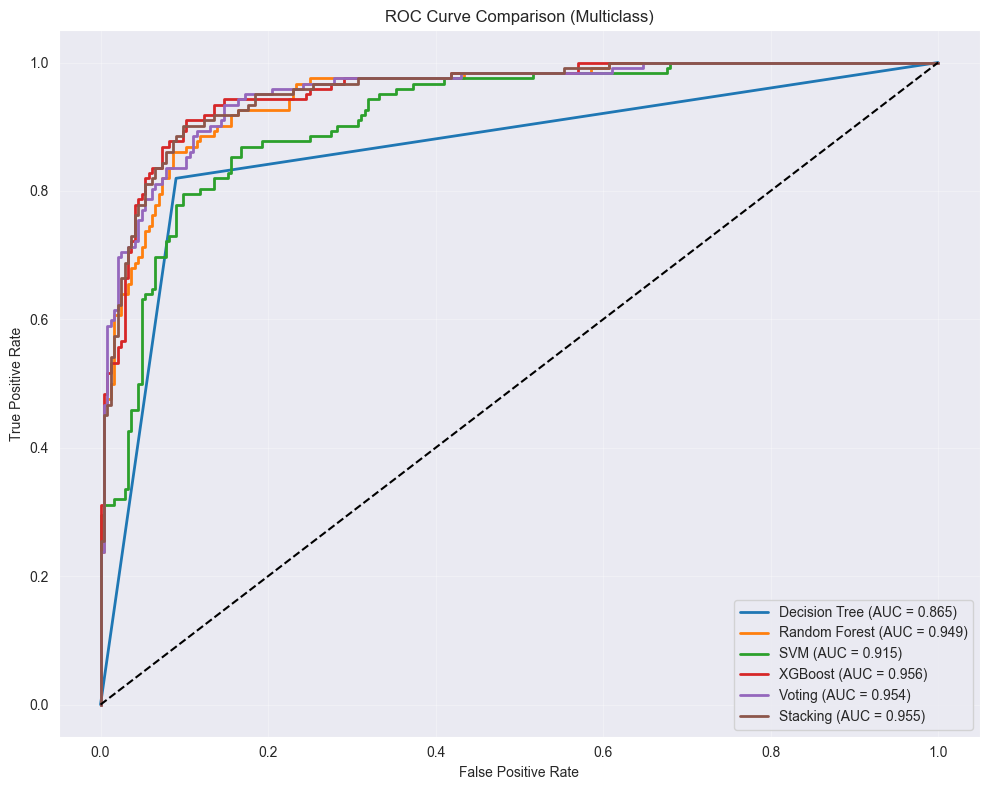

In [118]:
plot_multiclass_roc(
    models=model3l_without_selector,
    X_test=X_test_processed_3l,
    y_test=y_test_3l
)

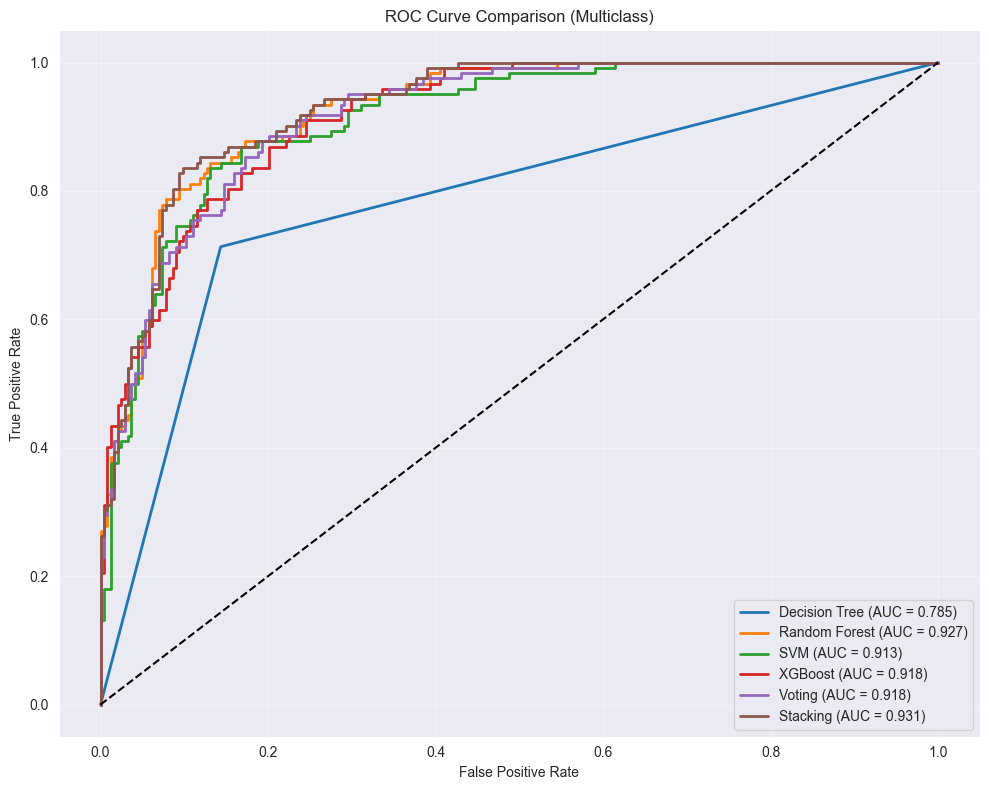

In [119]:
plot_multiclass_roc(
    models=model3l_with_anova_selector,
    X_test=X_test_processed_3l,
    y_test=y_test_3l
)

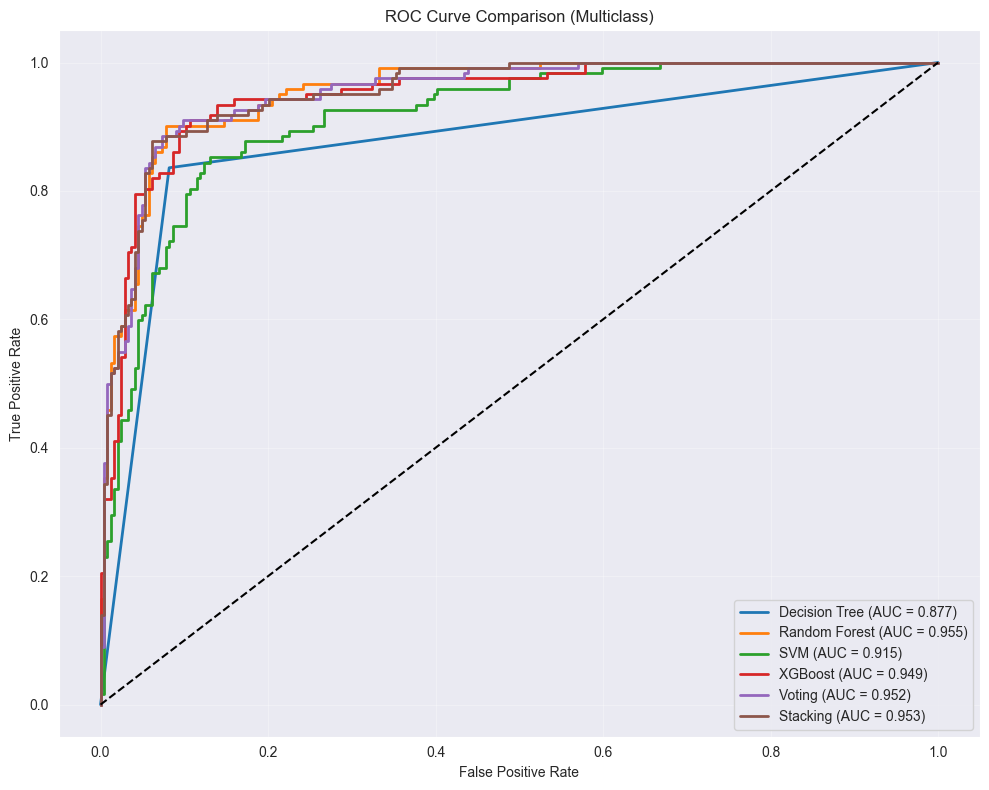

In [120]:
plot_multiclass_roc(
    models=model3l_with_rf_selector,
    X_test=X_test_processed_3l,
    y_test=y_test_3l
)

## Learning Curve

In [121]:

def plot_learning_curve_stacking(
    stacking_model,
    X,
    y,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
):

    sizes, train_scores, val_scores = learning_curve(
        estimator=stacking_model,
        X=X,
        y=y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        train_sizes=train_sizes
    )

    train_mean = np.mean(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)

    plt.figure(figsize=(8, 6))

    plt.plot(
        sizes,
        train_mean,
        marker='o',
        label='Training Accuracy'
    )

    plt.plot(
        sizes,
        val_mean,
        marker='o',
        label='Validation Accuracy'
    )

    plt.title('Learning Curve - Stacking')
    plt.xlabel('Training Size')
    plt.ylabel(scoring.capitalize())
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_learning_curve_comparison(
    models,
    X,
    y,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
):
    plt.figure(figsize=(10, 7))

    for name, model in models.items():

        sizes, _, val_scores = learning_curve(
            estimator=model,
            X=X,
            y=y,
            cv=cv,
            scoring=scoring,
            n_jobs=-1,
            train_sizes=train_sizes
        )

        plt.plot(
            sizes,
            np.mean(val_scores, axis=1),
            marker='o',
            label=name
        )

    plt.xlabel('Training Size')
    plt.ylabel(scoring.capitalize())
    plt.title('Learning Curve Comparison')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

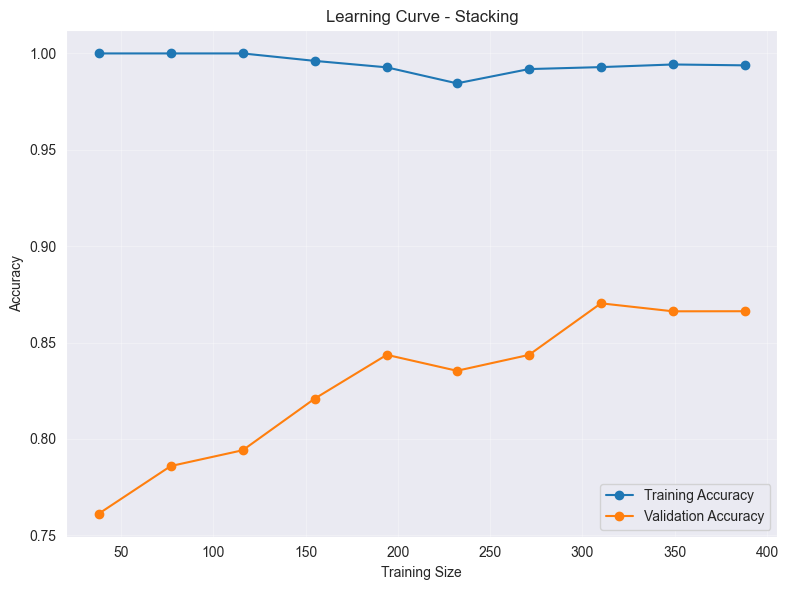

In [122]:
plot_learning_curve_stacking(
    stacking_model=model_without_selector["Stacking"],
    X=X_df_cb,
    y=y_train_cb
)

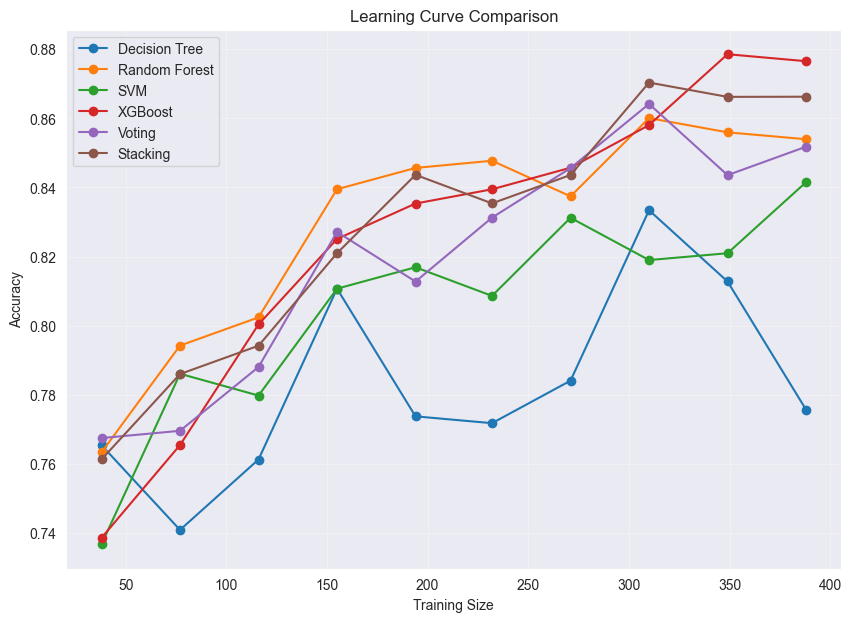

In [123]:
plot_learning_curve_comparison(
    model_without_selector,
    X_df_cb,
    y_train_cb
)

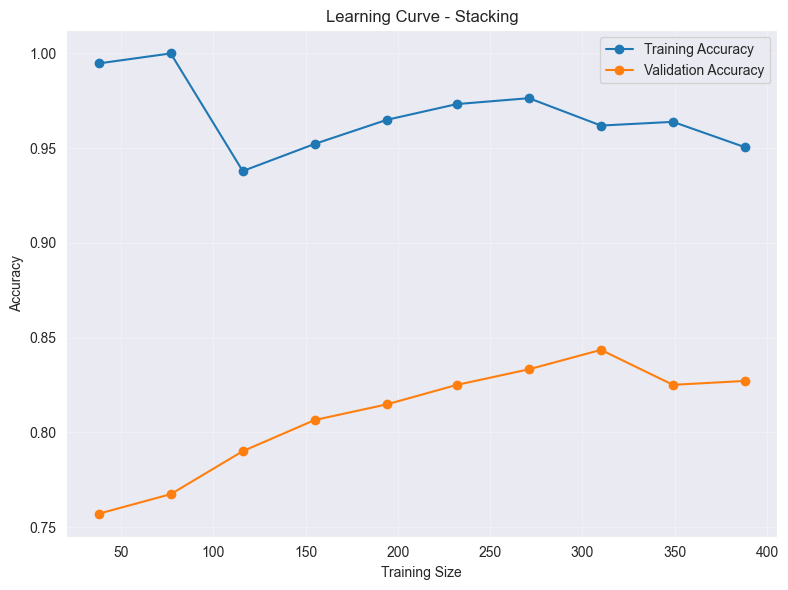

In [124]:
plot_learning_curve_stacking(
    stacking_model=model_with_anova_selector["Stacking"],
    X=X_df_cb,
    y=y_train_cb
)

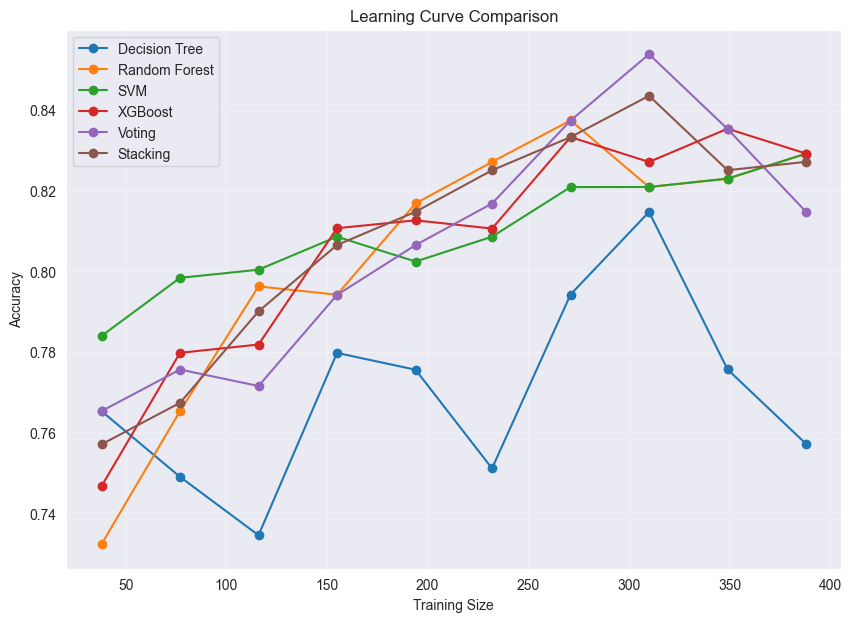

In [125]:
plot_learning_curve_comparison(
    model_with_anova_selector,
    X_df_cb,
    y_train_cb
)

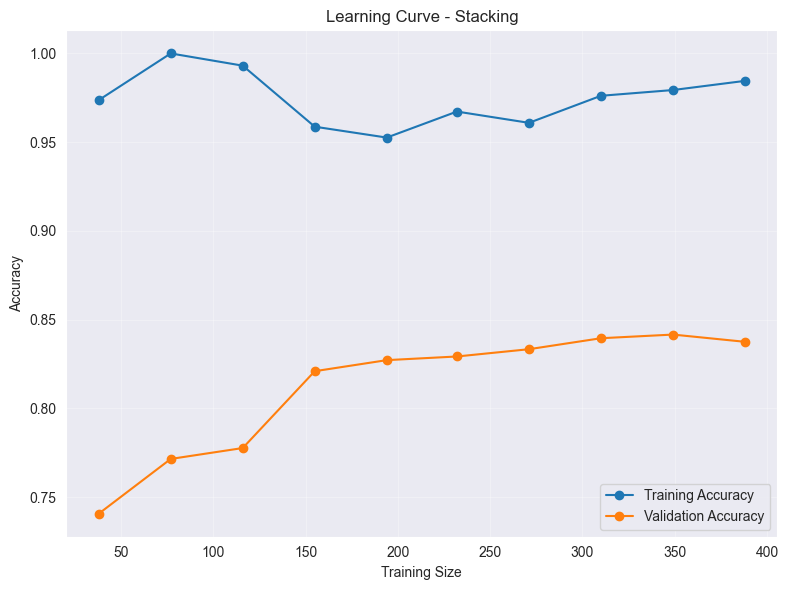

In [126]:
plot_learning_curve_stacking(
    stacking_model = model_with_rf_selector["Stacking"],
    X=X_df_cb,
    y=y_train_cb
)

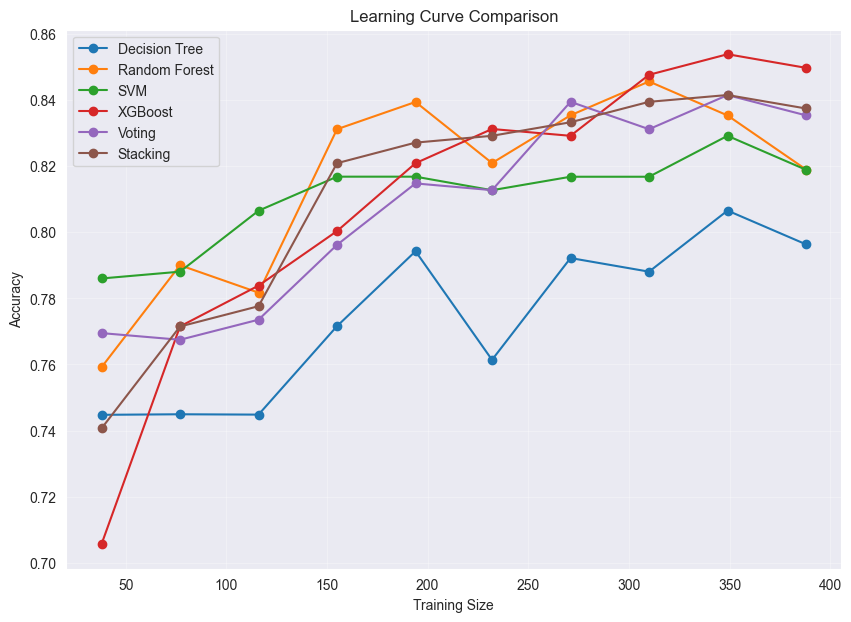

In [127]:
plot_learning_curve_comparison(
    model_with_rf_selector,
    X_df_cb,
    y_train_cb
)

## lC-3L

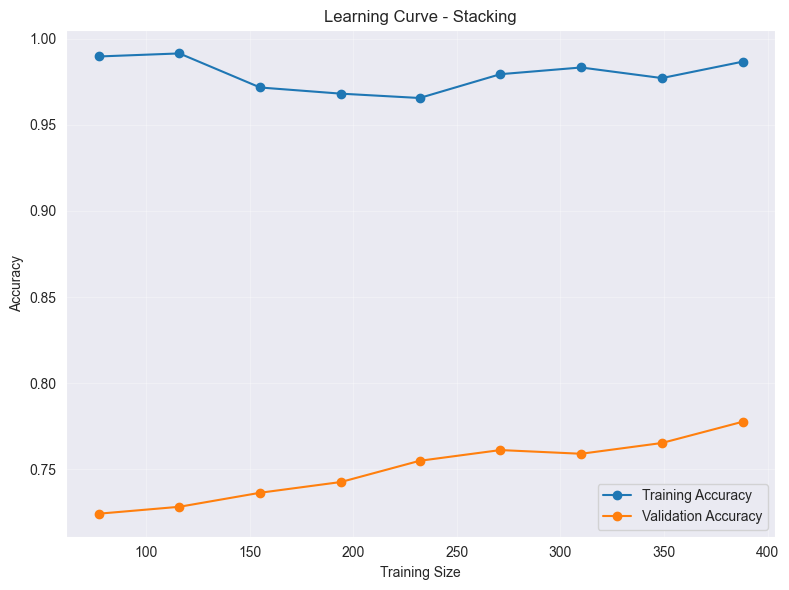

In [128]:
plot_learning_curve_stacking(
    stacking_model=model3l_without_selector["Stacking"],
    X=X_df_cb3,
    y=y_train_3l
)

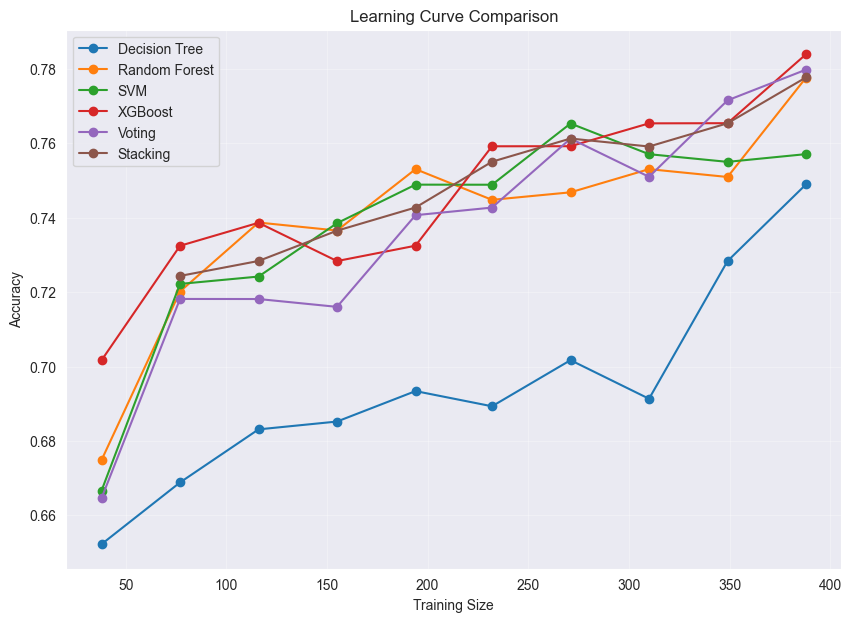

In [129]:
plot_learning_curve_comparison(
    model3l_without_selector,
    X=X_df_cb3,
    y=y_train_3l
)

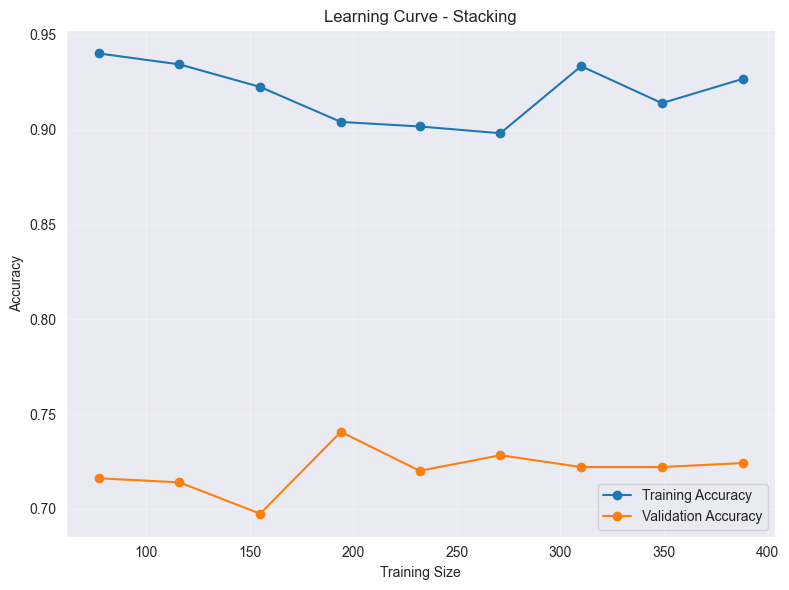

In [130]:
plot_learning_curve_stacking(
    stacking_model=model3l_with_anova_selector["Stacking"],
    X=X_df_cb3,
    y=y_train_3l
)

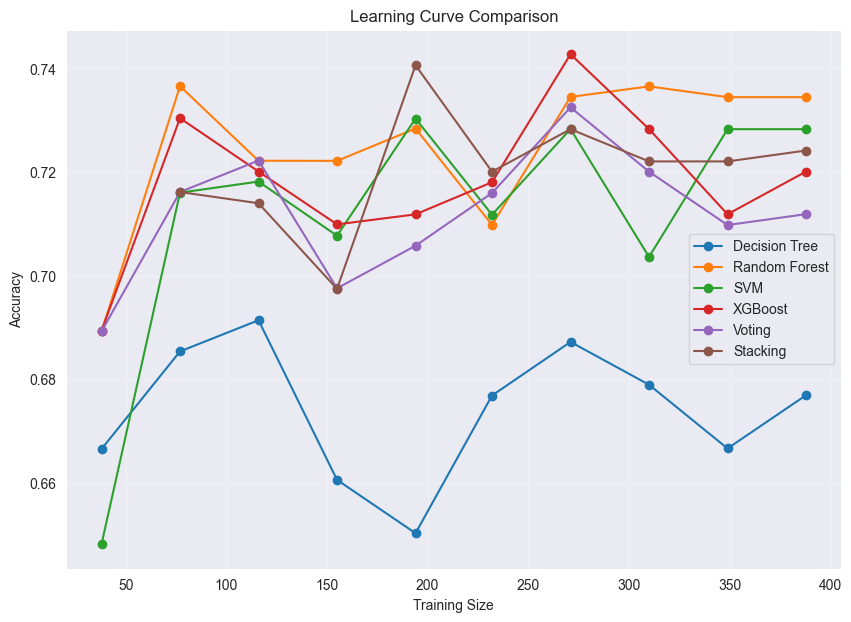

In [131]:
plot_learning_curve_comparison(
    model3l_with_anova_selector,
    X=X_df_cb3,
    y=y_train_3l
)

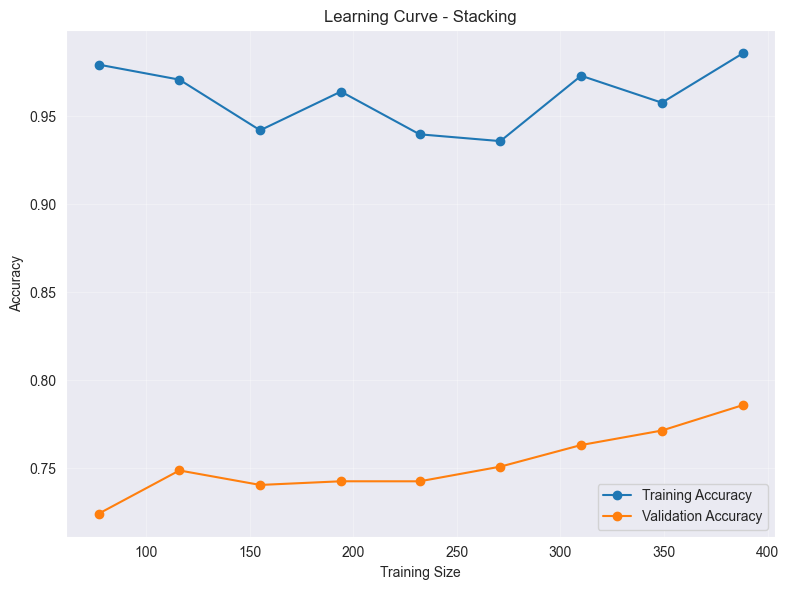

In [132]:
plot_learning_curve_stacking(
    stacking_model=model3l_with_rf_selector["Stacking"],
    X=X_df_cb3,
    y=y_train_3l
)

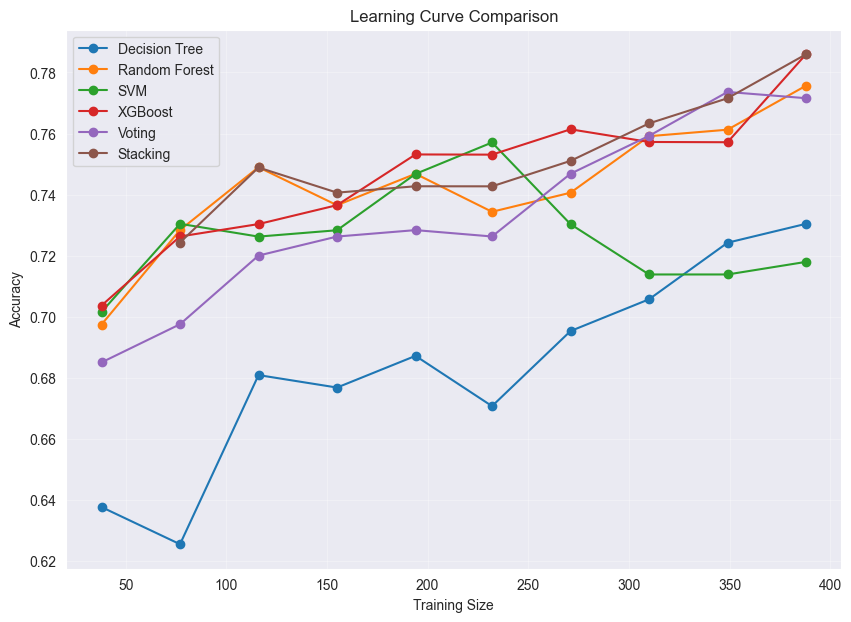

In [133]:
plot_learning_curve_comparison(
    model3l_with_rf_selector,
    X=X_df_cb3,
    y=y_train_3l
)

## StratifiedKFold

In [134]:
def evaluate_cv(model, X, y, model_name):

    cv_strategy = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv_strategy,
        scoring='accuracy',
        n_jobs=-1
    )

    print(f"\n===== {model_name} =====")

    for i, score in enumerate(scores, 1):
        print(f"Fold {i}: Accuracy = {score:.4f}")

    print("-" * 50)
    print(f"Mean Accuracy : {scores.mean():.4f}")
    print(f"Std Accuracy  : {scores.std():.4f}")

    return scores

In [135]:
def evaluate_all_cv(models, X, y):

    cv_results = {}

    for name, model in models.items():

        scores = evaluate_cv(
            model=model,
            X=X,
            y=y,
            model_name=name
        )

        cv_results[name] = scores

    return cv_results

### Combine

In [136]:
cv_results = evaluate_all_cv(
    model3l_without_selector,
    X=X_df_cb3,
    y=y_train_3l
)


===== Decision Tree =====
Fold 1: Accuracy = 0.6735
Fold 2: Accuracy = 0.7216
Fold 3: Accuracy = 0.7629
Fold 4: Accuracy = 0.6598
Fold 5: Accuracy = 0.7216
--------------------------------------------------
Mean Accuracy : 0.7079
Std Accuracy  : 0.0372

===== Random Forest =====
Fold 1: Accuracy = 0.7449
Fold 2: Accuracy = 0.8247
Fold 3: Accuracy = 0.7938
Fold 4: Accuracy = 0.7732
Fold 5: Accuracy = 0.7629
--------------------------------------------------
Mean Accuracy : 0.7799
Std Accuracy  : 0.0274

===== SVM =====
Fold 1: Accuracy = 0.7449
Fold 2: Accuracy = 0.7629
Fold 3: Accuracy = 0.7732
Fold 4: Accuracy = 0.7938
Fold 5: Accuracy = 0.6804
--------------------------------------------------
Mean Accuracy : 0.7510
Std Accuracy  : 0.0387

===== XGBoost =====
Fold 1: Accuracy = 0.7347
Fold 2: Accuracy = 0.7629
Fold 3: Accuracy = 0.8144
Fold 4: Accuracy = 0.7938
Fold 5: Accuracy = 0.7835
--------------------------------------------------
Mean Accuracy : 0.7779
Std Accuracy  : 0.0272


In [137]:
cv_results = evaluate_all_cv(
    model_without_selector,
    X_df_cb,
    y_train_cb
)


===== Decision Tree =====
Fold 1: Accuracy = 0.8265
Fold 2: Accuracy = 0.8041
Fold 3: Accuracy = 0.8144
Fold 4: Accuracy = 0.7216
Fold 5: Accuracy = 0.8866
--------------------------------------------------
Mean Accuracy : 0.8107
Std Accuracy  : 0.0529

===== Random Forest =====
Fold 1: Accuracy = 0.8571
Fold 2: Accuracy = 0.8969
Fold 3: Accuracy = 0.8247
Fold 4: Accuracy = 0.7732
Fold 5: Accuracy = 0.8866
--------------------------------------------------
Mean Accuracy : 0.8477
Std Accuracy  : 0.0449

===== SVM =====
Fold 1: Accuracy = 0.8571
Fold 2: Accuracy = 0.8557
Fold 3: Accuracy = 0.7526
Fold 4: Accuracy = 0.6907
Fold 5: Accuracy = 0.8557
--------------------------------------------------
Mean Accuracy : 0.8024
Std Accuracy  : 0.0687

===== XGBoost =====
Fold 1: Accuracy = 0.8980
Fold 2: Accuracy = 0.9072
Fold 3: Accuracy = 0.8454
Fold 4: Accuracy = 0.7423
Fold 5: Accuracy = 0.9381
--------------------------------------------------
Mean Accuracy : 0.8662
Std Accuracy  : 0.0688


In [138]:
cv_all = {}
cv_anova = {}
cv_mutual = {}

for name, model in model_without_selector.items():
    cv_all[name] = cross_val_score(
        model,
        X_df_cb,
        y_train_cb,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

for name, model in model_with_anova_selector.items():
    cv_anova[name] = cross_val_score(
        model,
        X_df_cb,
        y_train_cb,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

for name, model in model_with_rf_selector.items():
    cv_mutual[name] = cross_val_score(
        model,
        X_df_cb,
        y_train_cb,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

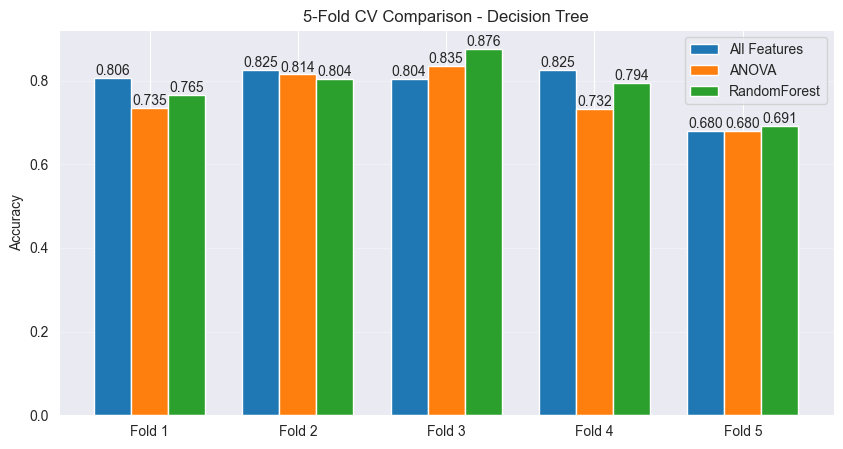

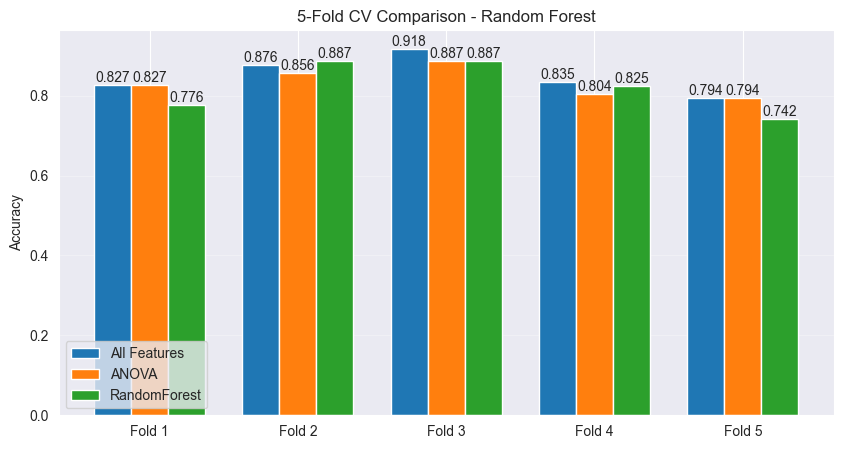

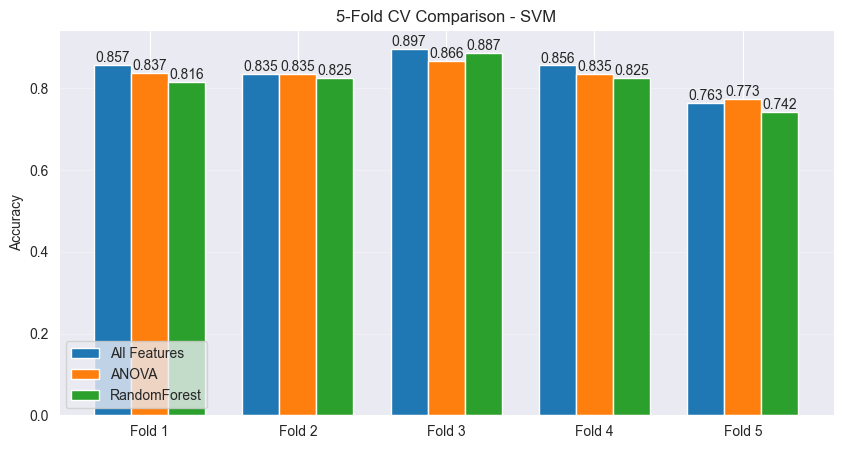

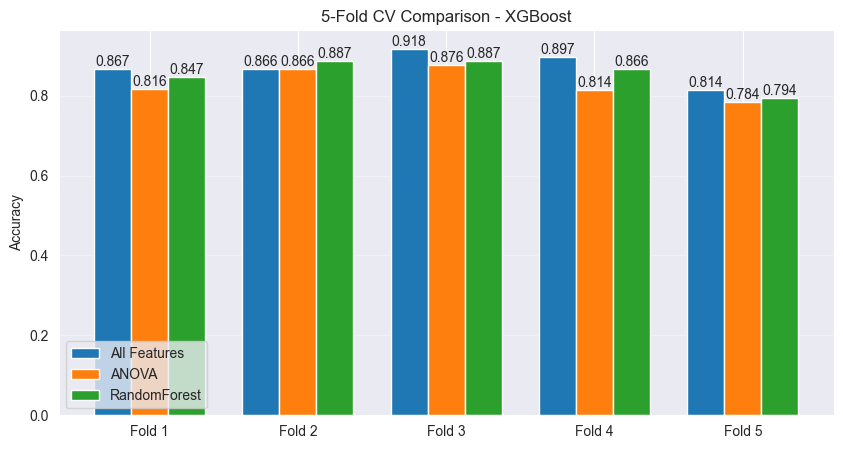

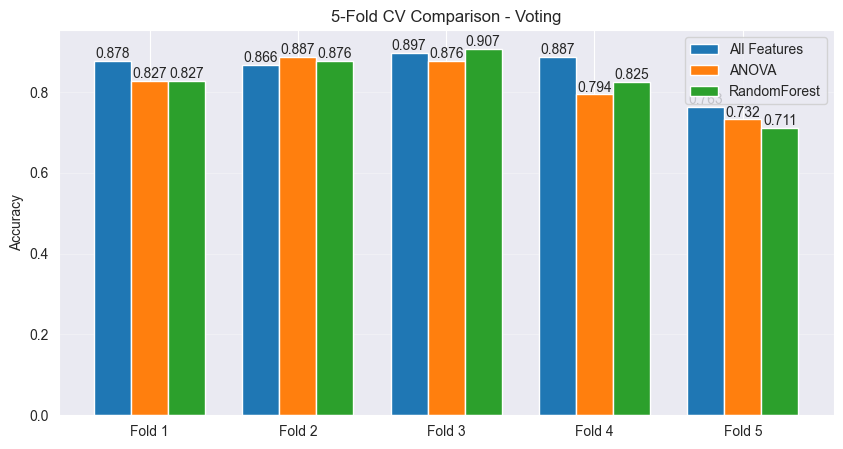

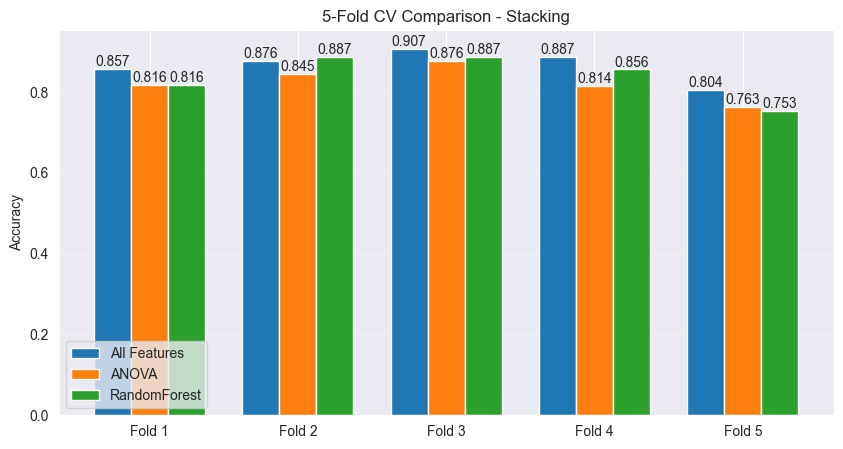

In [139]:
folds = np.arange(1, 6)
x = np.arange(len(folds))
width = 0.25

for model_name in cv_all.keys():

    plt.figure(figsize=(10,5))

    bars1 = plt.bar(
        x - width,
        cv_all[model_name],
        width,
        label='All Features'
    )

    bars2 = plt.bar(
        x,
        cv_anova[model_name],
        width,
        label='ANOVA'
    )

    bars3 = plt.bar(
        x + width,
        cv_mutual[model_name],
        width,
        label='RandomForest'
    )

    plt.bar_label(bars1, fmt='%.3f')
    plt.bar_label(bars2, fmt='%.3f')
    plt.bar_label(bars3, fmt='%.3f')

    plt.xticks(x, [f'Fold {i}' for i in folds])

    plt.ylabel("Accuracy")
    plt.title(f"5-Fold CV Comparison - {model_name}")
    plt.legend()
    plt.grid(axis='y', alpha=0.3)

    plt.show()

### Combine 3L

In [140]:
cv_all = {}
cv_anova = {}
cv_mutual = {}

for name, model in model3l_without_selector.items():
    cv_all[name] = cross_val_score(
        model,
        X_df_cb3,
        y_train_3l,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

for name, model in model3l_with_anova_selector.items():
    cv_anova[name] = cross_val_score(
        model,
        X_df_cb3,
        y_train_3l,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

for name, model in model3l_with_rf_selector.items():
    cv_mutual[name] = cross_val_score(
        model,
        X_df_cb3,
        y_train_3l,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )

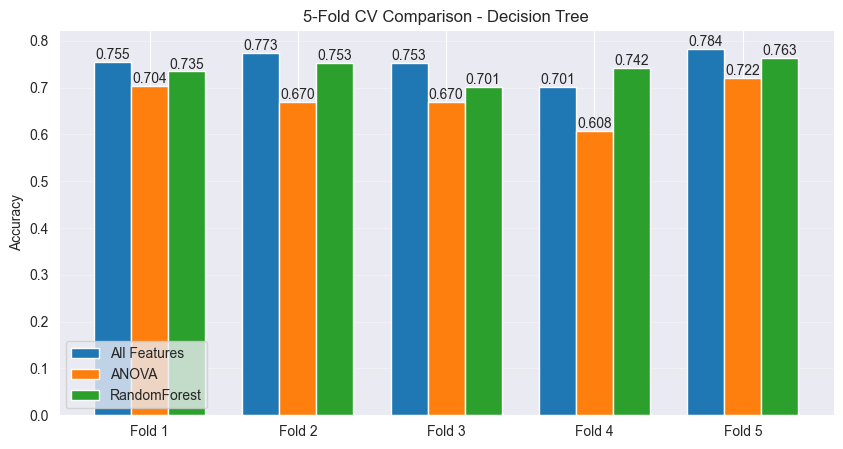

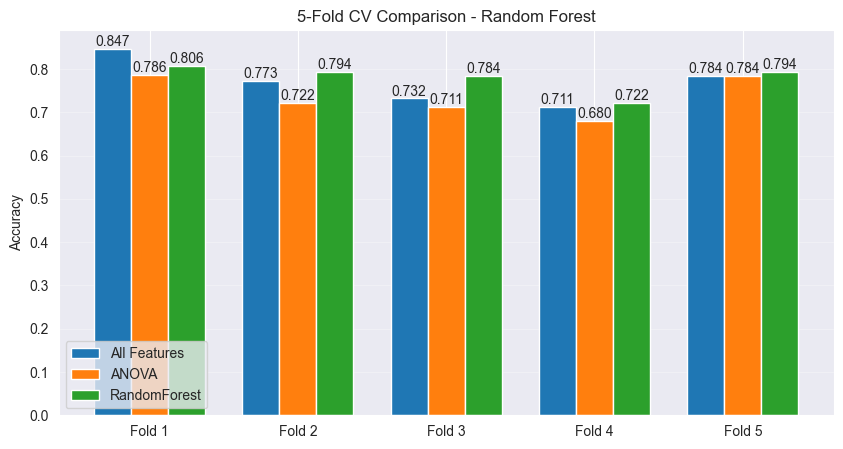

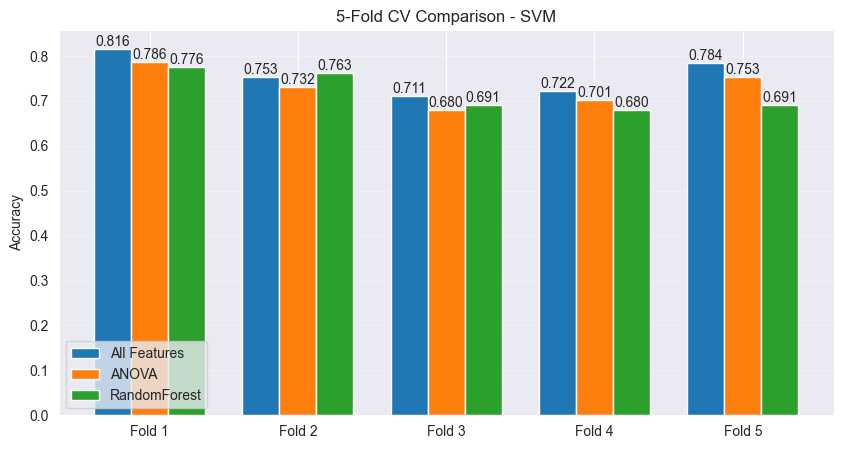

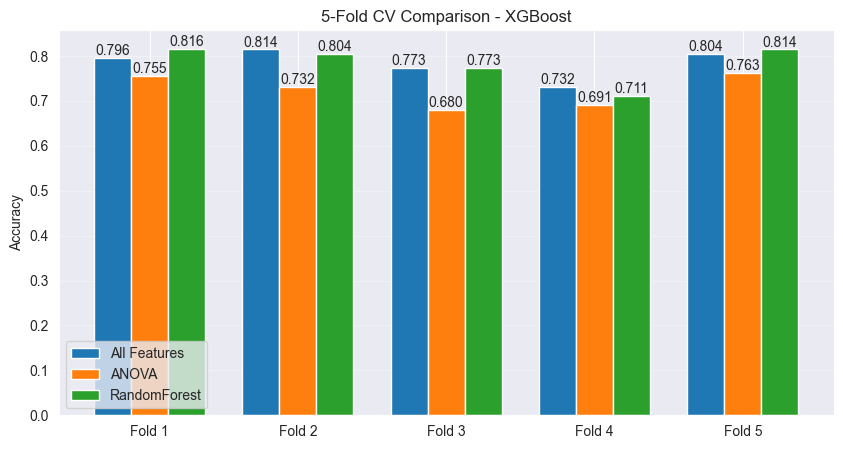

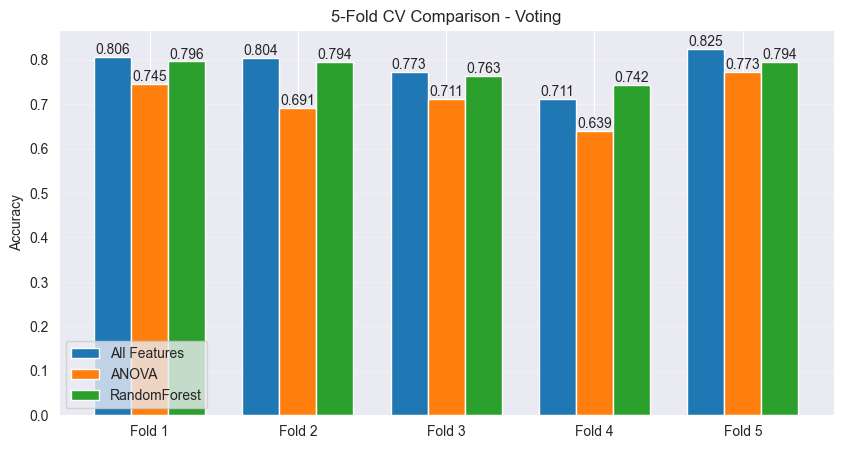

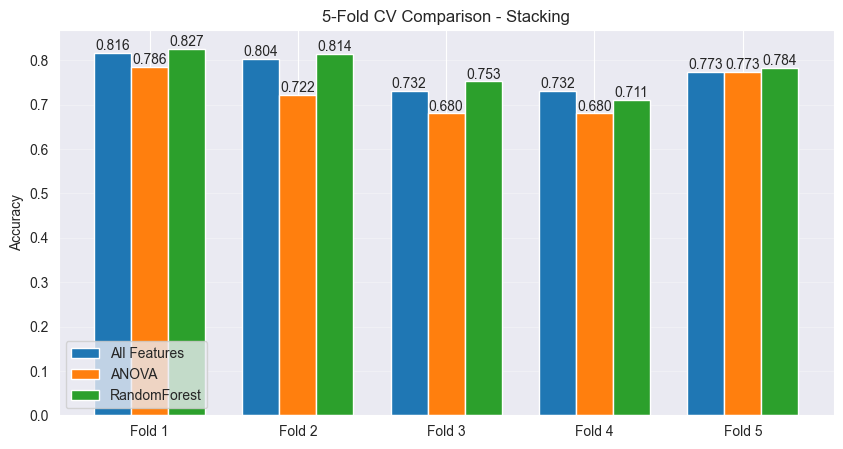

In [141]:
folds = np.arange(1, 6)
x = np.arange(len(folds))
width = 0.25

for model_name in cv_all.keys():

    plt.figure(figsize=(10,5))

    bars1 = plt.bar(
        x - width,
        cv_all[model_name],
        width,
        label='All Features'
    )

    bars2 = plt.bar(
        x,
        cv_anova[model_name],
        width,
        label='ANOVA'
    )

    bars3 = plt.bar(
        x + width,
        cv_mutual[model_name],
        width,
        label='RandomForest'
    )

    plt.bar_label(bars1, fmt='%.3f')
    plt.bar_label(bars2, fmt='%.3f')
    plt.bar_label(bars3, fmt='%.3f')

    plt.xticks(x, [f'Fold {i}' for i in folds])

    plt.ylabel("Accuracy")
    plt.title(f"5-Fold CV Comparison - {model_name}")
    plt.legend()
    plt.grid(axis='y', alpha=0.3)

    plt.show()

# Labeling

In [142]:
def create_preprocessor(X, cat_features=None, special_num_features=None):

    if cat_features is None:
        cat_features = []

    if special_num_features is None:
        special_num_features = []

    # Các cột số thông thường
    num_features = [
        col for col in X.columns
        if col not in cat_features + special_num_features
    ]

    # Pipeline cho cột phân loại
    cat_transformer = Pipeline([
        ('encoder', OrdinalEncoder())
    ])

    # Pipeline cho cột số đặc biệt (SES)
    special_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # Pipeline cho các cột số còn lại
    num_transformer = Pipeline([
        ('imputer', KNNImputer(n_neighbors=5)),
        ('scaler', StandardScaler())
    ])

    transformers = []

    if cat_features:
        transformers.append(
            ('cat', cat_transformer, cat_features)
        )

    if special_num_features:
        transformers.append(
            ('special', special_transformer, special_num_features)
        )

    if num_features:
        transformers.append(
            ('num', num_transformer, num_features)
        )

    preprocessor = ColumnTransformer(transformers)

    feature_names = cat_features + special_num_features + num_features

    return preprocessor, feature_names

In [143]:
columns_to_keep = ['Subject ID', 'MRI ID', 'Group_label', 'Visit', 'MR Delay', 'M/F', 'Hand', 'Age', 'EDUC', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF']
df_combined_3a = pd.concat([df_long[columns_to_keep], df_cross[columns_to_keep]], axis=0, ignore_index=True)

In [144]:
df_train = df_combined_3a[df_combined_3a["Group_label"].notna()].copy()
df_missing = df_combined_3a[df_combined_3a["Group_label"].isna()].copy()

In [145]:
print(df_missing.shape)
print(df_missing.head())

(201, 15)
        Subject ID         MRI ID Group_label  Visit  MR Delay M/F Hand  Age  \
376  OAS1_0004_MR1  OAS1_0004_MR1        None      1       NaN   M    R   28   
377  OAS1_0005_MR1  OAS1_0005_MR1        None      1       NaN   M    R   18   
378  OAS1_0006_MR1  OAS1_0006_MR1        None      1       NaN   F    R   24   
379  OAS1_0007_MR1  OAS1_0007_MR1        None      1       NaN   M    R   21   
380  OAS1_0009_MR1  OAS1_0009_MR1        None      1       NaN   F    R   20   

     EDUC  SES  MMSE  CDR  eTIV   nWBV    ASF  
376   NaN  NaN   NaN  NaN  1588  0.803  1.105  
377   NaN  NaN   NaN  NaN  1737  0.848  1.010  
378   NaN  NaN   NaN  NaN  1131  0.862  1.551  
379   NaN  NaN   NaN  NaN  1516  0.830  1.157  
380   NaN  NaN   NaN  NaN  1505  0.843  1.166  


In [146]:
X_train = df_train.drop(columns=[
    'Subject ID',
    'MRI ID',
    'Group_label',
    'Hand',
    'CDR',
    'MR Delay',
    'Visit',
    'ASF'
])

preprocessor, feature_names = create_preprocessor(
    X_train,
    cat_features=['M/F'],
    special_num_features=['SES']
)

X_train_processed = preprocessor.fit_transform(X_train)

In [147]:
X_missing = df_missing.drop(columns=[
    'Subject ID',
    'MRI ID',
    'Group_label',
    'Hand',
    'CDR',
    'MR Delay',
    'Visit',
    'ASF'
])

X_missing_processed = preprocessor.transform(X_missing)

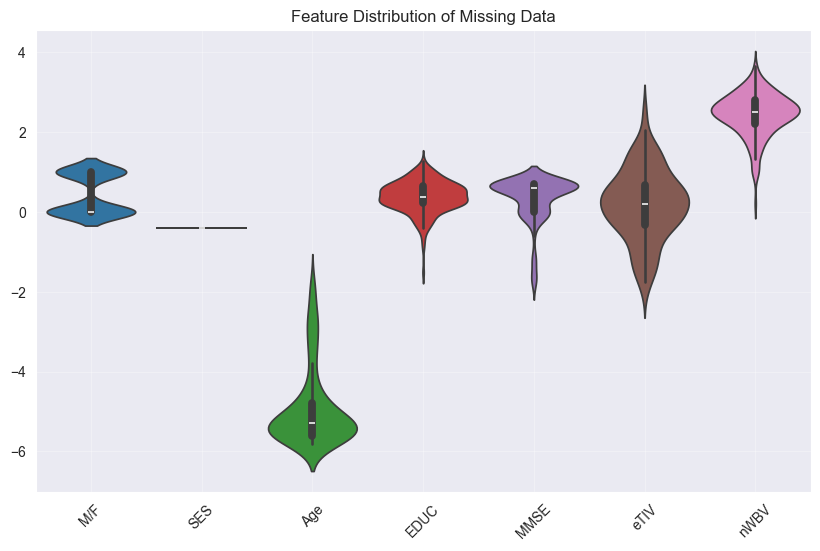

In [148]:
X_missing_df = pd.DataFrame(
    X_missing_processed,
    columns=feature_names
)

plt.figure(figsize=(10,6))

sns.violinplot(data=X_missing_df)

plt.title("Feature Distribution of Missing Data")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

In [149]:
# Encode nhãn
le = LabelEncoder()
y_train = le.fit_transform(df_train["Group_label"])

# Lấy mô hình tốt nhất
best_model = model3l_with_rf_selector["Stacking"]

# Train trên toàn bộ dữ liệu có nhãn
bsmo = best_model.fit(X_train_processed, y_train)


In [150]:
X_missing_processed = preprocessor.transform(X_missing)

y_pred = best_model.predict(X_missing_processed)

df_missing["Group_label"] = le.inverse_transform(y_pred)


In [151]:
print(df_missing["Group_label"].value_counts())

Group_label
Nondemented           188
Very Mild Dementia     13
Name: count, dtype: int64


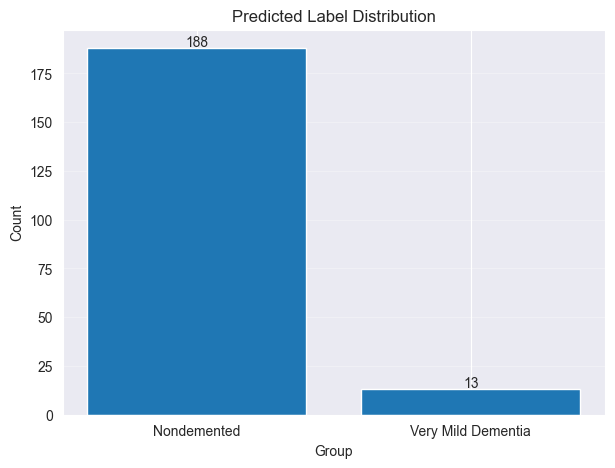

In [152]:
counts = df_missing["Group_label"].value_counts()

plt.figure(figsize=(7,5))

plt.bar(
    counts.index,
    counts.values
)

plt.title("Predicted Label Distribution")
plt.xlabel("Group")
plt.ylabel("Count")

for i, v in enumerate(counts.values):
    plt.text(i, v + 1, str(v), ha="center")

plt.grid(axis="y", alpha=0.3)

plt.show()

In [153]:
df_completed = pd.concat(
    [df_train, df_missing],
    ignore_index=True
)

print(df_completed.shape)
print(df_completed["Group_label"].isna().sum())
print(df_completed["Group_label"].value_counts())

(809, 15)
0
Group_label
Nondemented           529
Very Mild Dementia    206
Demented               74
Name: count, dtype: int64


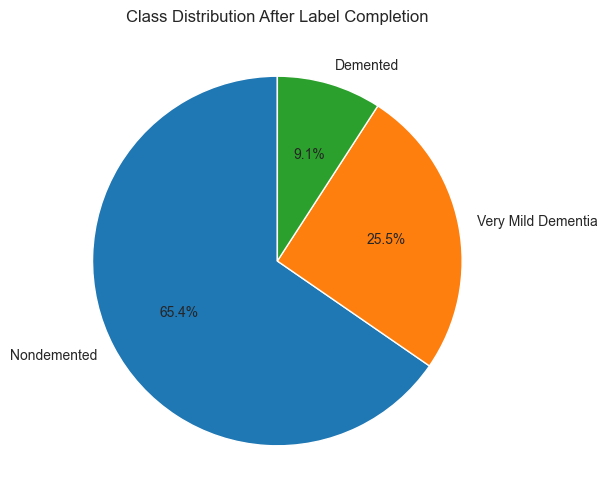

In [154]:
counts = df_completed["Group_label"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Class Distribution After Label Completion")
plt.show()